# Anime recommendation engine for MyAnimeList

This notebook is the whole project, from the raw data to the final recommender. It runs from top to bottom and downloads its own data from Kaggle.

| Part | Content |
|---|---|
| Setup | Libraries and data download |
| A | Build the dataset from the two sources |
| B | Preprocessing |
| C | Exploratory data analysis |
| 1 | Evaluation setup |
| 2 | Non-personalized recommenders (random, popular, demographic) |
| 3 | Collaborative filtering |
| 4 | Content-based |
| 5 | Hybrid |
| 6 | Context-aware |
| 7 | Bandits |
| 8 | Final system and business value |
| 9 | Chatbot |

**How to run it**

- The download needs a Kaggle account and its `kaggle.json` file, as explained in the setup.
- Parts A and B read the anime lists file of 2 GB in chunks of 2 million rows, so they run on a laptop. Part B saves the final dataset to `data/processed`. Part C and Parts 1 to 9 only load that folder, so after one full run they can be run alone after the setup.
- Part 9.2 calls the OpenAI API. The key goes in the OpenAI key cell of the setup. Without a key the LLM cells are skipped.
- A full run takes about 1.5 hours on a MacBook Air.

# Setup

## Libraries

In [1]:
%%capture
%pip install --disable-pip-version-check -q pandas pyarrow matplotlib pycountry kaggle scikit-surprise rexmex "seaborn>=0.13" "plotly>=5" funcsigs six
# recmetrics pins pandas below 2.0, so it is installed without its dependencies on top of current pandas
%pip install --disable-pip-version-check -q --no-deps recmetrics
%pip install --disable-pip-version-check -q sentence-transformers spacy openai
# The small English spaCy model, used for lemmatization and NER as in the S16 notebook
import sys
!{sys.executable} -m spacy download en_core_web_sm

In [2]:
import glob
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycountry

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

## OpenAI key

Part 9.2 uses the OpenAI API. To run it, paste the key between the quotes. Without a key Part 9.2 is skipped.

## Data download

The two sources [1] and [2] are downloaded with the Kaggle API, as in the course notebooks [3, p. 2]. A Kaggle account is needed. In Colab `setup_kaggle` asks for the `kaggle.json` file. On a local machine the file must already be in `~/.kaggle/` or `~/.config/kaggle/`.

The course notebooks download each full dataset with `dataset_download_files` [3, p. 2]. Here only the four files the project uses are downloaded with `dataset_download_file`. In a test run the full 2018 dataset used 9.7 GB of disk and was still not finished, while the four files need about 2.2 GB. Each dataset goes in its own folder, as in the course notebooks. A file that is already downloaded is not downloaded again.

In [4]:
def setup_kaggle():
    from google.colab import files
    uploaded = files.upload()
    !chmod 600 kaggle.json
    %mkdir -p /root/.kaggle/
    %mv kaggle.json /root/.kaggle/

# Important note: If kaggle complains, change the path /root/.kaggle/ to the one
# specified in the error trace (e.g. /root/.config/kaggle/)
if "google.colab" in sys.modules:
    setup_kaggle()

In [5]:
import kaggle
kaggle.api.authenticate()

# Only the four files the project uses are downloaded, because the full 2018 dataset needs much more disk
dataset_path = 'azathoth42/myanimelist'
for file_name in ["users_cleaned.csv", "anime_cleaned.csv", "animelists_cleaned.csv"]:
    if not os.path.exists(f"{dataset_path}/{file_name}"):
        kaggle.api.dataset_download_file(dataset_path, file_name, path=dataset_path)
mal_2018_path = dataset_path

dataset_path = 'hernan4444/anime-recommendation-database-2020'
if not os.path.exists(f"{dataset_path}/anime_with_synopsis.csv"):
    kaggle.api.dataset_download_file(dataset_path, "anime_with_synopsis.csv", path=dataset_path)
mal_2020_path = dataset_path

# Large files arrive as zip files. They are unzipped here, since older versions of the kaggle package cannot do it
for zip_path in glob.glob("*/*/*.zip"):
    with zipfile.ZipFile(zip_path) as zip_file:
        zip_file.extractall(os.path.dirname(zip_path))
    os.remove(zip_path)

! ls $mal_2018_path $mal_2020_path

anime_cleaned.csv      animelists_cleaned.csv users_cleaned.csv
anime_with_synopsis.csv


# Part A. Build the dataset

This part builds the dataset that the rest of the project uses. It only combines the sources. It does not clean or filter anything. All cleaning decisions are made in Part B, after the data quality checks there.

**Why two sources are needed**

The project needs four kinds of data. Ratings for collaborative filtering, item text for content-based models, user attributes for demographic filtering and timestamps for context-aware models and time-based splits [4, slide 3]. No single MyAnimeList dataset has all four.

- The 2018 MyAnimeList Dataset [1] has ratings, user attributes (gender, location, birth date) and timestamps. It has no synopsis text.
- The 2020 Anime Recommendation Database [2] has a synopsis for each anime. It has no user attributes and no timestamps.

Both come from the same website and use the same anime ID. So the synopsis from the 2020 source can be joined to the 2018 data on that ID.

**Files used**

The setup downloads these four files from [1] and [2].

| File | Source | Content |
|---|---|---|
| `users_cleaned.csv` | 2018 | one row per user |
| `animelists_cleaned.csv` | 2018 | one row per user and anime (score, status, dates) |
| `anime_cleaned.csv` | 2018 | one row per anime (metadata) |
| `anime_with_synopsis.csv` | 2020 | one row per anime (synopsis) |

**Output (in `data/merged`)**

- `users.parquet` with one row per user
- `anime.parquet` with one row per anime, metadata plus synopsis
- `interactions/` with one row per user and anime

In [6]:
os.makedirs("data/merged/interactions", exist_ok=True)

## A.1 Users

Only the columns that describe the user are kept. The other columns in the file are totals calculated from the anime lists, which can be recalculated from the interactions if needed.

In [7]:
users = pd.read_csv(
    f"{mal_2018_path}/users_cleaned.csv",
    usecols=["username", "user_id", "gender", "location", "birth_date", "join_date"],
)
users["birth_date"] = pd.to_datetime(users["birth_date"], errors="coerce")
users["join_date"] = pd.to_datetime(users["join_date"], errors="coerce")

print(users.shape)
users.drop(columns=["username"]).head()

(108711, 6)


,user_id,gender,location,birth_date,join_date
0,2255153,Female,"Chennai, India",1990-04-29,2013-03-03
1,37326,Male,"Detroit,Michigan",1991-08-01,2008-02-13
2,228342,Male,"Nayarit, Mexico",1990-12-14,2009-08-31
3,327311,Female,"Malaysia, Kuantan",1998-08-24,2010-05-10
4,5015094,Male,"Nijmegen, Nederland",1999-10-24,2015-11-26


## A.2 Anime and synopsis

This is the join between the two sources. It is a left join on the anime ID, so every anime from the 2018 data is kept. An anime without a match in the 2020 file gets an empty synopsis.

In [8]:
anime = pd.read_csv(
    f"{mal_2018_path}/anime_cleaned.csv",
    usecols=[
        "anime_id", "title", "title_english", "type", "source", "episodes",
        "rating", "score", "scored_by", "members", "popularity", "premiered",
        "studio", "genre", "duration_min", "aired_from_year",
    ],
)

synopsis = pd.read_csv(
    f"{mal_2020_path}/anime_with_synopsis.csv",
    usecols=["MAL_ID", "sypnopsis"],
)
# The column name is misspelled in the original file
synopsis = synopsis.rename(columns={"MAL_ID": "anime_id", "sypnopsis": "synopsis"})

anime = anime.merge(synopsis, on="anime_id", how="left")

matched = anime["synopsis"].notna().sum()
print("Anime in the 2018 data:", len(anime))
print("Anime with a synopsis from the 2020 data:", matched)
print("Share matched:", round(matched / len(anime), 3))
anime.head(3)

Anime in the 2018 data: 6668
Anime with a synopsis from the 2020 data: 6323
Share matched: 0.948


,anime_id,title,title_english,type,source,episodes,rating,score,scored_by,popularity,members,premiered,studio,genre,duration_min,aired_from_year,synopsis
0,11013,Inu x Boku SS,Inu X Boku Secret Service,TV,Manga,12,PG-13 - Teens 13 or older,7.63,139250,231,283882,Winter 2012,David Production,"Comedy, Supernatural, Romance, Shounen",24.0,2012.0,chiyo Shirakiin is the sheltered daughter of a...
1,2104,Seto no Hanayome,My Bride is a Mermaid,TV,Manga,26,PG-13 - Teens 13 or older,7.89,91206,366,204003,Spring 2007,Gonzo,"Comedy, Parody, Romance, School, Shounen",24.0,2007.0,"During his summer vacation, middle school stud..."
2,5262,Shugo Chara!! Doki,Shugo Chara!! Doki,TV,Manga,51,PG - Children,7.55,37129,1173,70127,Fall 2008,Satelight,"Comedy, Magic, School, Shoujo",24.0,2008.0,Now Utau has left Easter and restarted her sin...


## A.3 Interactions

The anime lists file is over 2 GB, so it is read in chunks of 2 million rows and each chunk is saved as its own parquet file.

Two things happen to each chunk.

- The date columns are converted to dates. Values that are not real dates, like `0000-00-00`, become empty.
- The username is replaced by the numeric `user_id` from the users table. This is an inner join, so a row is only kept if its user exists in the users table. Usernames are not saved.

User attributes and anime metadata are not copied into the interactions. They stay in their own tables and can be joined on `user_id` or `anime_id` when needed. This keeps the interactions small enough to load on a laptop.

In [9]:
reader = pd.read_csv(
    f"{mal_2018_path}/animelists_cleaned.csv",
    usecols=[
        "username", "anime_id", "my_watched_episodes", "my_start_date",
        "my_finish_date", "my_score", "my_status", "my_last_updated",
    ],
    chunksize=2_000_000,
)

rows_read = 0
rows_saved = 0

for i, chunk in enumerate(reader):
    rows_read += len(chunk)

    chunk = chunk.rename(columns={
        "my_watched_episodes": "watched_episodes",
        "my_start_date": "start_date",
        "my_finish_date": "finish_date",
        "my_score": "score",
        "my_status": "status",
        "my_last_updated": "last_updated",
    })

    chunk["start_date"] = pd.to_datetime(chunk["start_date"], format="%Y-%m-%d", errors="coerce")
    chunk["finish_date"] = pd.to_datetime(chunk["finish_date"], format="%Y-%m-%d", errors="coerce")
    chunk["last_updated"] = pd.to_datetime(chunk["last_updated"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

    chunk = chunk.merge(users[["username", "user_id"]], on="username", how="inner")
    chunk = chunk.drop(columns=["username"])
    chunk = chunk[[
        "user_id", "anime_id", "score", "status", "watched_episodes",
        "start_date", "finish_date", "last_updated",
    ]]

    chunk.to_parquet(f"data/merged/interactions/part_{i:03d}.parquet", index=False)
    rows_saved += len(chunk)

print("Rows read:", rows_read)
print("Rows saved:", rows_saved)
print("Rows lost in the user join:", rows_read - rows_saved)

Rows read: 31284030
Rows saved: 31284030
Rows lost in the user join: 0


## A.4 Save users and anime

In [10]:
users.drop(columns=["username"]).to_parquet("data/merged/users.parquet", index=False)
anime.to_parquet("data/merged/anime.parquet", index=False)

## A.5 Check the result

The saved files are loaded again to confirm the sizes and to see how much of the data is covered by a synopsis. The sizes come from `basic_stats` of the S19 notebook [5, p. 4], which counts every interaction, also those without a score.

In [11]:
interactions = pd.read_parquet("data/merged/interactions", columns=["user_id", "anime_id"])


# basic_stats from the S19 notebook
def basic_stats(ratings_df, user_col, item_col):
    n_ratings = ratings_df.shape[0]
    n_users = ratings_df[user_col].nunique()
    n_items = ratings_df[item_col].nunique()
    print(f'There are {n_ratings} ratings from {n_users} users to {n_items} items')
    return n_ratings, n_users, n_items


basic_stats(interactions, "user_id", "anime_id");

in_anime_table = interactions["anime_id"].isin(anime["anime_id"])
has_synopsis = interactions["anime_id"].isin(anime.loc[anime["synopsis"].notna(), "anime_id"])

print("Share of interactions whose anime is in the anime table:", round(in_anime_table.mean(), 4))
print("Share of interactions whose anime has a synopsis:", round(has_synopsis.mean(), 4))

There are 31284030 ratings from 108710 users to 6668 items
Share of interactions whose anime is in the anime table: 1.0
Share of interactions whose anime has a synopsis: 0.9908


**Result of the merge**

- No interactions were lost in the user join. All 31,284,030 rows have a matching user.
- 6,323 of the 6,668 anime (94.8%) got a synopsis from the 2020 data. The anime without a match are mostly less popular ones, so they only cover 0.9% of the interactions. 99.1% of the interactions are on an anime with a synopsis.
- The users table has 108,711 users but only 108,710 appear in the interactions. One user has an empty anime list.

Two things to keep in mind for the rest of the project. The data ends in 2018, since the ratings come from the 2018 source. And `last_updated` is when the user last changed the entry, not when they watched or rated the anime.

In [12]:
pd.read_parquet("data/merged/interactions/part_000.parquet").head()

,user_id,anime_id,score,status,watched_episodes,start_date,finish_date,last_updated
0,2255153,21,9,1,586,NaT,NaT,2013-03-03 10:52:53
1,2255153,59,7,2,26,NaT,NaT,2013-03-10 13:54:51
2,2255153,74,7,2,26,NaT,NaT,2013-04-27 16:43:35
3,2255153,120,7,2,26,NaT,NaT,2013-03-03 10:53:57
4,2255153,178,7,2,26,NaT,NaT,2013-03-27 15:59:13


In [13]:
# The merged files are saved, so the large tables of Part A are removed to free memory for Part B
del users, anime, synopsis, interactions, in_anime_table, has_synopsis

# Part B. Preprocessing

This part cleans the merged anime data and creates the dataset that the rest of the project uses.

**The data.** Part A joined the synopsis from the 2020 data [2] to the 2018 data [1] on the anime ID. The merge keeps every interaction and gives a synopsis to 99.1% of them.

**What this part does**

1. Data quality checks that look for problems in the merged data
2. Cleaning, where each step fixes a problem found in the checks
3. A sample of users for modelling, saved to `data/processed`

The exploration of the clean data is in Part C.

In the anime lists, each row is one user and one anime. `score` is the rating from 1 to 10, where 0 means the user did not rate it. `status` is where the anime is on the user's list. The codes are 1 watching, 2 completed, 3 on hold, 4 dropped and 6 plan to watch.

## B.1 Load the data

The interactions table has 31 million rows. To keep it small enough for a laptop, it is loaded one file at a time and the number columns are stored as smaller types. A score from 0 to 10 does not need 64 bits.

In [14]:
small_types = {
    "user_id": "int32",
    "anime_id": "int32",
    "score": "int8",
    "status": "int8",
    "watched_episodes": "int32",
}

def load_interactions(columns):
    parts = []
    for path in sorted(glob.glob("data/merged/interactions/*.parquet")):
        part = pd.read_parquet(path, columns=columns)
        part = part.astype({col: small_types[col] for col in columns if col in small_types})
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

interactions_df = load_interactions(
    ["user_id", "anime_id", "score", "status", "watched_episodes", "last_updated"]
)
anime_df = pd.read_parquet("data/merged/anime.parquet")
users_df = pd.read_parquet("data/merged/users.parquet")

print(f"Memory used by the interactions: {interactions_df.memory_usage().sum() / 1e9:.2f} GB")
interactions_df.head()

Memory used by the interactions: 0.69 GB


,user_id,anime_id,score,status,watched_episodes,last_updated
0,2255153,21,9,1,586,2013-03-03 10:52:53
1,2255153,59,7,2,26,2013-03-10 13:54:51
2,2255153,74,7,2,26,2013-04-27 16:43:35
3,2255153,120,7,2,26,2013-03-03 10:53:57
4,2255153,178,7,2,26,2013-03-27 15:59:13


## B.2 Data quality checks

In [15]:
# basic_stats from the S05 notebook, defined in Part A.5
basic_stats(interactions_df, "user_id", "anime_id");

There are 31284030 ratings from 108710 users to 6668 items


### Duplicates and missing values

In [16]:
print("Duplicate user and anime pairs:", interactions_df.duplicated(subset=["user_id", "anime_id"]).sum())

print()
print("Share of missing values in the interactions")
print(interactions_df.isna().mean().round(3))

Duplicate user and anime pairs: 0

Share of missing values in the interactions
user_id             0.0
anime_id            0.0
score               0.0
status              0.0
watched_episodes    0.0
last_updated        0.0
dtype: float64


In [17]:
# start_date and finish_date are only loaded here to see how often they are filled
dates_df = load_interactions(["start_date", "finish_date"])
print("Share of missing start_date:", round(dates_df["start_date"].isna().mean(), 3))
print("Share of missing finish_date:", round(dates_df["finish_date"].isna().mean(), 3))
del dates_df

Share of missing start_date: 0.85
Share of missing finish_date: 0.816


**`last_updated` is the only usable timestamp.** `start_date` and `finish_date` are missing in 85% and 82% of the rows, while `last_updated` is filled for every row. Time-based evaluation (CVTT) and context-aware models need a timestamp for every rating, since each rating has to be placed before or after a cut-off date [6, pp. 26-27]. Only `last_updated` makes that possible.

One could argue that the start and finish dates are more accurate, since they record when the anime was actually watched. But they exist for less than a fifth of the rows, and the users who fill them in are a self-selected, more engaged group, so a model built on them would not represent the typical user. `last_updated` is used instead, with the known limit that it is the moment of the last edit, not of watching.

In [18]:
print("Missing values in the anime table")
print(anime_df.isna().sum())

Missing values in the anime table
anime_id              0
title                 0
title_english      3230
type                  0
source                0
episodes              0
rating               82
score                 0
scored_by             0
popularity            0
members               0
premiered          3702
studio                0
genre                 4
duration_min          0
aired_from_year       0
synopsis            345
dtype: int64


**Every anime stays in the catalog, including those without a synopsis.** Only four anime have no genre, and 345 (5.2%) have no synopsis because they had no match in the 2020 source. A content-based recommender needs a text column, and combining the text with categorical features is recommended [7, p. 1]. Title, genre and type exist for every anime, so the anime without a synopsis can still be described and recommended.

Removing them would make the text models simpler, but it would also remove anime that users rated, which the collaborative filtering models need. These anime cover only 0.9% of the interactions (Part A.5), so keeping them costs little.

`title_english` is empty for 48% of the anime because many only have a Japanese title, which is in `title`. `premiered` is empty for 56% because only TV series air in a season. The release year is in `aired_from_year`. Neither column is needed, so both are dropped in the cleaning.

In [19]:
print("Missing values in the users table")
print(users_df.isna().sum())

Missing values in the users table
user_id       0
gender        0
location      5
birth_date    0
join_date     0
dtype: int64


### Status codes

In [20]:
interactions_df["status"].value_counts().sort_index()

status
0          167
1      1558384
2     19946276
3      1186648
4      1230250
5            4
6      7362297
33           3
55           1
Name: count, dtype: int64

Codes 0, 5, 33 and 55 are not MyAnimeList statuses. They appear in 175 rows and are removed in the cleaning. Mapping them to the nearest valid status would be guessing, since their meaning is not documented. Most entries are completed anime (64%), followed by plan to watch (24%).

### Dates

First last_updated: 1970-01-01 00:00:00
Last last_updated: 2018-05-22 07:49:06


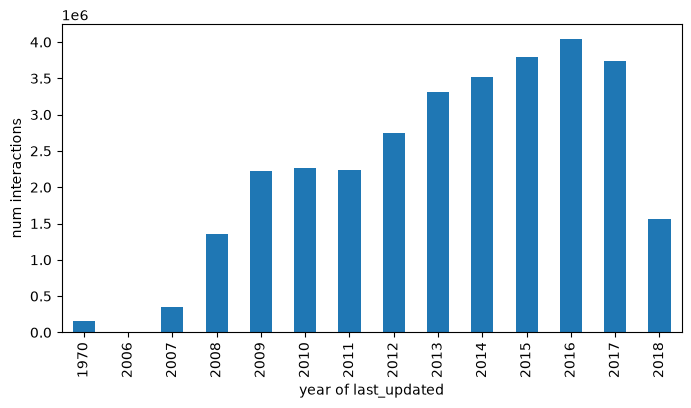

In [21]:
print("First last_updated:", interactions_df["last_updated"].min())
print("Last last_updated:", interactions_df["last_updated"].max())

plt.figure(figsize=(8, 4))
interactions_df.groupby(interactions_df["last_updated"].dt.year).size().plot.bar();
plt.xlabel("year of last_updated");
plt.ylabel("num interactions");

**The 163,231 rows dated 1970-01-01 have no real timestamp.** The data otherwise runs from 2006 to May 2018, and 1 January 1970 is the start of Unix time, the value a missing timestamp gets when it is stored as zero. In a time-based split these rows would all count as the oldest ratings and end up in every training fold [6, p. 27], which would distort the evaluation. They are 0.5% of the data, so they are removed rather than kept only for the models that ignore time. One dataset for every model keeps all results comparable.

### Scores per status

In [22]:
status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}

rated_share = (interactions_df["score"] > 0).groupby(interactions_df["status"]).mean()
rated_share = rated_share[rated_share.index.isin(status_names.keys())]
rated_share.index = rated_share.index.map(status_names)

print(f"Share of interactions without a score: {(interactions_df['score'] == 0).mean():.3f}")
print()
print("Share of interactions with a score, per status")
print(rated_share.round(3))

Share of interactions without a score: 0.387

Share of interactions with a score, per status
status
watching         0.352
completed        0.876
on hold          0.354
dropped          0.513
plan to watch    0.014
Name: score, dtype: float64


**Two kinds of feedback are mixed in the data.** 39% of the interactions have no score, and whether a user rates depends on the status. 88% of completed anime have a score, against only 1.4% of plan to watch entries. The score is explicit feedback, a deliberate opinion that only exists when the user makes the effort to give it. The status is implicit feedback, deduced from what the user does [8, p. 83]. Both are useful, but they have to be kept apart, because a missing score is not a bad score.

The 1.4% of plan to watch entries with a score are a problem. Plan to watch means the user has not seen the anime, so the score cannot be an opinion about watching it. This is fixed in the cleaning.

### User location and age

In [23]:
last_part = users_df["location"].str.split(",").str[-1].str.strip()

print("Different values after the last comma:", last_part.nunique())
print(last_part.value_counts().head(25))

Different values after the last comma: 20060
location
Poland         3562
California     2731
Canada         2272
Brazil         2143
Germany        2084
Philippines    2000
Australia      1625
Russia         1562
Brasil         1490
France         1482
England        1433
Portugal       1407
Indonesia      1370
Texas          1227
Sweden         1217
Florida         996
New York        995
UK              954
Finland         930
Italy           930
USA             927
Norway          851
Romania         781
Netherlands     748
Spain           745
Name: count, dtype: int64


**Location cannot be used for demographic filtering as it is.** Taking the text after the last comma as the country, as in the S05 notebook [9, p. 25], gives 20,060 different values here. Countries, US states, cities, abbreviations and spelling variants are mixed, such as Brazil and Brasil or UK and England. A demographic recommender groups users by their attributes and computes popularity per group [10, p. 2]. With this column most groups would be a single user, so it is cleaned into a country in the cleaning.

In [24]:
end_of_data = interactions_df["last_updated"].max()
age = (end_of_data - users_df["birth_date"]).dt.days / 365.25
print(age.describe().round(1))

count    108711.0
mean         25.0
std           4.6
min           9.4
25%          21.8
50%          24.7
75%          27.8
max          49.4
Name: birth_date, dtype: float64


Age at the end of the data (May 2018) ranges from 9 to 49 years, with a median of 24.7. Birth dates are self-reported and cannot be verified. But there are no impossible values, and a young median fits an anime website, so age is used as it is.

## B.3 Cleaning

Each step below fixes a problem found in the checks. The number of rows is printed after each step so the effect of every decision is visible.

In [25]:
invalid_status = ~interactions_df["status"].isin(status_names.keys())
fake_date = interactions_df["last_updated"].dt.year == 1970

print("Interactions with an invalid status code:", invalid_status.sum())
print("Interactions with the fake 1970 date:", fake_date.sum())

clean_df = interactions_df[~invalid_status & ~fake_date]
print("Interactions left:", len(clean_df))

# The full table is no longer needed, so it is removed to free memory
del interactions_df, invalid_status, fake_date

Interactions with an invalid status code: 175
Interactions with the fake 1970 date: 163231
Interactions left: 31120705


The rows with an invalid status and the rows with the 1970 date are removed, for the reasons in the checks above. Together this is 0.5% of the data.

In [26]:
plan_to_watch_with_score = (clean_df["status"] == 6) & (clean_df["score"] > 0)
print("Plan to watch entries with a score:", plan_to_watch_with_score.sum())

clean_df.loc[plan_to_watch_with_score, "score"] = 0

Plan to watch entries with a score: 104667


**Scores on plan to watch entries are set to 0 instead of removing the rows.** A rating is only useful if it reflects the user's opinion of the item, and even real ratings do not always do that [8, p. 83]. A score on an anime the user has not watched yet is at best an expectation. Removing the 104,667 rows would also lose the implicit signal that the user is interested.

It is possible that some users watched the anime before and listed it as plan to watch by mistake. But the data cannot tell which ones, and the status is the only record of what the user says they did. After this step there is one simple rule for the whole project. A row is an explicit rating when `score` is above 0.

In [27]:
anime_df = anime_df.drop(columns=["title_english", "premiered"])

`title_english` and `premiered` are dropped for the reason given in the anime check. The remaining gaps in the anime table are the 345 missing synopses and 82 missing age ratings.

### Users: country and age

In [28]:
country_names = {}
for country in pycountry.countries:
    country_names[country.name.lower()] = getattr(country, "common_name", country.name)

us_states = [state.name.lower() for state in pycountry.subdivisions.get(country_code="US")]

# Other spellings of country names that do not match the official name. Cities and regions are not matched
aliases = {
    "usa": "United States", "us": "United States", "america": "United States",
    "united states of america": "United States",
    "uk": "United Kingdom", "england": "United Kingdom", "scotland": "United Kingdom",
    "wales": "United Kingdom", "great britain": "United Kingdom",
    "brasil": "Brazil", "russia": "Russian Federation",
    "the netherlands": "Netherlands", "holland": "Netherlands", "nederland": "Netherlands",
    "polska": "Poland", "españa": "Spain", "méxico": "Mexico", "italia": "Italy", "deutschland": "Germany",
    "turkey": "Türkiye", "czech republic": "Czechia",
    "south korea": "Korea, Republic of", "korea": "Korea, Republic of", "vietnam": "Viet Nam",
}

def clean_country(location):
    last = str(location).split(",")[-1].strip().lower()
    if last in aliases:
        return aliases[last]
    if last in country_names:
        return country_names[last]
    if last in us_states:
        return "United States"
    return "Unknown"

users_df["country"] = users_df["location"].apply(clean_country)
print(f"Share of users with a recognised country: {(users_df['country'] != 'Unknown').mean():.3f}")

Share of users with a recognised country: 0.599


In [29]:
# Countries with fewer than 200 users are grouped as Other
country_counts = users_df["country"].value_counts()
small_countries = country_counts[country_counts < 200].index
users_df.loc[users_df["country"].isin(small_countries), "country"] = "Other"

print(users_df["country"].value_counts())

country
Unknown               43560
United States         16632
Poland                 3919
Brazil                 3700
Other                  3562
United Kingdom         3418
Canada                 2358
Philippines            2289
Germany                2158
Netherlands            1826
Russian Federation     1672
Australia              1664
France                 1542
Indonesia              1471
Portugal               1441
Sweden                 1273
Italy                  1095
Spain                  1015
Finland                 945
Norway                  878
Romania                 798
India                   709
Singapore               699
Malaysia                645
Japan                   613
Hungary                 594
Bulgaria                587
Belgium                 568
Türkiye                 546
Greece                  527
Denmark                 501
Argentina               478
Mexico                  470
Lithuania               439
Georgia                 437
New Zealand 

**Each location is matched to a country, and small countries are grouped.** The matching uses the official country list, a list of US states and a short list of other spellings of country names, such as Brasil or UK. Cities and regions are not matched, since that list would never be complete. This gives a country for 59.9% of the users. The rest, like "Earth" or "Wonderland", cannot be matched and becomes Unknown.

Countries with fewer than 200 users become Other. A popularity list per country is only reliable when it rests on enough ratings, which is the same problem the Bayesian average addresses for items with few ratings [11, p. 7]. A list built from a handful of users would mostly reflect their personal taste. Keeping every country would give more detail, but those small groups would produce popularity lists that are mostly noise.

In [30]:
users_df["age"] = age.round().astype(int)
users_df["age_group"] = pd.cut(
    users_df["age"],
    bins=[0, 17, 22, 27, 32, 100],
    labels=["under 18", "18-22", "23-27", "28-32", "33 and over"],
)
print(users_df["age_group"].value_counts().sort_index())

age_group
under 18        3647
18-22          29607
23-27          45998
28-32          23205
33 and over     6254
Name: count, dtype: int64


Age is grouped because demographic filtering computes popularity per group of users [10, p. 2], and a single age has too few users in the sample to give a stable list. The youngest and oldest groups are wider because they have few users.

### Users with too few ratings

In [31]:
clean_ratings_per_user = clean_df[clean_df["score"] > 0].groupby("user_id").size()
eligible_users = clean_ratings_per_user[clean_ratings_per_user >= 10].index

print("Users with at least one rating:", len(clean_ratings_per_user))
print("Users with at least 10 ratings:", len(eligible_users))

Users with at least one rating: 106330
Users with at least 10 ratings: 98177


**Users need at least 10 ratings to be part of the modelling data.** This keeps 98,177 of the 106,330 users with ratings and removes 8,153 (7.7%).

The reason is that each user needs enough test ratings to be evaluated. With 20% of the ratings in the test set, a user with fewer than 10 ratings has at most one or two test ratings. NDCG cannot be computed for a user with a single test item [6, pp. 25-26], and with only two items a ranking can hardly be wrong, which inflates the ranking metrics of every recommender [12, pp. 14-15]. Users with too few ratings also make mean average precision unreliable, and Falk removes users with fewer than 10 ratings for the same reason [8, pp. 240, 326]. The S19 notebook also drops long-tail users below a threshold [5, p. 25].

The counterargument is that these light users are real customers, and the system has to work for them too. They are not ignored. The cold start case is tested in a controlled way by hiding the history of selected users and checking what the system recommends to them. Anime are not filtered. Rare anime are exactly what a content-based model can recommend without ratings, so they stay in the catalog.

## B.4 Sample of users for modelling

In [32]:
sampled_users = np.random.choice(eligible_users, size=5000, replace=False)
sample_df = clean_df[clean_df["user_id"].isin(sampled_users)].reset_index(drop=True)

basic_stats(sample_df, "user_id", "anime_id")
print("Ratings in the sample:", (sample_df["score"] > 0).sum())

There are 1539231 ratings from 5000 users to 6352 items
Ratings in the sample: 977062


In [33]:
# Check that the sample looks like the full data
full_ratings = clean_df.loc[clean_df["score"] > 0, "score"]
sample_ratings = sample_df.loc[sample_df["score"] > 0, "score"]
comparison = pd.DataFrame({
    "full data": full_ratings.value_counts(normalize=True).sort_index(),
    "sample": sample_ratings.value_counts(normalize=True).sort_index(),
})
print(comparison.round(3))
print()
print("Mean rating, full data:", round(full_ratings.mean(), 2), " sample:", round(sample_ratings.mean(), 2))

sample_users_df = users_df[users_df["user_id"].isin(sampled_users)]
print()
print(pd.DataFrame({
    "full data": users_df.loc[users_df["user_id"].isin(eligible_users), "gender"].value_counts(normalize=True),
    "sample": sample_users_df["gender"].value_counts(normalize=True),
}).round(3))

       full data  sample
score                   
1          0.005   0.006
2          0.007   0.007
3          0.012   0.013
4          0.025   0.026
5          0.057   0.058
6          0.111   0.111
7          0.221   0.223
8          0.253   0.253
9          0.180   0.178
10         0.130   0.127

Mean rating, full data: 7.59  sample: 7.56

            full data  sample
gender                       
Male            0.667   0.662
Female          0.329   0.333
Non-Binary      0.005   0.005


**A random sample of 5,000 users is used for modelling.** The full data has 98,177 users and 19 million ratings. Memory-based collaborative filtering compares every user with every other user, so its similarity matrix grows with the square of the number of users. That is 25 million entries for 5,000 users, but about 9.6 billion for 98,177, far more than a laptop can hold. A random sample of users gives a fair estimate of performance while it cuts the computing cost, and the sample has to be drawn by user and not by rating [12, p. 12]. The sample keeps 977,062 ratings. Because users are sampled at random with their full history, every sampled user can be split into train and test.

The sample is representative. The rating distribution, the mean rating (7.56 against 7.59) and the gender split are almost identical to the full data.

The cost is that collaborative filtering learns from less data, and recommenders generally improve with more training data [6, pp. 14-15]. So the absolute results are slightly pessimistic. The comparison between models is not affected, since all of them use the same sample.

## B.5 Save the final dataset

In [34]:
final_users_df = users_df.loc[
    users_df["user_id"].isin(sampled_users),
    ["user_id", "gender", "country", "age", "age_group", "join_date"],
]

os.makedirs("data/processed", exist_ok=True)
sample_df.to_parquet("data/processed/interactions.parquet", index=False)
final_users_df.to_parquet("data/processed/users.parquet", index=False)
anime_df.to_parquet("data/processed/anime.parquet", index=False)

print("interactions:", sample_df.shape)
print("users:", final_users_df.shape)
print("anime:", anime_df.shape)

interactions: (1539231, 6)
users: (5000, 6)
anime: (6668, 15)


**The final dataset in `data/processed`**

- `interactions.parquet` has one row per user and anime, with `score`, `status`, `watched_episodes` and `last_updated`. A row is an explicit rating when `score` is above 0. All other rows are implicit feedback.
- `users.parquet` has gender, country, age, age group and join date for the 5,000 sampled users.
- `anime.parquet` has the full catalog of 6,668 anime with metadata and synopsis.

Things to keep in mind when using the data. `last_updated` is when the user last changed the entry, not when they watched the anime. The data ends in May 2018. 345 anime have no synopsis and 39.5% of the sampled users have the country Unknown (C.5).

In [35]:
# The final dataset is saved, so the large tables of Part B are removed to free memory for the rest
del clean_df, plan_to_watch_with_score, full_ratings, sample_ratings, sample_df

# Part C. Exploratory data analysis

This part explores the clean dataset from Part B, which is the exact data all models use. It has 5,000 randomly sampled users, their full anime lists and the catalog of 6,668 anime.

The data is saved in `data/processed`, so Part C and Parts 1 to 9 also run without Parts A and B.

**What this part covers**

1. Feedback, the long tail and sparsity
2. The definition of a relevant anime, used by every model
3. Time as context
4. The anime and their text
5. The users and whether their tastes differ by group
6. What this means for the business

In [36]:
interactions_df = pd.read_parquet("data/processed/interactions.parquet")
users_df = pd.read_parquet("data/processed/users.parquet")
anime_df = pd.read_parquet("data/processed/anime.parquet")

print("interactions:", interactions_df.shape)
print("users:", users_df.shape)
print("anime:", anime_df.shape)

interactions: (1539231, 6)
users: (5000, 6)
anime: (6668, 15)


**About the data**

- `interactions_df` has one row per user and anime. A row is an explicit rating when `score` is above 0. Rows with score 0 are implicit feedback, where the user added the anime to their list without rating it.
- `status` is 1 watching, 2 completed, 3 on hold, 4 dropped and 6 plan to watch.
- `users_df` and `anime_df` link to the interactions through `user_id` and `anime_id`.
- `last_updated` is when the user last changed the entry, not when they watched the anime.

## C.1 Feedback
### Explicit and implicit feedback

In [37]:
status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}

status_share = interactions_df["status"].map(status_names).value_counts(normalize=True)
print(status_share.round(3))
print()
print(f"Share of interactions with a score: {(interactions_df['score'] > 0).mean():.3f}")

status
completed        0.637
plan to watch    0.237
watching         0.049
dropped          0.040
on hold          0.037
Name: proportion, dtype: float64

Share of interactions with a score: 0.635


**Every user has both explicit and implicit feedback.** 64% of the entries are completed anime and 24% are plan to watch, and 63.5% of all entries have a score. The score is explicit feedback, a clear opinion but one that needs effort from the user. The status is implicit feedback, which is more abundant but harder to interpret [13, slide 10]. Having both means the project can build and evaluate recommenders on each type, which is one of the advanced criteria in the A4 brief [10, p. 1]. How the status is turned into a 0 or 1 label is decided and justified in Part 1.2.

One could argue that only the scores are needed, since they are the clearer signal. But 36.5% of the entries have no score, and most of them are plan to watch entries that show what users want next. Ignoring them would throw away a third of the behaviour in the data.

### Ratings

There are 977062 ratings from 5000 users to 6037 items
Mean rating: 7.56
Median rating: 8


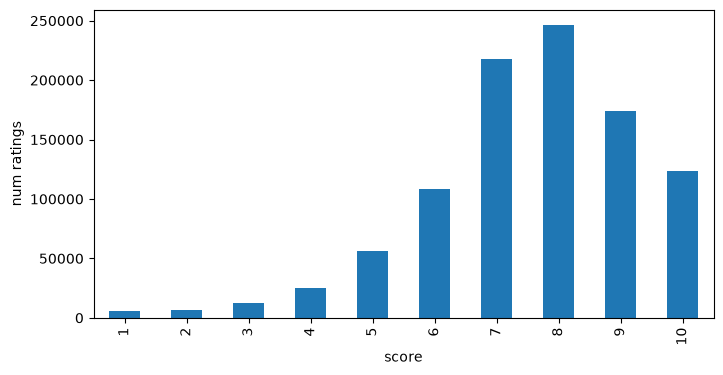

In [38]:
ratings_df = interactions_df[interactions_df["score"] > 0]

# basic_stats from the S05 notebook, defined in Part A.5
n_ratings, n_users, n_items = basic_stats(ratings_df, "user_id", "anime_id")
print(f"Mean rating: {ratings_df['score'].mean():.2f}")
print(f"Median rating: {ratings_df['score'].median():.0f}")

plt.figure(figsize=(8, 4))
ratings_df.groupby("score").size().plot.bar();
plt.ylabel("num ratings");

**The ratings are strongly positive, and this affects how every model must be evaluated.** The mean rating is 7.56 and the median is 8, while scores from 1 to 4 make up only 5.1% of all ratings.

The main reason is selection. Users choose what to watch and mostly pick anime they expect to like, so the ratings that would exist for randomly chosen anime are largely missing [14, p. 109] [15, slide 13]. The consequence for evaluation is that even a random ranking puts mostly well-rated anime near the top, and the difference between an 8 and a 9 barely moves NDCG [12, p. 17]. Ranking metrics therefore have to be read against the random baseline, never on their own. For prediction, it means most of the information lies between 7 and 9, so an RMSE close to 1 is already a meaningful error on this scale.

An alternative explanation is that MyAnimeList users are simply generous. That cannot be separated from selection with this data, but both explanations lead to the same consequence for evaluation. Users do discriminate between anime, since the average per anime ranges from 1.0 to 10.0, so the scores still carry information.

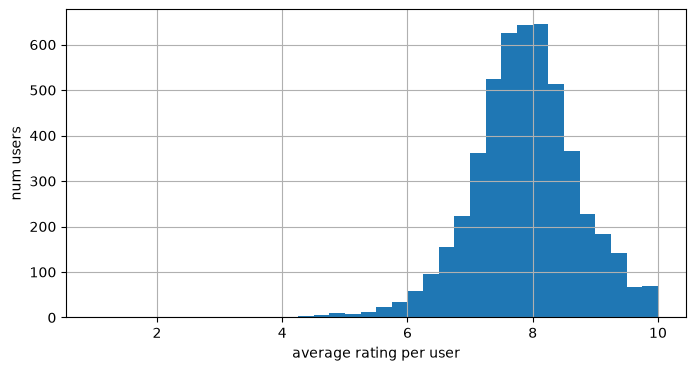

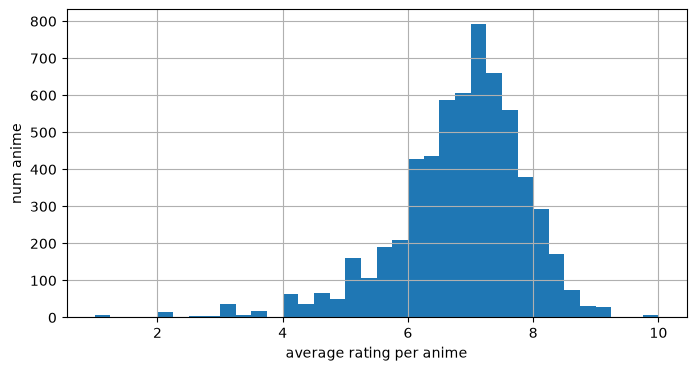

In [39]:
plt.figure(figsize=(8, 4))
ratings_df.groupby("user_id")["score"].mean().hist(bins=np.arange(1, 10.25, 0.25));
plt.xlabel("average rating per user");
plt.ylabel("num users");

plt.figure(figsize=(8, 4))
ratings_df.groupby("anime_id")["score"].mean().hist(bins=np.arange(1, 10.25, 0.25));
plt.xlabel("average rating per anime");
plt.ylabel("num anime");

**Users differ in how generous they are, and anime with few ratings have unreliable averages.** Half of the users have an average between 7.38 and 8.39, but 135 users average 9.5 or more and 101 average 6 or less. A 7 from a generous user means something different from a 7 from a strict one. Much of the variation in ratings is explained by these user and item biases rather than by personal taste, and models such as SVD estimate them explicitly [14, p. 109]. This is one reason SVD is expected to beat a plain popularity ranking.

The averages per anime have a long left side. Anime with fewer than 10 ratings average 5.99 with a spread of 1.43, while anime with at least 500 ratings average 7.85 with a spread of only 0.53. An average from a few users depends heavily on who those users are. A popularity recommender that ranks anime by their plain average will therefore be pulled towards anime with very few ratings, which is why the Bayesian average is tested in Part 2 [10, p. 2].

### Long tail and sparsity

The 20% most rated anime have 71.6% of all ratings
Median number of ratings per anime: 53.0
Anime with fewer than 10 ratings: 1190
Anime in the catalog without any rating in the sample: 631


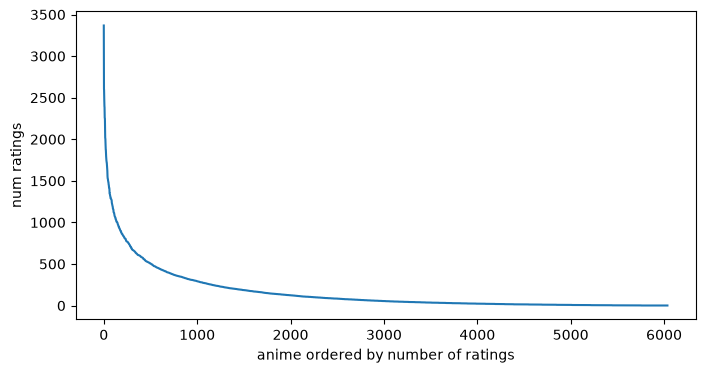

In [40]:
# Drawn by hand, since recmetrics.long_tail_plot from the S05 notebook needs seaborn below 0.12
ratings_per_anime = ratings_df.groupby("anime_id").size().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.plot(range(len(ratings_per_anime)), ratings_per_anime.values);
plt.xlabel("anime ordered by number of ratings");
plt.ylabel("num ratings");

top_20_share = ratings_per_anime.iloc[: int(len(ratings_per_anime) * 0.2)].sum() / ratings_per_anime.sum()
print(f"The 20% most rated anime have {top_20_share:.1%} of all ratings")
print("Median number of ratings per anime:", ratings_per_anime.median())
print("Anime with fewer than 10 ratings:", (ratings_per_anime < 10).sum())
print("Anime in the catalog without any rating in the sample:", len(anime_df) - n_items)

**A small part of the catalog receives most of the attention.** The 20% most rated anime receive 71.6% of all ratings, while the median anime has only 53 ratings in the sample. 1,190 anime have fewer than 10 ratings, and 631 anime in the catalog have no rating at all from the sampled users.

This long tail has three consequences [14, pp. 32-33]. Popular anime are easy to recommend but give the user little that is new. Predictions for anime in the tail are harder because there is little data about them. And many algorithms drift towards popular anime, which lowers coverage and diversity. This is why coverage, personalization and diversity are measured next to accuracy in this project. The 631 unrated anime are the cold-start problem for items. A recommender cannot score an anime it has no training data about [6, p. 7], and in this project even the content-based model only scores anime with at least one training rating. These anime therefore never reach the homepage, which is a limitation of the final system (Part 8).

One could argue that rarely rated anime are rare because they are less appealing, so pushing them would lower satisfaction. There is a real trade-off between accurate recommendations and surprising ones [16, slide 11]. The goal is not to recommend the tail to everyone, but to show each tail anime to the users most likely to enjoy it, which is what personalized models are designed to do.

In [41]:
ratings_per_user = ratings_df.groupby("user_id").size()
print(ratings_per_user.describe().round(0))

sparsity = 1 - n_ratings / (n_users * n_items)
print()
print(f"The user-anime rating matrix is {sparsity:.2%} empty")

count    5000.0
mean      195.0
std       229.0
min        10.0
25%        56.0
50%       124.0
75%       249.0
max      3033.0
dtype: float64

The user-anime rating matrix is 96.76% empty


**The rating matrix is sparse, even after the filtering in Part B.** Every sampled user has at least 10 ratings and the median user has 124, yet 96.76% of the user and anime pairs are empty. Users normally rate only a small part of the catalog, so rating data is sparse by nature [13, slide 18]. The minimum of 10 ratings per user from Part B at least gives every user some history for collaborative filtering. But two users still share few anime on average, which matters for memory-based models. They compare users on the anime both have rated, and similarities based on very few common anime are unreliable [14, pp. 37-38]. The minimum number of anime in common (`min_support`) is therefore a key setting to test in Part 3.

## C.2 What counts as a relevant anime

Precision, recall, MAP and the bandits need a yes or no answer to the question "did the user like this anime?". This section defines that answer once, so every model in the project is evaluated in the same way.

In [42]:
for threshold in [7, 8, 9]:
    share = (ratings_df["score"] >= threshold).mean()
    print(f"Share of ratings with a score of {threshold} or more: {share:.3f}")

Share of ratings with a score of 7 or more: 0.780
Share of ratings with a score of 8 or more: 0.557
Share of ratings with a score of 9 or more: 0.304


In [43]:
relevant_score = 8

relevant_df = ratings_df[ratings_df["score"] >= relevant_score]
relevant_per_user = relevant_df.groupby("user_id").size().reindex(users_df["user_id"], fill_value=0)

print(relevant_per_user.describe().round(0))
print("Users with no relevant anime:", (relevant_per_user == 0).sum())

count    5000.0
mean      109.0
std       119.0
min         0.0
25%        34.0
50%        71.0
75%       141.0
max      1470.0
dtype: float64
Users with no relevant anime: 1


**A score of 8 or more is the best definition of a relevant anime for this project.** Precision, recall, MAP and the bandits need a yes or no answer to whether a user liked an anime, and that boundary has to be decided explicitly [8, p. 227].

The threshold has to separate liked anime from merely watched ones. Because the ratings are so positive, a low threshold fails to do that. A score of 7 or more would make 78% of all ratings relevant, so even a random list would be mostly relevant and the metrics would no longer separate good models from bad ones [12, p. 17]. A score of 9 or more keeps only 30%, which would count many anime the user clearly liked as failures. A score of 8 is the median rating, so relevant means better than a typical rating for this audience. With this rule the median user has 71 relevant anime and only one user has none, so almost every user can be evaluated.

The strongest alternative is a threshold per user, for example anything above the user's own average, since a relevance boundary can also be defined relative to the user's mean [8, p. 227]. It would correct for the user bias shown above. It was not chosen because the user's average must be computed on the training data only, or it leaks test ratings into the label, and that is easy to get wrong across several parts of the notebook. Every part therefore uses `relevant_score = 8`, and the user bias it ignores is accepted as a limitation.

## C.3 Time as context

              mean   count
last_updated              
2006          7.86      85
2007          7.61   11809
2008          7.66   50140
2009          7.71   72030
2010          7.67   77034
2011          7.67   75413
2012          7.63   86744
2013          7.63  108655
2014          7.52  113774
2015          7.54  117089
2016          7.48  120550
2017          7.41  104223
2018          7.30   39516


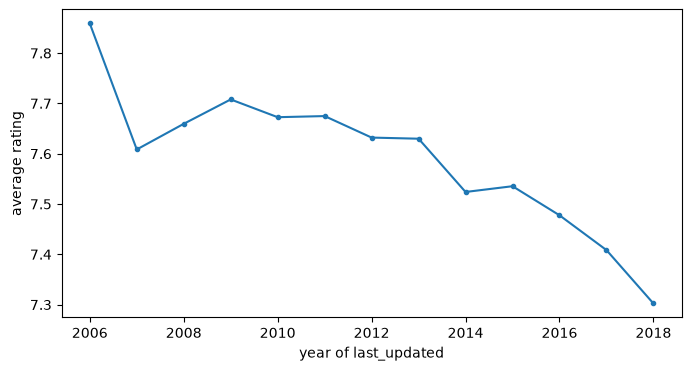

In [44]:
per_year = ratings_df.groupby(ratings_df["last_updated"].dt.year)["score"].agg(["mean", "count"])
print(per_year.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
per_year["mean"].plot(marker=".", ax=ax);
ax.set_xlabel("year of last_updated");
ax.set_ylabel("average rating");

**Ratings fall over time, so the evaluation must include a split by time.** The average rating drops steadily from 7.71 in 2009 to 7.30 in 2018. The data does not show why. It could be a changing audience as the site grew, or users lowering old scores when they edit their lists.

Whatever the cause, a model trained on older ratings will predict too high for recent ones. A random split hides this, because it mixes past and future ratings in training. Cross-validation through time trains on the past and tests on later data, which is how the system would be used in production [6, pp. 26-27]. The trend also makes the year a candidate context for the context-aware models, for example by training on recent data only, which is a form of contextual pre-filtering [4, slides 14-15].

The counterargument is that 2018 only covers five months and the earliest years have few ratings, so the extremes are less reliable. But the decline is steady across 2012 to 2017, the years with the most ratings, so it is not driven by the edges.

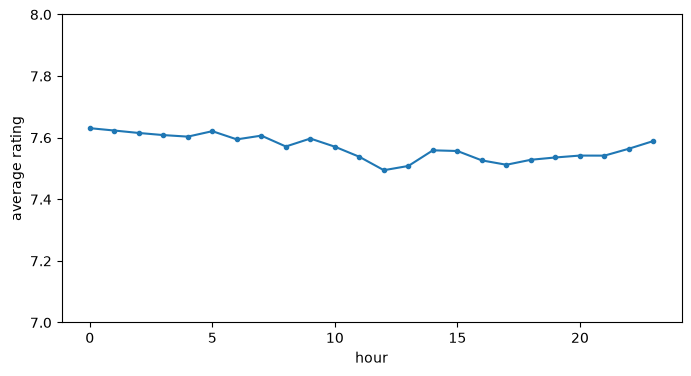

In [45]:
plt.figure(figsize=(8, 4))
ratings_df.groupby(ratings_df["last_updated"].dt.hour)["score"].mean().plot(marker=".");
plt.xlabel("hour");
plt.ylabel("average rating");
plt.ylim(7, 8);

**The hour of the day is not a useful context here.** The average rating barely moves across the day. The time zone of `last_updated` is also unknown, and the users live in many countries. When ratings from different time zones are mixed, the hour no longer reflects the user's local time, which makes time-of-day context unreliable [17, p. 30]. It is therefore left out of the context-aware models.

## C.4 The anime

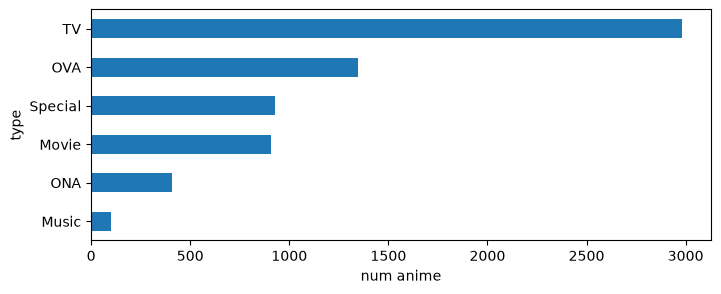

In [46]:
anime_df.groupby("type").size().sort_values().plot.barh(figsize=(8, 3));
plt.xlabel("num anime");

Number of different genres: 43
Average number of genres per anime: 3.6


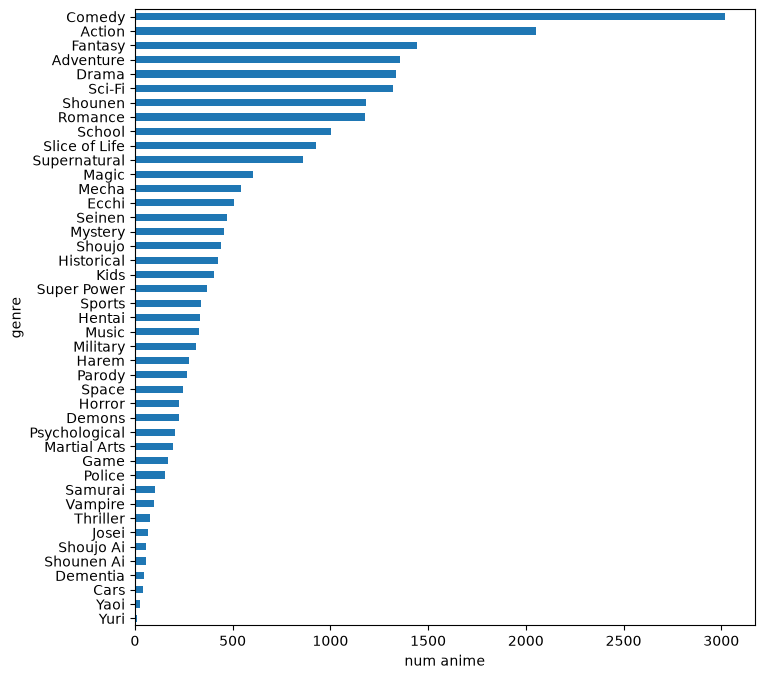

In [47]:
genres = anime_df["genre"].dropna().str.split(", ").explode()

plt.figure(figsize=(8, 8))
genres.value_counts().sort_values().plot.barh();
plt.xlabel("num anime");

print("Number of different genres:", genres.nunique())
print("Average number of genres per anime:", round(anime_df["genre"].dropna().str.split(", ").str.len().mean(), 1))

There are 43 genres and each anime has 3.6 on average. Comedy and Action are the most common. Genres serve two purposes in the project. They are item features for the content-based models, and they are the metadata the diversity metric needs, since intra-list similarity compares the categories of the recommended items [18, pp. 26-27]. TV series are the largest type, followed by OVA, specials and movies.

count    6323.0
mean       88.0
std        62.0
min         2.0
25%        33.0
50%        80.0
75%       137.0
max       487.0
Name: synopsis, dtype: float64
Anime without a synopsis: 345
Synopses with fewer than 20 words: 1105

10    The second part of Junjou Romantica continuing...
12                 Second season of Sekaiichi Hatsukoi.
56    OVA of Diabolik Lovers included with the upcom...
57            Based on the characters created by Study.
59                     Picture dramas from the DVD/BDs.


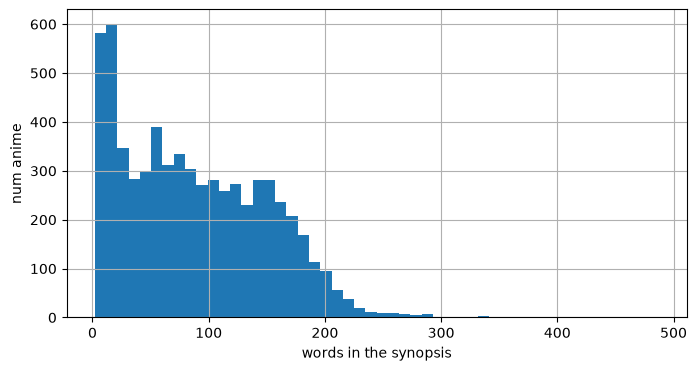

In [48]:
synopsis_words = anime_df["synopsis"].dropna().str.split().str.len()

plt.figure(figsize=(8, 4))
synopsis_words.hist(bins=50);
plt.xlabel("words in the synopsis");
plt.ylabel("num anime");

print(synopsis_words.describe().round(0))
print("Anime without a synopsis:", anime_df["synopsis"].isna().sum())
print("Synopses with fewer than 20 words:", (synopsis_words < 20).sum())
print()
print(anime_df.loc[synopsis_words[synopsis_words < 20].index, "synopsis"].head(5).to_string())

**The synopsis alone is not enough for every anime, so the content-based models should combine it with title and genres.** The median synopsis has 80 words, which is enough for TF-IDF and BERT. But 345 anime have no synopsis and 1,105 synopses have fewer than 20 words. Most of the short ones are sequels or extras described only in relation to another title, like the examples above, so they say almost nothing about the content. Complementing the text with categorical features is the recommended way to strengthen a content-based model [7, p. 1].

One could argue that BERT captures meaning even from short texts. But a sentence like "Second season of Sekaiichi Hatsukoi" contains no information about the story or genre, whatever model reads it. Adding the genres gives every anime a minimum description.

## C.5 The users
### Who the users are

In [49]:
print(users_df["gender"].value_counts())
print()
print(users_df["age_group"].value_counts().sort_index())
print()
print(users_df["country"].value_counts().head(10))

gender
Male          3310
Female        1667
Non-Binary      23
Name: count, dtype: int64

age_group
under 18        179
18-22          1328
23-27          2074
28-32          1123
33 and over     296
Name: count, dtype: int64

country
Unknown               1977
United States          758
Brazil                 184
Poland                 172
Other                  168
United Kingdom         158
Canada                 128
Germany                 97
Netherlands             93
Russian Federation      89
Name: count, dtype: int64


**The audience is young and mostly male, which matters for fairness.** Two thirds of the sampled users are male, one third female and 23 non-binary. Most are between 18 and 32. Country is Unknown for 39.5% of the users, and most known countries have fewer than 200 users in the sample.

A recommender trained on this data learns mostly the tastes of young men, and groups with few users get less personal recommendations because there is less data about them. User attributes like age and gender are also personal data, and their use calls for care with privacy and ethics [13, slide 6]. Both points belong in the ethics discussion of the final system.

### Do tastes differ between groups?

Demographic filtering only makes sense if different groups like different anime. The S19 notebook checks the same for context values by comparing the genre shares of each group [5, p. 22]. This is checked in two ways. First the average rating per group, then how much the 10 most liked anime of two groups overlap.

In [50]:
ratings_users_df = ratings_df.merge(users_df, on="user_id")

print(ratings_users_df.groupby("gender")["score"].agg(["mean", "count"]).round(2))
print()
print(ratings_users_df.groupby("age_group", observed=True)["score"].agg(["mean", "count"]).round(2))

            mean   count
gender                  
Female      7.69  240460
Male        7.53  728535
Non-Binary  6.84    8067

             mean   count
age_group                
under 18     7.40   26243
18-22        7.60  241451
23-27        7.62  396836
28-32        7.50  242659
33 and over  7.40   69873


In [51]:
def top_anime(df, n=10):
    liked = df[df["score"] >= relevant_score]
    return liked.groupby("anime_id").size().sort_values(ascending=False).index[:n]

def titles(anime_ids):
    return anime_df.set_index("anime_id").loc[list(anime_ids), "title"].tolist()

top_male = top_anime(ratings_users_df[ratings_users_df["gender"] == "Male"])
top_female = top_anime(ratings_users_df[ratings_users_df["gender"] == "Female"])
print("Anime in both top 10s, male and female:", len(set(top_male) & set(top_female)))
print("Only in the male top 10:", titles(set(top_male) - set(top_female)))
print("Only in the female top 10:", titles(set(top_female) - set(top_male)))

top_young = top_anime(ratings_users_df[ratings_users_df["age_group"] == "under 18"])
top_old = top_anime(ratings_users_df[ratings_users_df["age_group"] == "33 and over"])
print()
print("Anime in both top 10s, under 18 and 33 and over:", len(set(top_young) & set(top_old)))

Anime in both top 10s, male and female: 5
Only in the male top 10: ['Steins;Gate', 'Sword Art Online', 'Tengen Toppa Gurren Lagann', 'Angel Beats!', 'Code Geass: Hangyaku no Lelouch R2']
Only in the female top 10: ['Kuroshitsuji', 'Sen to Chihiro no Kamikakushi', 'Howl no Ugoku Shiro', 'Ouran Koukou Host Club', 'Fullmetal Alchemist']

Anime in both top 10s, under 18 and 33 and over: 1


In [52]:
ratings_genres_df = ratings_users_df.merge(anime_df[["anime_id", "genre"]], on="anime_id")
ratings_genres_df["genre"] = ratings_genres_df["genre"].str.split(", ")
ratings_genres_df = ratings_genres_df.explode("genre")

genre_share = pd.crosstab(ratings_genres_df["genre"], ratings_genres_df["gender"], normalize="columns")
genre_share["female minus male"] = genre_share["Female"] - genre_share["Male"]
print(genre_share.sort_values("female minus male").iloc[[0, 1, 2, -3, -2, -1]].round(3))

gender   Female   Male  Non-Binary  female minus male
genre                                                
Ecchi     0.016  0.032       0.016             -0.016
Action    0.081  0.097       0.083             -0.016
Sci-Fi    0.036  0.047       0.037             -0.011
Romance   0.074  0.067       0.061              0.007
Drama     0.075  0.060       0.066              0.015
Shoujo    0.029  0.008       0.022              0.021


**Gender and age groups like clearly different anime, which justifies demographic filtering.** The male and female top 10 share only 5 anime, and the top 10 of users under 18 and users 33 and over share only 1. Men watch relatively more Action, Sci-Fi and Ecchi, and women more Drama, Romance and Shoujo.

A demographic recommender builds a popularity list per group of users [10, p. 2]. That only adds value over a single popularity list if the groups like different things, and these overlaps show that they do. It is especially useful for new users, who can be routed to a demographic or content-based recommender until they have enough history for collaborative filtering. This is the switching approach to hybrid recommenders [13, slide 21].

The counterargument is that the average ratings differ little between groups, only 0.16 points between women and men. But the homepage is about which anime are shown, not about how high they are rated, and the top lists differ a lot. A second concern is that recommending by gender can reinforce stereotypes. That is a real ethical risk, so the demographic recommender should only be a starting point that personal history replaces as soon as it exists.

### Europe compared with North America

The company could grow in Europe. That only calls for a regional approach if European users like different anime than the current core market, North America. Countries are grouped into the two regions below. Georgia is left out, because most users who wrote Georgia live in the US state, not the country.

In [53]:
europe = [
    "Austria", "Belgium", "Bulgaria", "Croatia", "Czechia", "Denmark", "Finland", "France",
    "Germany", "Greece", "Hungary", "Ireland", "Italy", "Lithuania", "Netherlands", "Norway",
    "Poland", "Portugal", "Romania", "Russian Federation", "Serbia", "Slovakia", "Spain",
    "Sweden", "Ukraine", "United Kingdom",
]
north_america = ["United States", "Canada"]

users_df["region"] = "Other or unknown"
users_df.loc[users_df["country"].isin(europe), "region"] = "Europe"
users_df.loc[users_df["country"].isin(north_america), "region"] = "North America"
print(users_df["region"].value_counts())

ratings_users_df = ratings_df.merge(users_df, on="user_id")
print()
print(ratings_users_df.groupby("region")["score"].agg(["mean", "count"]).round(2))

region
Other or unknown    2834
Europe              1280
North America        886
Name: count, dtype: int64

                  mean   count
region                        
Europe            7.45  269894
North America     7.59  157453
Other or unknown  7.62  549715


In [54]:
top_europe = top_anime(ratings_users_df[ratings_users_df["region"] == "Europe"])
top_america = top_anime(ratings_users_df[ratings_users_df["region"] == "North America"])
print("Anime in both top 10s, Europe and North America:", len(set(top_europe) & set(top_america)))
print("Only in the European top 10:", titles(set(top_europe) - set(top_america)))
print("Only in the North American top 10:", titles(set(top_america) - set(top_europe)))

ratings_genres_df = ratings_users_df.merge(anime_df[["anime_id", "genre"]], on="anime_id")
ratings_genres_df["genre"] = ratings_genres_df["genre"].str.split(", ")
ratings_genres_df = ratings_genres_df.explode("genre")
region_genre_share = pd.crosstab(ratings_genres_df["genre"], ratings_genres_df["region"], normalize="columns")
region_genre_share["Europe minus North America"] = region_genre_share["Europe"] - region_genre_share["North America"]
print()
print("Largest difference in genre share:", round(region_genre_share["Europe minus North America"].abs().max(), 3))

Anime in both top 10s, Europe and North America: 7
Only in the European top 10: ['Elfen Lied', 'Steins;Gate', 'Shingeki no Kyojin']
Only in the North American top 10: ['Cowboy Bebop', 'Tengen Toppa Gurren Lagann', 'Fullmetal Alchemist']

Largest difference in genre share: 0.006


European and North American users like largely the same anime. Their top 10s share 7 anime and no genre share differs by more than 0.6 percentage points. For comparison, the male and female top 10s share 5 and the youngest and oldest age groups share only 1. Europeans rate slightly lower (7.45 against 7.59), which a model with user bias terms already absorbs.

For a growth plan in Europe this is good news. The same recommender works for European users without a separate model, so expanding there needs no extra development. What matters for new European users is the cold start, where gender and age are much stronger signals than region. Region is a weak signal in this data, partly because 39.5% of users have an unknown country.

## C.6 What this means for the business

The company currently shows anime at random. As a first indication of what a recommender could add, the cell below compares two simple strategies for showing 10 anime to each user. The first is random, like today. The second is the 10 most liked anime overall. A hit is an anime the user rated 8 or more.

This is computed on all data, so the popular list has seen the same ratings it is tested on. It is not a proper evaluation, which the models do later with a train and test split. It only shows the size of the gap.

In [55]:
n_catalog = len(anime_df)
hits_random = (10 * relevant_per_user / n_catalog).mean()

top_10_overall = top_anime(ratings_df)
hits_popular = relevant_df[relevant_df["anime_id"].isin(top_10_overall)].groupby("user_id").size()
hits_popular = hits_popular.reindex(users_df["user_id"], fill_value=0)

print(f"Average hits out of 10, random display: {hits_random:.2f}")
print(f"Average hits out of 10, most liked anime: {hits_popular.mean():.2f}")
print(f"Users with at least one hit, most liked anime: {(hits_popular > 0).mean():.1%}")

Average hits out of 10, random display: 0.16
Average hits out of 10, most liked anime: 4.14
Users with at least one hit, most liked anime: 92.7%


**Random display almost never shows users something they like, which is the core business case for a recommender.** Random display gives on average 0.16 anime out of 10 that the user likes. Showing the 10 most liked anime gives 4.14, and 92.7% of users find at least one anime they like. That is about 25 times more than random. The reason is the long tail. Most of the catalog is anime few people want, so a random pick almost always misses.

This number is an upper bound for the popular list, since it is computed on the same data it is tested on, and it counts anime the users have already watched. Offline evaluation in general can only count anime users already found by themselves [19, pp. 96-97]. The proper comparison, on unseen anime and on a test set, is done in Parts 1 and 2.

The obvious objection is that if popularity already beats random this much, personalization may not be worth it. But a popular list mostly shows anime the user has already seen. Heavy users have watched the whole top 10, so for them it shows nothing new, and it ignores most of the catalog the company pays for. Personalized models are needed to find new anime for each user. Part 5 shows that a hybrid of popularity and personalized models finds more relevant unseen anime than popularity alone.

**Summary for the project**

- Random display almost never shows users something they like, which is the main business case for a recommender.
- Users mostly rate anime they like, so relevant is defined as a score of 8 or more and ranking metrics are always compared with random.
- A few anime get most of the attention, so models are checked for coverage and diversity, not only accuracy.
- Ratings drift down over time, so the evaluation includes a split by time.
- Gender and age groups like different anime, which supports demographic filtering for new users. Region matters much less, so the same system can serve new markets like Europe.
- Synopses are good enough for content-based models when combined with genres.

# Part 1. Evaluation setup

Every recommender is compared on the same split, the same definition of a relevant anime and the same metric functions. This part makes those choices once and checks them.

## 1.1 Libraries

In [56]:
from collections import defaultdict
import html

import recmetrics
import sklearn.metrics as metrics
from rexmex import ClassificationMetricSet, ScoreCard
from rexmex.metrics.ranking import mean_average_precision_at_k, mean_average_recall_at_k
from sklearn.model_selection import TimeSeriesSplit
from surprise import AlgoBase, Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# The seed is set again, so Parts 1 to 9 give the same results with or without Parts A to C in the same session
random.seed(my_seed)
np.random.seed(my_seed)

## 1.2 Data, explicit and implicit feedback

In [57]:
interactions_df = pd.read_parquet("data/processed/interactions.parquet")
users_df = pd.read_parquet("data/processed/users.parquet")
anime_df = pd.read_parquet("data/processed/anime.parquet")

# Some titles contain HTML codes such as &#039;
anime_df["title"] = anime_df["title"].map(html.unescape)

# Explicit feedback: rows with a score
ratings_df = interactions_df[interactions_df["score"] > 0].reset_index(drop=True)
print("Explicit ratings:", len(ratings_df))

status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}
print()
print("Average score per status")
print(ratings_df.groupby(ratings_df["status"].map(status_names))["score"].agg(["mean", "count"]).round(2))

Explicit ratings: 977062

Average score per status
           mean   count
status                 
completed  7.66  893971
dropped    4.93   33828
on hold    7.20   22644
watching   7.98   26619


In [58]:
# Explicit relevance: a score of 8 or more (see Part C.2)
relevant_score = 8

# Implicit feedback: 1 for completed or watching, 0 for on hold, dropped and plan to watch
interactions_df["implicit"] = interactions_df["status"].isin([1, 2]).astype(int)
print("Share of interactions labelled 1:", round(interactions_df["implicit"].mean(), 3))

Share of interactions labelled 1: 0.686


**Implicit feedback.** An interaction counts as positive (1) when the anime is completed or being watched. On hold, dropped and plan to watch count as 0.

Turning events into 0 and 1 is a design choice that depends on the data [13, slide 11] [9, p. 16]. A full stream is a positive implicit rating and a return is a negative one [8, p. 83]. The scores support this split. Rated anime that users are still watching average 7.98 and completed anime 7.66, while dropped anime average only 4.93. Dropping is therefore a clear negative signal.

Plan to watch shows interest, but the user has not watched the anime yet, so it cannot show whether they liked it. It is closer to a product view, which is labelled 0 [9, p. 16]. On hold is the least clear case, since its average of 7.20 is still positive. It is labelled 0 because the user stopped watching. It is only 2.3% of the rated interactions, so the choice has little effect on the results. With this rule 68.6% of all interactions are positive.

## 1.3 Train and test splits
### Random split

In [59]:
reader = Reader(rating_scale=(1, 10))
data = Dataset.load_from_df(ratings_df[["user_id", "anime_id", "score"]], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=my_seed)

train_items = {trainset.to_raw_iid(i) for i in trainset.all_items()}
test_df = pd.DataFrame(testset, columns=["user_id", "anime_id", "score"])

print("Train ratings:", trainset.n_ratings, " test ratings:", len(testset))
print("Users in the test set:", test_df["user_id"].nunique(), "of", trainset.n_users)
print("Test anime that are not in the train set:", len(set(test_df["anime_id"]) - train_items))
print()
print("Test ratings per user")
print(test_df.groupby("user_id").size().describe().round(1))

Train ratings: 781649  test ratings: 195413
Users in the test set: 4982 of 5000
Test anime that are not in the train set: 57

Test ratings per user
count    4982.0
mean       39.2
std        46.2
min         1.0
25%        11.0
50%        25.0
75%        50.0
max       592.0
dtype: float64


### Split per user

In [60]:
def split_per_user(ratings_df, test_size=0.2):
    # Each user puts test_size of their own ratings in the test set
    test_df = ratings_df.groupby("user_id", group_keys=False).sample(frac=test_size, random_state=my_seed)
    train_df = ratings_df.drop(test_df.index)
    trainset = Dataset.load_from_df(train_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    testset = list(test_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    return trainset, testset

trainset_per_user, testset_per_user = split_per_user(ratings_df)
test_per_user_df = pd.DataFrame(testset_per_user, columns=["user_id", "anime_id", "score"])

print("Users in the test set:", test_per_user_df["user_id"].nunique())
print("Fewest test ratings for a user:", test_per_user_df.groupby("user_id").size().min())

Users in the test set: 5000
Fewest test ratings for a user: 2


### Cross-validation through time (CVTT)

In [61]:
# Ordering by time and resetting the index is needed, since TimeSeriesSplit is based on the index
ratings_by_time_df = ratings_df.sort_values("last_updated").reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    rows.append({
        "fold": fold,
        "train until": train_fold["last_updated"].max().date(),
        "test until": test_fold["last_updated"].max().date(),
        "test users with no train history %": round(100 * (1 - test_fold["user_id"].isin(train_fold["user_id"]).mean()), 1),
        "test ratings on anime not in train %": round(100 * (1 - test_fold["anime_id"].isin(train_fold["anime_id"]).mean()), 1),
        "mean test score": round(test_fold["score"].mean(), 2),
    })
pd.DataFrame(rows)

,fold,train until,test until,test users with no train history %,test ratings on anime not in train %,mean test score
0,1,2010-05-06,2012-06-16,56.2,28.1,7.67
1,2,2012-06-16,2014-01-15,47.7,30.3,7.62
2,3,2014-01-15,2015-06-30,34.9,28.5,7.53
3,4,2015-06-30,2016-10-28,31.3,31.1,7.50
4,5,2016-10-28,2018-05-22,25.0,26.7,7.39


**The random 80/20 split is the main split. The per-user split and CVTT are robustness checks in Part 8.**

The random split is the standard split in the course [6, p. 4]. It covers almost the whole data. 4,982 of the 5,000 users have test ratings, the median user has 25 and only 57 test anime are missing from training.

The per-user split puts 20% of every user's ratings in the test set, so no user is left without test data by chance [6, pp. 28-29] [10, p. 2]. Here it only adds the 18 missing users, so it serves as a check.

CVTT trains on the past and tests on later ratings, which is how the system would run in production [6, pp. 26-27]. It cannot be the main split. In the first fold 56.2% of the test users have no training history, and in the last fold still 25.0%. Between 26.7% and 31.1% of the test ratings are on anime that are not in the training data. Collaborative filtering cannot score these, so every comparison would mix in the cold-start problem.

The strongest objection to the random split is that it lets models learn from the future. The mean test score falls from 7.67 to 7.39 across the folds, the same drift as in Part C, so random-split results are slightly optimistic. This affects every model in the same way and should not change their order. Part 8 tests this with the per-user split and CVTT.

### Validation split for tuning

Every choice of settings in the later parts is made on a validation split, never on the test set. 12.5% of the training ratings are held out, which is 10% of all ratings. The training part of this split is `tune_trainset` and the held-out part is `tune_valset`. The S20 notebook tunes with `GridSearchCV`, which scores RMSE [19, p. 3]. Here the homepage hits decide (3.1), and `GridSearchCV` cannot score them, so one held-out split is used instead.

In [62]:
train_raw_df = pd.DataFrame(
    [(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
    columns=["user_id", "anime_id", "score"])
tune_data = Dataset.load_from_df(train_raw_df, reader)
tune_trainset, tune_valset = train_test_split(tune_data, test_size=0.125, random_state=my_seed)
print("Tuning train ratings:", tune_trainset.n_ratings, " validation ratings:", len(tune_valset))

Tuning train ratings: 683942  validation ratings: 97707


## 1.4 Metric functions

`get_top_n` and `ndcg_multiple_users` are the functions from the S10 notebook [6, pp. 18, 26]. `test_ranking_metrics` adds MAP and MAR from rexmex [18, p. 2]. `top_n_unseen` ranks every anime a user has not rated, which is what `build_anti_testset()` does [6, p. 17], but one user at a time to save memory. `homepage_hits` counts the relevant test anime among the 10 anime shown, which is precision at 10 times 10 [8, p. 227]. Its standard error shows whether two models really differ. `evaluate_model` runs every metric family for one model.

Every model is evaluated in the same way. Settings are chosen on the validation split with `val_users`, never on the test set. Accuracy, ranking and homepage hits use `trainset` and `testset`. Coverage, personalization and diversity use `full_trainset` and every unrated anime, because on a test split all models look alike on these metrics [12, pp. 9-13].

`top_n_unseen` never shows anime rated "Rx - Hentai". A homepage is a public page, and business rules that filter recommendations before they are shown are common practice [8, pp. 136-137]. This removes 332 anime (5.0% of the catalogue) with 0.9% of the ratings. They stay in the training data, and coverage is computed on the catalogue that can be shown.

In [63]:
def get_top_n(predictions, n=10, solve_ties=False):
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))
    for uid, user_ratings in top_n.items():
        if solve_ties:
            user_ratings.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]
    return top_n


def ndcg_multiple_users(relevant_items_all_users, predictions_ranking_all_users, k=5):
    ndcg_list = []
    for i in range(len(relevant_items_all_users)):
        # Skip users with only 1 item in the test data, as no NDCG can be computed
        if len(relevant_items_all_users[i]) > 1:
            ndcg = metrics.ndcg_score([relevant_items_all_users[i]], [predictions_ranking_all_users[i]], k=k)
            ndcg_list.append(ndcg)
    return np.mean(ndcg_list)

In [64]:
def accuracy_metrics(predictions):
    return {"RMSE": accuracy.rmse(predictions, verbose=False),
            "MAE": accuracy.mae(predictions, verbose=False)}


def test_ranking_metrics(predictions, k=10, min_test_items=1):
    # Rank each user's test anime by the predicted score
    df = pd.DataFrame(predictions)
    by_user = df.groupby("uid")[["iid", "r_ui", "est"]].agg(list)
    by_user = by_user[by_user["iid"].str.len() >= min_test_items]

    # MAP and MAR need the relevant anime and the ranking as lists of ids
    relevant_items, rankings = [], []
    for iids, scores, ests in zip(by_user["iid"], by_user["r_ui"], by_user["est"]):
        relevant = [i for i, s in zip(iids, scores) if s >= relevant_score]
        if relevant:
            relevant_items.append(relevant)
            rankings.append([i for _, i in sorted(zip(ests, iids), reverse=True)])

    return {f"NDCG@{k}": ndcg_multiple_users(by_user["r_ui"].tolist(), by_user["est"].tolist(), k=k),
            f"MAP@{k}": mean_average_precision_at_k(relevant_items, rankings, k=k),
            f"MAR@{k}": mean_average_recall_at_k(relevant_items, rankings, k=k),
            "users": len(by_user)}

In [65]:
def eval_users(trainset, n=1000):
    # The same random users for every model
    raw_users = sorted(trainset.to_raw_uid(u) for u in trainset.all_users())
    rng = np.random.default_rng(my_seed)
    return list(rng.choice(raw_users, size=n, replace=False))


# Business rule: adult anime are never shown on the homepage
adult_anime = set(anime_df.loc[anime_df["rating"] == "Rx - Hentai", "anime_id"])


def top_n_unseen(algo, trainset, users, n=10, solve_ties=False):
    # Same result as build_anti_testset() + test() + get_top_n(), but one user at a time to save memory
    rng = np.random.default_rng(my_seed)
    all_items = [trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime]
    top_n = {}
    for uid in users:
        seen = {trainset.to_raw_iid(i) for i, _ in trainset.ur[trainset.to_inner_uid(uid)]}
        scores = [(iid, algo.predict(uid, iid).est) for iid in all_items if iid not in seen]
        if solve_ties:
            scores.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            rng.shuffle(scores)  # ties are broken at random
            scores.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for iid, _ in scores[:n]]
    return top_n


def homepage_hits(top_n, testset):
    # Relevant test anime among the 10 anime shown to each user
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    hits = np.array([len(set(items) & relevant[uid]) for uid, items in top_n.items()])
    # The standard error shows how much the average could change with other users
    return {"hits out of 10": hits.mean(),
            "hits standard error": hits.std(ddof=1) / np.sqrt(len(hits)),
            "users with at least 1 hit %": 100 * np.mean(hits > 0)}


genres_df = anime_df.set_index("anime_id")["genre"].fillna("").str.get_dummies(sep=", ")

def beyond_accuracy_metrics(top_n, trainset):
    # Use a model fitted on build_full_trainset(), never on a train and test split
    # The catalog that can be shown, so without the adult anime
    catalog = [trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime]
    lists = list(top_n.values())
    return {"coverage %": recmetrics.prediction_coverage(lists, catalog),
            "personalization": recmetrics.personalization(lists),
            "intra-list similarity": recmetrics.intra_list_similarity(lists, genres_df)}


# The users every model is evaluated on
users = eval_users(trainset)                 # homepage hits on the test set
full_trainset = data.build_full_trainset()
full_users = eval_users(full_trainset)       # coverage, personalization and diversity
val_users = eval_users(tune_trainset, n=300) # every choice of settings on the validation split

In [66]:
def evaluate_model(algo, beyond_accuracy=True):
    # All metric families for one model, as described in 1.4. Accuracy, ranking and homepage hits
    # use trainset and testset, coverage, personalization and diversity use full_trainset
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {}
    row.update(accuracy_metrics(predictions))
    ranking = test_ranking_metrics(predictions)
    ranking.pop("users")
    row.update(ranking)
    top_n = top_n_unseen(algo, trainset, users, solve_ties=True)
    row.update(homepage_hits(top_n, testset))
    if beyond_accuracy:
        algo.fit(full_trainset)
        top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
        row.update(beyond_accuracy_metrics(top_n, full_trainset))
    return row

## 1.5 Check of the setup

The setup is checked with three recommenders whose behaviour is known in advance. The random and popular classes are written as in the S10 notebook [6, pp. 3-4]. The popular one stores the averages in a dictionary instead of a dataframe, which gives the same predictions much faster. Part 2 evaluates and interprets these baselines in full. Here they only check that the evaluation code behaves as expected.

In [67]:
class MyRandomAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        return np.random.normal(loc=self.train_mean, scale=self.train_std)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = [r for (_, _, r) in self.trainset.all_ratings()]
        self.train_mean = np.mean(ratings)
        self.train_std = np.std(ratings)
        return self


class MyPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean. A dict instead of .loc as in the S10 notebook,
        # since .loc is too slow for the millions of predictions of the homepage metric
        return self.mean_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        self.mean_rating_per_item = ratings.groupby("item")["rating"].mean().to_dict()
        return self


check_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "SVD (default)": SVD(random_state=my_seed),
}

### Accuracy and ranking of the test items

In [68]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {"model": name}
    row.update(accuracy_metrics(predictions))
    row.update(test_ranking_metrics(predictions))
    row["NDCG@10 (users with 20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (users with 20+ test items)
model,,,,,,,
Random,2.346,1.859,0.860,0.556,0.387,4982,0.812
Popular,1.552,1.184,0.932,0.784,0.509,4982,0.912
SVD (default),1.247,0.930,0.938,0.800,0.520,4982,0.919


**Ranking metrics on the test items overstate weak models.** The order is as expected, with SVD first, popular second and random last [6, pp. 8-9]. But random still reaches an NDCG@10 of 0.860 and a MAP@10 of 0.556.

Two effects explain this. Many users have few test ratings, and a short list leaves little room for a bad ranking [12, pp. 14-15]. And 55.7% of all ratings are 8 or more (Part C), so even a random order puts relevant anime near the top [12, p. 17]. The last column shows the first effect. For users with at least 20 test ratings the NDCG of random drops from 0.860 to 0.812, while SVD only drops from 0.938 to 0.919. NDCG for users with 20 or more test items is therefore reported next to the overall value in this check.

RMSE gives the same order (2.35, 1.55 and 1.25). But RMSE weighs every predicted score, while the homepage only shows the top 10, so a model can predict well on average and still rank the top badly [8, p. 225]. This is why ranking metrics are needed as well.

### Top 10 over the whole catalog

In [69]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(homepage_hits(top_n, testset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
model,,,
Random,0.037,0.006,3.5
Popular,0.000,0.000,0.0
SVD (default),0.650,0.033,39.5


**The homepage metric is the closest to the business question.** It ranks every anime the user has not rated and counts the relevant test anime in the top 10. SVD finds 0.650 per 10 against 0.037 for random, and 39.5% of users get at least one hit against 3.5%.

Popular gets 0 hits. Its top 10 consists of anime with a single rating of 10 that nobody else has rated, so they never match a test rating. Part 2 fixes this.

The absolute numbers are low by design. A hit needs the user to have rated the anime in the test set, so an anime the user would love but never rated counts as a miss. Offline evaluation can only count what users already found by themselves [19, p. 97]. The bias is the same for every model, so the ratio between models is meaningful. It also explains why random gets 0.037 here and 0.16 in Part C, where all relevant anime of a user counted and not only the 20% in the test set.

The same 1,000 random users are used for every model. Ranking the whole catalogue for all 5,000 users would take five times longer, and a random sample of users gives a fair estimate [12, p. 12].

In [70]:
rows = []
for name, algo in check_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(beyond_accuracy_metrics(top_n, full_trainset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,coverage %,personalization,intra-list similarity
model,,,
Random,82.82,0.998,0.195
Popular,0.33,0.077,0.141
SVD (default),14.98,0.917,0.269


**The beyond-accuracy metrics follow the expected order.** Random has the highest coverage (82.8%) and personalization (0.998), popular the lowest (0.3% and 0.077) and SVD lies in between (15.0% and 0.917) [6, pp. 20-21]. Random cannot reach 100% because 1,000 users with 10 anime fill 10,000 slots from 5,709 showable anime and random draws repeat. About 83% is expected.

Surprise clips predictions to the rating scale, so all random predictions above 10 become exactly 10 and tie. Capped scores lower the coverage of random unless ties are broken at random [12, p. 12] [6, p. 17]. Popular uses `solve_ties=True` so that every user gets the same ranking [6, p. 18]. Its personalization is still not exactly 0 because anime a user already rated are removed from their list.

Intra-list similarity measures how alike the genres in each list are, so a lower value means more diverse lists [18, p. 26]. SVD has the most similar lists (0.269), which fits collaborative filtering recommending anime close to what the user already likes. High diversity is not a goal in itself either, since random lists are diverse but not useful [18, p. 26]. Coverage and personalization also depend on the number of users and the catalogue size [18, pp. 23, 25], which is why every model is evaluated on the same 1,000 users.

# Part 2. Non-personalized recommenders

Today the homepage shows 10 anime at random. This part builds the simplest alternatives. These are popular by mean rating, popular by Bayesian average, most rated and a demographic recommender per gender and age group. Popular and random are also tested on implicit feedback. None of them needs a rating history from the user, so they also serve new users.

## 2.1 Random and popular

The random and popular classes are the ones from 1.5. The table shows the 10 anime with the highest mean rating in the training data, with the mean and count per anime as in the S09 notebook [11, p. 8].

In [71]:
titles = anime_df.set_index("anime_id")["title"]

train_ratings_df = pd.DataFrame([(trainset.to_raw_iid(i), r) for (_, i, r) in trainset.all_ratings()], columns=["anime_id", "score"])
ratings_per_anime_df = train_ratings_df.groupby("anime_id")["score"].agg(["mean", "count"])

top_mean_df = ratings_per_anime_df.sort_values(["mean", "count"], ascending=False).head(10)
top_mean_df.insert(0, "title", titles.reindex(top_mean_df.index).values)
top_mean_df.round(2)

,title,mean,count
anime_id,,,
2697,Hi-Speed Jecy,10.0,1
3735,Ryuuseiki Gakusaver,10.0,1
3758,Panda no Daibouken,10.0,1
6902,Saikyou Bushouden: Sangoku Engi,10.0,1
15961,Shakotan★Boogie,10.0,1
31486,Tantei Opera Milky Holmes Movie: Gyakushuu no ...,10.0,1
33434,Heybot!,10.0,1
34304,PriPara Movie: Mi~nna de Kagayake! Kirarin☆Sta...,10.0,1
35110,Haikyuu!! Movie 3: Sainou to Sense,10.0,1


In [72]:
print("Anime in the training data:", len(ratings_per_anime_df))
print("Anime with a mean of 10:", (ratings_per_anime_df["mean"] == 10).sum())
print("Average number of ratings of these anime:", ratings_per_anime_df.loc[ratings_per_anime_df["mean"] == 10, "count"].mean().round(2))
print("Median number of ratings per anime:", ratings_per_anime_df["count"].median())

Anime in the training data: 5980
Anime with a mean of 10: 12
Average number of ratings of these anime: 1.0
Median number of ratings per anime: 43.0


**The plain mean rewards anime that almost nobody has rated.** The top 10 consists only of anime with a single rating of 10. There are 12 such anime, while the median anime has 43 ratings. One user who loved an unknown title gives it a mean of 10, higher than the 9.23 that 1,877 users gave Fullmetal Alchemist: Brotherhood. The items with the best mean usually have a single rating, and the Bayesian average is the course method to penalize them [11, p. 8] [10, p. 2]. This is also why popular got 0 homepage hits in 1.5.

A minimum number of ratings would also work, but any cut-off is arbitrary, and an anime just below it is treated as if it had no ratings at all. The Bayesian average in 2.2 solves the same problem without a hard cut-off.

## 2.2 Popular with a Bayesian average

The plain mean ignores how many ratings an anime has, a problem the S09 notebook raises [11, p. 7]. The Bayesian average adjusts for this uncertainty [10, p. 2]. Every anime gets C extra ratings equal to the global mean.

bayesian rating = (C × global mean + sum of the ratings of the anime) / (C + number of ratings of the anime)

C is the average number of ratings per anime in the training data.

In [73]:
class MyBayesianPopularAlgorithm(AlgoBase):
    def __init__(self, C=None):
        AlgoBase.__init__(self)
        self.C_value = C  # None means the average number of ratings per anime

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.bayesian_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        self.C = per_item["count"].mean() if self.C_value is None else self.C_value
        bayesian = (self.C * self.trainset.global_mean + per_item["sum"]) / (self.C + per_item["count"])
        self.bayesian_rating_per_item = bayesian.to_dict()
        return self

In [74]:
bayesian_popular_RS = MyBayesianPopularAlgorithm()
bayesian_popular_RS.fit(trainset)
print("C:", round(bayesian_popular_RS.C, 1), " global mean:", round(trainset.global_mean, 2))

bayesian_df = pd.Series(bayesian_popular_RS.bayesian_rating_per_item).rename("bayesian rating").to_frame()
bayesian_df.index = [trainset.to_raw_iid(i) for i in bayesian_df.index]
bayesian_df = bayesian_df.join(ratings_per_anime_df)

top_bayesian_df = bayesian_df.sort_values("bayesian rating", ascending=False).head(10)
top_bayesian_df.insert(0, "title", titles.reindex(top_bayesian_df.index).values)
top_bayesian_df.round(2)

C: 130.7  global mean: 7.56


,title,bayesian rating,mean,count
5114,Fullmetal Alchemist: Brotherhood,9.12,9.23,1877
9253,Steins;Gate,9.06,9.18,1587
32281,Kimi no Na wa.,8.94,9.12,1048
4181,Clannad: After Story,8.93,9.06,1432
2904,Code Geass: Hangyaku no Lelouch R2,8.88,8.98,1775
11061,Hunter x Hunter (2011),8.86,9.05,898
199,Sen to Chihiro no Kamikakushi,8.75,8.84,1808
28851,Koe no Katachi,8.72,8.93,736
1575,Code Geass: Hangyaku no Lelouch,8.72,8.79,2124
7311,Suzumiya Haruhi no Shoushitsu,8.72,8.90,859


**The Bayesian average turns the top 10 into a list of anime that many users liked.** Every anime gets 130.7 imaginary ratings equal to the global mean of 7.56. An anime with one rating of 10 drops to (130.7 × 7.56 + 10) / 131.7 = 7.58, which is below average. Fullmetal Alchemist: Brotherhood keeps 9.12 because its 1,877 real ratings outweigh the imaginary ones. The new top 10 has between 736 and 2,124 ratings per anime. The idea is the same as Laplacian smoothing, which adds counts to estimates based on little data so that they do not overfit [14, p. 84].

The objection is that C = 130.7 is high. The median anime has only 43 ratings, so its score is 75% global mean, which pulls good but less known anime toward the average. Other values of C are therefore tested on the validation split below.

### Choosing C, and the most rated anime

A small C trusts the mean of each anime, so anime with few but high ratings rise. A large C pulls every anime toward the global mean, so only anime that many users rated above average stay on top. The course also defines a popular recommender more simply, as the items viewed most often [13, slide 14]. This most rated recommender ignores the scores, so it is added as a separate model. Both are compared on the validation split with the homepage hits. The scores of most rated are counts moved onto the 1 to 10 scale only because Surprise clips predictions to that scale, so RMSE and MAE mean nothing for it.

In [75]:
class MyMostRatedAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Number of ratings of the anime, moved onto the 1 to 10 scale. Anime not seen in training get 1
        return 1 + 9 * self.ratings_per_item.get(i, 0) / self.max_ratings

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.ratings_per_item = {i: len(item_ratings) for i, item_ratings in self.trainset.ir.items()}
        self.max_ratings = max(self.ratings_per_item.values())
        return self

In [76]:
popular_tuning = {}
for C_value in [10, 43, None, 500, 10000]:
    algo = MyBayesianPopularAlgorithm(C=C_value).fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    popular_tuning[f"Bayesian average, C = {round(algo.C, 1)}"] = homepage_hits(top_n, tune_valset)

algo = MyMostRatedAlgorithm().fit(tune_trainset)
popular_tuning["Most rated"] = homepage_hits(top_n_unseen(algo, tune_trainset, val_users, solve_ties=True), tune_valset)
pd.DataFrame(popular_tuning).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
"Bayesian average, C = 10",0.220,0.029,18.667
"Bayesian average, C = 43",0.257,0.032,21.000
"Bayesian average, C = 115.1",0.393,0.038,31.333
"Bayesian average, C = 500",0.510,0.044,38.667
"Bayesian average, C = 10000",0.547,0.048,40.000
Most rated,0.647,0.055,42.333


In [77]:
# Are the most rated anime also liked? Mean score of the 50 most rated anime in the training data
most_rated_50 = ratings_per_anime_df.sort_values("count", ascending=False).head(50)
print("Average mean score of the 50 most rated anime:", round(most_rated_50["mean"].mean(), 2))
print("Global mean:", round(trainset.global_mean, 2))
print("Share above the global mean, 50 most rated anime:", round((most_rated_50["mean"] > trainset.global_mean).mean(), 3))
print("Share above the global mean, all anime:", round((ratings_per_anime_df["mean"] > trainset.global_mean).mean(), 3))

Average mean score of the 50 most rated anime: 8.26
Global mean: 7.56
Share above the global mean, 50 most rated anime: 0.94
Share above the global mean, all anime: 0.232


**The more the number of ratings counts, the more homepage hits, and most rated is the best.** On the 300 validation users the hits rise with every step in C, from 0.220 at C = 10 to 0.393 at the default C = 115.1 and 0.547 at C = 10,000. Most rated reaches 0.647, which is 0.254 above the default C and almost four times their combined standard error. Most rated is therefore the popular baseline from here on, and Bayesian popular with the default C stays in the tables for comparison.

The reason is what a hit requires. The user first has to choose to watch the anime. A high mean says that the users who watched an anime liked it, not that many users will watch it, and the number of ratings measures exactly that. A popularity chart is built from what most users consume [8, p. 108]. Ignoring the scores also costs little here. The 50 most rated anime have an average mean of 8.26 against a global mean of 7.56, and 94% of them are above it.

The objection is that the offline test favors popular anime. Test ratings exist only for anime that users chose to watch, so they are missing not at random, and a popularity model can look better offline than with real users [14, pp. 250-251]. The comparison between the non-personalized models is still fair, since all are measured in the same way, but the gain over random has to be confirmed online [19, p. 97].

## 2.3 Demographic recommender

A demographic recommender is a popularity model that uses the user's attributes [10, p. 2]. Users are grouped by gender and age group, and each group gets the anime most rated by its own members. Groups with fewer than 50 users in the training data are too small to rank anime on their own, so they get the overall most rated list. Users whose group is unknown get the overall list as well.

In [78]:
users_df["group"] = users_df["gender"] + " " + users_df["age_group"].astype(str)
user_group = users_df.set_index("user_id")["group"].to_dict()
users_df["group"].value_counts()

group
Male 23-27                1358
Male 18-22                 845
Male 28-32                 798
Female 23-27               711
Female 18-22               469
Female 28-32               325
Male 33 and over           208
Male under 18              101
Female 33 and over          87
Female under 18             75
Non-Binary 18-22            14
Non-Binary 23-27             5
Non-Binary under 18          3
Non-Binary 33 and over       1
Name: count, dtype: int64

In [79]:
class MyDemographicAlgorithm(AlgoBase):
    def __init__(self, user_group, min_group_size=50):
        AlgoBase.__init__(self)
        self.user_group = user_group
        self.min_group_size = min_group_size

    def estimate(self, u, i):
        overall = 1 + 9 * self.ratings_per_item.get(i, 0) / self.max_ratings
        if self.trainset.knows_user(u):
            group = self.group_of_user[u]
        else:
            # A new user without ratings: Surprise calls them "UKN__" followed by the raw id,
            # and their group is known from sign-up. Users without a group get the overall list
            group = self.user_group.get(int(str(u).replace("UKN__", "")))
        return self.rating_per_group_item.get((group, i), overall)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.group_of_user = {u: self.user_group[trainset.to_raw_uid(u)] for u in trainset.all_users()}

        # Overall number of ratings per anime, as in MyMostRatedAlgorithm
        self.ratings_per_item = {i: len(item_ratings) for i, item_ratings in self.trainset.ir.items()}
        self.max_ratings = max(self.ratings_per_item.values())

        # Number of ratings per anime inside each group, only for groups that are large enough
        ratings = pd.DataFrame([[self.group_of_user[u], i] for (u, i, _) in self.trainset.all_ratings()], columns=["group", "item"])
        group_size = pd.Series(self.group_of_user).value_counts()
        large_groups = group_size[group_size >= self.min_group_size].index
        per_group_item = ratings[ratings["group"].isin(large_groups)].groupby(["group", "item"]).size().rename("count").reset_index()
        max_per_group = per_group_item.groupby("group")["count"].transform("max")
        per_group_item["score"] = 1 + 9 * per_group_item["count"] / max_per_group
        self.rating_per_group_item = per_group_item.set_index(["group", "item"])["score"].to_dict()
        return self

In [80]:
demographic_RS = MyDemographicAlgorithm(user_group)
demographic_RS.fit(trainset)

# Top 5 for some groups: what a new user of each group would see first
group_scores = pd.Series(demographic_RS.rating_per_group_item)
top_per_group = {}
for group in ["Female 18-22", "Male 18-22", "Female 28-32", "Male 28-32", "Male under 18"]:
    top = group_scores[group].sort_values(ascending=False).head(5).index
    top_per_group[group] = [titles[trainset.to_raw_iid(i)] for i in top]
pd.DataFrame(top_per_group)

,Female 18-22,Male 18-22,Female 28-32,Male 28-32,Male under 18
0,Death Note,Sword Art Online,Death Note,Death Note,Sword Art Online
1,Ouran Koukou Host Club,Shingeki no Kyojin,Ouran Koukou Host Club,Elfen Lied,Death Note
2,Shingeki no Kyojin,Death Note,Fullmetal Alchemist,Fullmetal Alchemist,Shingeki no Kyojin
3,Kuroshitsuji,No Game No Life,Mononoke Hime,Code Geass: Hangyaku no Lelouch,One Punch Man
4,Sen to Chihiro no Kamikakushi,Angel Beats!,Howl no Ugoku Shiro,Naruto,Tokyo Ghoul


**Different groups get different lists, but they share the most famous titles.** Death Note is in the top 3 of every group shown. Below it the lists follow the groups. Both female groups have Ouran Koukou Host Club second and Studio Ghibli films further down. Young men get recent action series such as Sword Art Online and One Punch Man, while men aged 28 to 32 get titles such as Elfen Lied and Naruto, which aired between 2002 and 2006 when most of them were teenagers.

A demographic recommender is a popular recommender where users with the same attributes share one list [13, slide 14]. It sits between non-personalized and personalized recommendations [8, p. 386], and age and gender are the obvious segments to start with [8, p. 137]. Its main use here is the cold start. A new user has no ratings, but the platform can ask for gender and birth date at sign-up. Groups with fewer than 50 users get the overall most rated list, because a count over a few users mostly reflects their own lists. This affects the four non-binary groups (23 users). The objection is that tastes still differ inside a group [8, p. 137], so 2.4 tests whether the group lists actually find more relevant anime.

## 2.4 Evaluation on explicit feedback

In [81]:
part2_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "Bayesian popular": MyBayesianPopularAlgorithm(),
    "Most rated": MyMostRatedAlgorithm(),
    "Demographic": MyDemographicAlgorithm(user_group),
}

results = defaultdict(dict)

# Accuracy, ranking of the test items and homepage hits: trained on trainset
for name, algo in part2_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    results[name].update(accuracy_metrics(predictions))
    results[name].update(test_ranking_metrics(predictions))
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name != "Random"))
    results[name].update(homepage_hits(top_n, testset))

# Coverage, personalization and diversity: trained on full_trainset
for name, algo in part2_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name != "Random"))
    results[name].update(beyond_accuracy_metrics(top_n, full_trainset))

results_part2_df = pd.DataFrame(results).T.drop(columns="users")
results_part2_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Popular,1.552,1.184,0.932,0.784,0.509,0.000,0.000,0.0,0.33,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.875,0.039,49.2,1.31,0.407,0.267
Most rated,5.268,4.915,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,1.634,0.054,69.6,3.84,0.791,0.316


**Demographic and most rated are the best non-personalized recommenders for the homepage.** Most rated finds 1.449 relevant anime per 10 and demographic 1.634, against 0.875 for Bayesian popular and 0.042 for random. 65.5% and 69.6% of users get at least one hit, against 4.1% with random. Plain popular gets 0, as explained in 2.1. The order is the same as on validation in 2.2. Random gets 0.042 here and 0.037 in 1.5 because its predictions are new random draws, a difference within its standard error.

Demographic beats most rated by 0.185 hits, about 2.5 times the standard error of the difference, so the group lists add relevant anime such as Ouran Koukou Host Club for women. The gain is modest (13%), it needs gender and age at sign-up and 30.4% of users still get no hit, as expected when tastes differ inside a group [8, p. 137].

The metrics on each user's test items point the other way. Most rated and demographic have the lowest NDCG@10 of the popular versions (0.898 against 0.931) and the lowest MAP@10. These metrics only reorder anime the user already rated, and among those the mean score is a better guide than the number of ratings. The homepage instead needs the unseen anime the user will watch and like, so the homepage hits decide. RMSE and MAE mean nothing for most rated and demographic, whose scores are counts. Bayesian popular has a slightly higher RMSE than the plain mean (1.586 against 1.552), because the shrinkage toward 7.56 moves anime with few ratings away from their own mean.

Coverage and personalization follow the expected order, with random highest and the popular versions lowest [6, pp. 20-21]. Demographic is the most personalized of the popular versions (0.791) because each large group has its own list. Plain popular has the most diverse lists of all (0.141), because its top 10 is a set of unrelated unknown anime. A popular list is not necessarily low in diversity, since that depends on how diverse its top items are [6, p. 23].

Three non-personalized models get more homepage hits than default SVD in 1.5 (0.650). The offline test favors popular anime [14, pp. 250-251], and this sets the bar for Parts 3 to 5. A personalized model is only worth its cost if it beats most rated (1.449) and ideally demographic (1.634).

## 2.5 Random and popular on implicit feedback

The implicit data uses every interaction, also the ones without a score, with the 0 and 1 label from 1.2. Popular now predicts the share of users who completed or are watching the anime. SVD is added as a collaborative filtering baseline, as asked in the course assignment on non-personalized recommenders [10, p. 1].

In [82]:
reader_implicit = Reader(rating_scale=(0, 1))
data_implicit = Dataset.load_from_df(interactions_df[["user_id", "anime_id", "implicit"]], reader_implicit)
trainset_implicit, testset_implicit = train_test_split(data_implicit, test_size=0.2, random_state=my_seed)

metric_set = ClassificationMetricSet()
metric_set.filter_metrics(["accuracy", "precision", "recall", "f1"])
score_card = ScoreCard(metric_set)

reports = []
for name, algo in {"Random": MyRandomAlgorithm(), "Popular": MyPopularAlgorithm(), "Bayesian popular": MyBayesianPopularAlgorithm(),
                    "SVD": SVD(random_state=my_seed)}.items():
    algo.fit(trainset_implicit)
    predictions_df = pd.DataFrame(algo.test(testset_implicit))
    # rexmex rounds the scores in place for accuracy, precision, recall and f1, so the AUCs are computed first
    roc_auc = metrics.roc_auc_score(predictions_df["r_ui"], predictions_df["est"])
    pr_auc = metrics.average_precision_score(predictions_df["r_ui"], predictions_df["est"])
    scores = pd.DataFrame({"y_true": predictions_df["r_ui"], "y_score": predictions_df["est"]})
    report = score_card.generate_report(scores)
    report["roc_auc"] = roc_auc
    report["pr_auc"] = pr_auc
    report.index = [name]
    reports.append(report)

print("Test interactions:", len(testset_implicit))
print("Share labelled 1 in the test set:", round(np.mean([r for (_, _, r) in testset_implicit]), 3))
pd.concat(reports).round(3)

Test interactions: 307847
Share labelled 1 in the test set: 0.685


,recall,precision,accuracy,f1,roc_auc,pr_auc
Random,0.655,0.684,0.557,0.669,0.499,0.684
Popular,0.950,0.707,0.697,0.811,0.667,0.805
Bayesian popular,0.995,0.688,0.687,0.813,0.662,0.803
SVD,0.902,0.795,0.774,0.845,0.822,0.903


In [83]:
# Is the signal in the anime or in the user? Compare the share of 1s per anime with the share of 1s per user
train_implicit_df = pd.DataFrame([(trainset_implicit.to_raw_uid(u), trainset_implicit.to_raw_iid(i), r)
                                  for (u, i, r) in trainset_implicit.all_ratings()], columns=["user_id", "anime_id", "implicit"])
test_implicit_df = pd.DataFrame(testset_implicit, columns=["user_id", "anime_id", "implicit"])
train_share = train_implicit_df["implicit"].mean()

share_per_anime = test_implicit_df["anime_id"].map(train_implicit_df.groupby("anime_id")["implicit"].mean()).fillna(train_share)
share_per_user = test_implicit_df["user_id"].map(train_implicit_df.groupby("user_id")["implicit"].mean()).fillna(train_share)
print("ROC AUC with the share of the anime:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_anime), 3))
print("ROC AUC with the share of the user:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_user), 3))

ROC AUC with the share of the anime: 0.667
ROC AUC with the share of the user: 0.778


**On implicit feedback popular is better than random, but the thresholded metrics hide how weak it is.** 68.5% of the test interactions are labelled 1, so always predicting 1 already gives an accuracy of 0.685. Popular predicts the share of positive interactions of each anime, which is above 0.5 for most anime, so it predicts 1 for almost everything (recall 0.950). Accuracy, precision, recall and F1 depend on the cut-off of 0.5, while ROC AUC and PR AUC use the scores directly [18, pp. 9-10]. On ROC AUC popular reaches 0.667 against 0.499 for random, a real but moderate signal.

The last cell shows where the signal is. The share of positives of the user gives a ROC AUC of 0.778, higher than the share of the anime (0.667). Whether an interaction is completed or dropped depends more on the user than on the anime, for example on users who add many anime to plan to watch. But a user score is the same for every anime of that user, so it cannot rank a homepage. SVD learns a user bias and an item bias next to its factors [14, pp. 106-107], which is why it is best on every metric here (ROC AUC 0.822 and PR AUC 0.903).

## 2.6 Conclusion of Part 2

**Most rated replaces random as the baseline, and demographic becomes the fallback for new users who share gender and age.** Neither needs a rating history, so both work from the first visit, which the brief requires for every user. Users who share no attributes and the small non-binary groups get most rated, so gender and age stay optional. Both models show only 1.7% to 3.8% of the catalog, and a popularity chart reinforces itself because what is shown gets watched [15, slide 9]. Parts 3 to 5 must therefore beat 1.449 hits while showing more of the catalog.

# Part 3. Collaborative filtering

Collaborative filtering recommends anime from the ratings of all users, without any metadata [13, slide 16]. This part tunes two neighborhood models (user-based and item-based KNN) and two matrix factorization models (SVD and NMF) on the validation split. The best version of each is compared with most rated in 3.7, and its stability is checked with 5-fold cross-validation in 3.8.

In [84]:
from surprise import KNNBaseline, NMF
from surprise.model_selection import KFold, cross_validate

## 3.1 How a setting is chosen

Settings are chosen on the validation split and never on the test set [8, p. 242]. The main metric is the homepage hits. On 300 validation users these have a standard error of about 0.02 to 0.04, so two settings closer than that cannot be told apart. Every setting within one standard error of the best therefore counts as equally good [20, Section 7.10]. Among these the simpler setting wins where there is an order, such as fewer factors, because the simpler the model the easier it is to maintain [17, p. 4]. Where there is no order, such as the similarity, the lowest validation RMSE wins, because RMSE is measured on all 97,707 validation ratings and is far more precise.

In [85]:
def validate(algo):
    # Scores on the validation split from 1.3. Every choice in this part uses the homepage hits,
    # the metric the final models are compared on. RMSE, NDCG and MAP are shown for comparison.
    algo.fit(tune_trainset)
    predictions = algo.test(tune_valset)
    ranking = test_ranking_metrics(predictions)
    row = {"RMSE": accuracy_metrics(predictions)["RMSE"], "NDCG@10": ranking["NDCG@10"], "MAP@10": ranking["MAP@10"]}
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row.update(homepage_hits(top_n, tune_valset))
    return row


def choose_setting(tuning_df, rmse_column="RMSE", simpler=None):
    # One-standard-error rule: a setting whose validation hits are within one standard error
    # of the best cannot be told apart from the best. Among these, the simplest setting wins
    # (the lowest value of the column simpler), or else the lowest validation RMSE
    best_row = tuning_df.loc[tuning_df["hits out of 10"].idxmax()]
    close = tuning_df[tuning_df["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
    if simpler is not None:
        return close.loc[close[simpler].idxmin()]
    return close.loc[close[rmse_column].idxmin()]


## 3.2 KNN tuning

The KNN models use `KNNBaseline` with `min_k = 5`. Twelve anime have a single rating of 10 (2.1). With `KNNWithMeans` an item-based prediction starts from the mean of the anime, so these anime would fill every homepage. `KNNBaseline` starts from the global mean plus a regularized bias for the user and the anime, so an anime with one rating stays close to the global mean [21]. `min_k = 5` keeps a single neighbor from pushing such an anime back toward 10.

k and `min_support` (the number of anime two users must share before their similarity counts) are tested at a low, a middle and a high value [22, slides 23-24]. The middle setting is also tested with `pearson_baseline`, which compares ratings after removing the baselines and shrinks the similarity of users who share few anime [22, slide 21] [21].

In [86]:
# (k, min_support, similarity). Extreme and middle values of k and min_support with cosine,
# and the middle setting with pearson_baseline, the similarity Surprise recommends for KNNBaseline
knn_configs = [(1, 5, "cosine"), (40, 5, "cosine"), (1000, 5, "cosine"), (40, 1, "cosine"), (40, 50, "cosine"),
               (40, 5, "pearson_baseline")]


def tune_knn(user_based):
    rows = []
    for k, min_support, similarity in knn_configs:
        algo = KNNBaseline(k=k, min_k=min(k, 5), verbose=False,
                           sim_options={"name": similarity, "user_based": user_based, "min_support": min_support})
        row = {"k": k, "min_support": min_support, "similarity": similarity}
        row.update(validate(algo))
        rows.append(row)
    return pd.DataFrame(rows)


user_knn_tuning = tune_knn(user_based=True)
item_knn_tuning = tune_knn(user_based=False)

print("User-based KNN")
print(user_knn_tuning.round(3).to_string(index=False))
print()
print("Item-based KNN")
print(item_knn_tuning.round(3).to_string(index=False))

User-based KNN
   k  min_support       similarity  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users with at least 1 hit %
   1            5           cosine 1.652    0.924   0.721           0.013                0.007                        1.333
  40            5           cosine 1.272    0.950   0.813           0.093                0.019                        8.000
1000            5           cosine 1.292    0.949   0.808           0.070                0.018                        6.000
  40            1           cosine 1.282    0.948   0.804           0.070                0.018                        5.333
  40           50           cosine 1.287    0.949   0.807           0.157                0.025                       13.000
  40            5 pearson_baseline 1.230    0.955   0.827           0.163                0.026                       13.667

Item-based KNN
   k  min_support       similarity  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users

**`pearson_baseline` is the best similarity for both KNN models, and k = 1 is far too noisy.** On validation `pearson_baseline` gives the most homepage hits (user-based 0.163, item-based 0.180) and the lowest RMSE (1.230 and 1.210). Cosine with the same k and `min_support` gives 0.093 and 0.140 hits. Cosine on raw ratings finds two users similar when both rate high, even if one of them is simply generous, while a Pearson similarity first removes that bias [14, p. 37].

A single neighbor is too noisy, with an RMSE of 1.652 and 1.668 against about 1.27 for k = 40. k = 1000 adds nothing (1.292 and 1.291) because the extra neighbors are less similar. A `min_support` of 50 gives user-based KNN more hits than 5 (0.157 against 0.093), which fits the idea that a similarity based on few shared anime is unreliable [14, pp. 37-38]. Most other differences are within one standard error, so only k = 1 and the choice of similarity are read as real effects.

### Choice of the best KNN

In [87]:
# The one-standard-error rule from the cell above
best_user = choose_setting(user_knn_tuning)
best_item = choose_setting(item_knn_tuning)
print("Best user-based:", int(best_user["k"]), int(best_user["min_support"]), best_user["similarity"])
print("Best item-based:", int(best_item["k"]), int(best_item["min_support"]), best_item["similarity"])


Best user-based: 40 5 pearson_baseline
Best item-based: 40 5 pearson_baseline


## 3.3 SVD: number of factors

In [88]:
svd_rows = []
for n_factors in [1, 100, 500]:
    row = {"n_factors": n_factors}
    row.update(validate(SVD(n_factors=n_factors, random_state=my_seed)))
    svd_rows.append(row)

svd_tuning = pd.DataFrame(svd_rows)
print(svd_tuning.round(3).to_string(index=False))
best_n_factors = int(choose_setting(svd_tuning, simpler="n_factors")["n_factors"])
print("Best n_factors:", best_n_factors)

 n_factors  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users with at least 1 hit %
         1 1.260    0.951   0.814           0.110                0.022                        9.000
       100 1.265    0.951   0.812           0.283                0.034                       22.000
       500 1.262    0.951   0.810           0.303                0.039                       21.667
Best n_factors: 100


**The number of factors matters for the homepage, not for RMSE.** Validation RMSE is almost the same for 1, 100 and 500 factors (1.260, 1.265 and 1.262), but the hits rise from 0.110 to 0.283 and 0.303. The user and anime biases of SVD carry most of what RMSE measures [14, pp. 106-107]. The factors decide which anime come first for each user, and a single factor cannot explain the preferences of all users [22, slide 28]. 100 and 500 factors are within one standard error of each other, so the rule picks the simpler 100 factors, which also train faster.

## 3.4 SVD: early stopping

Epochs with the lowest validation RMSE: 12
Epochs with the most homepage hits: 1
Epochs chosen: 12


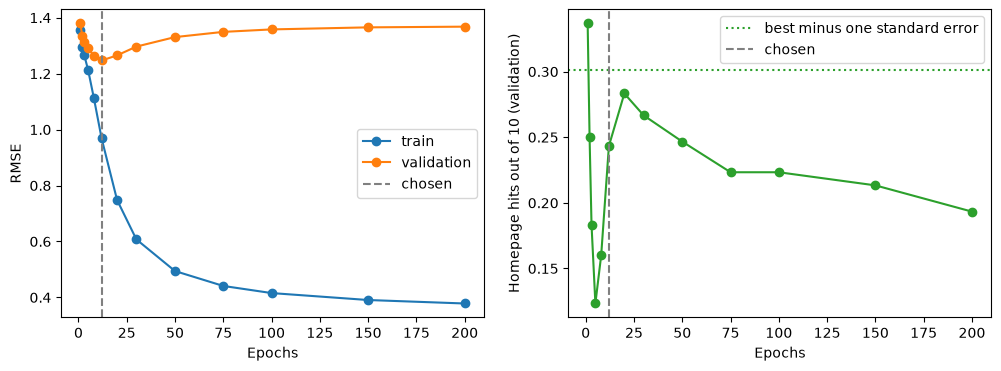

,epochs,train RMSE,validation RMSE,hits out of 10,hits standard error
0,1,1.355,1.379,0.337,0.035
1,2,1.296,1.333,0.250,0.030
2,3,1.266,1.315,0.183,0.028
3,5,1.213,1.292,0.123,0.023
4,8,1.112,1.262,0.160,0.028
5,12,0.968,1.247,0.243,0.035
6,20,0.748,1.265,0.283,0.034
7,30,0.607,1.297,0.267,0.034
8,50,0.494,1.331,0.247,0.034
9,75,0.441,1.349,0.223,0.032


In [89]:
# 150 and 200 epochs are included so that the point where the validation RMSE stops improving lies inside the grid
epochs_list = [1, 2, 3, 5, 8, 12, 20, 30, 50, 75, 100, 150, 200]
train_testset = tune_trainset.build_testset()

rows = []
for n_epochs in epochs_list:
    algo = SVD(n_factors=best_n_factors, n_epochs=n_epochs, random_state=my_seed)
    algo.fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row = {"epochs": n_epochs,
           "train RMSE": accuracy.rmse(algo.test(train_testset), verbose=False),
           "validation RMSE": accuracy.rmse(algo.test(tune_valset), verbose=False)}
    row.update(homepage_hits(top_n, tune_valset))
    rows.append(row)
epochs_df = pd.DataFrame(rows)

# Early stopping as in the course: the epoch with the lowest validation RMSE, after which more epochs no longer help.
# The one-standard-error rule on the hits is not used here (see the text below)
rmse_epochs = int(epochs_df.loc[epochs_df["validation RMSE"].idxmin(), "epochs"])
best_epochs = rmse_epochs
best_hits_row = epochs_df.loc[epochs_df["hits out of 10"].idxmax()]
print("Epochs with the lowest validation RMSE:", rmse_epochs)
print("Epochs with the most homepage hits:", int(best_hits_row["epochs"]))
print("Epochs chosen:", best_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_df["epochs"], epochs_df["train RMSE"], marker="o", label="train")
axes[0].plot(epochs_df["epochs"], epochs_df["validation RMSE"], marker="o", label="validation")
axes[0].axvline(best_epochs, color="grey", linestyle="--", label="chosen")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("RMSE")
axes[0].legend()
axes[1].plot(epochs_df["epochs"], epochs_df["hits out of 10"], marker="o", color="tab:green")
axes[1].axhline(best_hits_row["hits out of 10"] - best_hits_row["hits standard error"], color="tab:green",
                linestyle=":", label="best minus one standard error")
axes[1].axvline(best_epochs, color="grey", linestyle="--", label="chosen")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Homepage hits out of 10 (validation)")
axes[1].legend()
plt.show()

epochs_df[["epochs", "train RMSE", "validation RMSE", "hits out of 10", "hits standard error"]].round(3)


**The validation RMSE stops improving after 12 epochs, so training stops there.** The train RMSE keeps falling, from 1.355 after one epoch to 0.378 after 200. The validation RMSE falls to 1.247 at 12 epochs and then rises again, to 1.368 at 200. After that point the model learns noise from the training ratings, so training should stop where the validation error no longer improves [17, p. 18] [23, p. 10].

The homepage hits behave differently. They are highest after one epoch (0.337), drop to 0.123 at five epochs and recover to about 0.28 at 20 epochs. After one epoch the factors have barely moved, so the ranking mostly follows the anime biases and favors famous anime, much like the popularity models in Part 2. The one-standard-error rule from 3.1 would pick that single epoch, since no other number of epochs comes within one standard error of it. That would turn SVD into a popularity model, so for the epochs the validation RMSE decides instead. At 12 epochs SVD finds 0.243 hits on validation.

## 3.5 What the latent factors learn

To see what matrix factorization learns, an SVD with only 2 factors is trained, so that every anime becomes a point in a plane, as in the S13 notebook [23, p. 21]. S13 reads the plot by hovering over the points, which a saved notebook cannot show, so the titles at both ends of each factor are printed instead. The factors are then compared with the genres, which the model never saw. Only anime with at least 200 ratings are used, since the factors of rarely rated anime are not reliable.

In [90]:
svd_2d = SVD(n_factors=2, n_epochs=20, random_state=my_seed)
svd_2d.fit(trainset)

item_factors = pd.DataFrame(svd_2d.qi, columns=["dim 1", "dim 2"],
                            index=[trainset.to_raw_iid(i) for i in range(trainset.n_items)])
n_ratings = ratings_per_anime_df["count"].reindex(item_factors.index)

# Only anime with enough ratings, as the factors of rarely rated anime are not reliable
popular_factors = item_factors[n_ratings >= 200]
genres_popular = genres_df.reindex(popular_factors.index).fillna(0)
genre_corr = pd.DataFrame({dim: genres_popular.corrwith(popular_factors[dim]) for dim in popular_factors.columns}).dropna()

print("Anime in the plot:", len(popular_factors))
for dim in genre_corr.columns:
    ordered = genre_corr[dim].sort_values()
    print(dim, "- most negative genres:", list(ordered.index[:3]), " most positive genres:", list(ordered.index[-3:]))

Anime in the plot: 1168
dim 1 - most negative genres: ['Drama', 'Psychological', 'Mystery']  most positive genres: ['Harem', 'Ecchi', 'Comedy']
dim 2 - most negative genres: ['Harem', 'Ecchi', 'Romance']  most positive genres: ['Drama', 'Psychological', 'Dementia']


In [91]:
print(genre_corr.loc[["Drama", "Psychological", "Mystery", "Harem", "Ecchi", "Comedy", "Romance"]].round(2))
print("Correlation between the two factors:", round(popular_factors["dim 1"].corr(popular_factors["dim 2"]), 2))

               dim 1  dim 2
Drama          -0.28   0.17
Psychological  -0.25   0.18
Mystery        -0.22   0.10
Harem           0.24  -0.36
Ecchi           0.30  -0.36
Comedy          0.31  -0.01
Romance        -0.02  -0.22
Correlation between the two factors: -0.24


### Latent factor plot

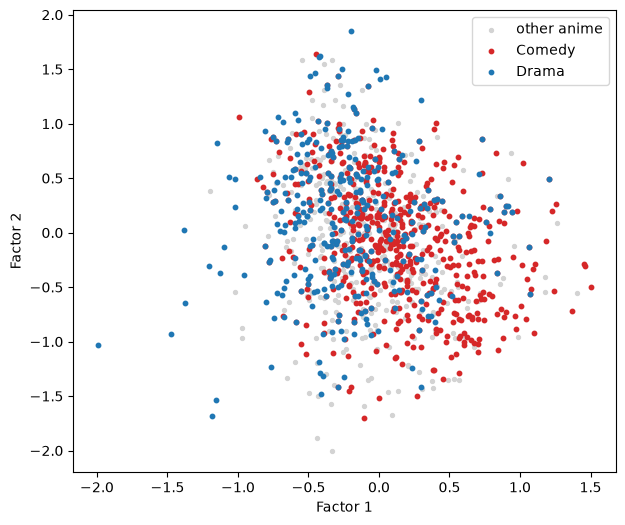

dim 1 low end:  ['School Days (6.28)', 'Elfen Lied (7.85)', 'Hoshi no Koe (7.58)', 'Tenshi Kinryouku (6.45)', 'Re:Zero kara Hajimeru Isekai Seikatsu (8.39)']
dim 1 high end: ['Kiss x Sis (TV) (6.99)', 'Aki-Sora: Yume no Naka (6.12)', 'Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houjou Dattebayo! Special: Konoha Annual Sports Festival (7.00)', 'Naruto (7.56)', 'Dragon Ball GT (6.67)']
dim 2 low end:  ['Sword Art Online (7.77)', 'Diabolik Lovers (5.27)', 'Isekai wa Smartphone to Tomo ni. (6.46)', 'Tokyo Ghoul √A (7.22)', 'Seiken Tsukai no World Break (6.98)']
dim 2 high end: ['Mononoke (8.27)', 'Neon Genesis Evangelion: The End of Evangelion (8.37)', 'Serial Experiments Lain (7.87)', 'Yojouhan Shinwa Taikei (8.38)', 'Texhnolyze (7.63)']


In [92]:
genre_a = genre_corr["dim 1"].idxmax()
genre_b = genre_corr["dim 1"].idxmin()

plt.figure(figsize=(7, 6))
plt.scatter(popular_factors["dim 1"], popular_factors["dim 2"], s=8, color="lightgrey", label="other anime")
for genre, color in [(genre_a, "tab:red"), (genre_b, "tab:blue")]:
    in_genre = genres_popular[genre] == 1
    plt.scatter(popular_factors.loc[in_genre, "dim 1"], popular_factors.loc[in_genre, "dim 2"], s=10, color=color, label=genre)
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.legend()
plt.show()

# The anime at the two ends of each factor, with their mean score in the training data
for dim in ["dim 1", "dim 2"]:
    ordered = popular_factors[dim].sort_values()
    print(dim, "low end: ", [f"{titles[i]} ({ratings_per_anime_df.loc[i, 'mean']:.2f})" for i in ordered.index[:5]])
    print(dim, "high end:", [f"{titles[i]} ({ratings_per_anime_df.loc[i, 'mean']:.2f})" for i in ordered.index[-5:]])

**Without seeing any genre, the two factors separate serious from light anime and acclaimed from mainstream anime.** Factor 1 correlates negatively with Drama (−0.28), Psychological (−0.25) and Mystery (−0.22) and positively with Comedy (0.31), Ecchi (0.30) and Harem (0.24). Its ends agree, with School Days and Elfen Lied at one end and Kiss x Sis and Dragon Ball GT at the other. Factor 2 resembles the blockbuster against arthouse axis [22, slide 29]. Its low end has mainstream titles such as Diabolik Lovers (mean 5.27) and Sword Art Online, and its high end acclaimed experimental anime such as Serial Experiments Lain and The End of Evangelion.

Matrix factorization learns the factors from the ratings alone [22, slide 26]. The model never saw the genres, so the genre pattern shows that collaborative filtering can personalize without metadata. The correlations are moderate (at most 0.36 in absolute value), the two factors are correlated (−0.24) and the tuned SVD has 100 factors that cannot be read one by one. The plot is therefore an illustration and not a full explanation of the model.

## 3.6 NMF

In [93]:
nmf_tuning = pd.DataFrame([
    dict({"n_factors": n_factors}, **validate(NMF(n_factors=n_factors, random_state=my_seed)))
    for n_factors in [1, 15, 100]
])
print(nmf_tuning.round(3).to_string(index=False))
best_nmf_factors = int(choose_setting(nmf_tuning, simpler="n_factors")["n_factors"])
print("Best n_factors:", best_nmf_factors)

 n_factors  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users with at least 1 hit %
         1 4.517    0.948   0.805           0.000                0.000                        0.000
        15 2.155    0.943   0.787           0.017                0.007                        1.667
       100 2.668    0.911   0.670           0.017                0.009                        1.333
Best n_factors: 15


**NMF is the weakest model on every metric that matters for the homepage.** Its best validation RMSE is 2.155, against about 1.25 for SVD, and it finds almost no relevant anime (0.017 hits). Surprise's NMF has no bias terms by default [21], so its non-negative factors must rebuild the high general level of the ratings (mean 7.56) instead of the differences between users. 15 factors are chosen. The main advantage of NMF is interpretability rather than accuracy [14, p. 119], which does not make up for its weak predictions here, so it is not used further.

## 3.7 Final comparison

In [94]:
cf_models = {
    "User KNN": KNNBaseline(k=int(best_user["k"]), min_k=min(int(best_user["k"]), 5), verbose=False,
                            sim_options={"name": best_user["similarity"], "user_based": True, "min_support": int(best_user["min_support"])}),
    "Item KNN": KNNBaseline(k=int(best_item["k"]), min_k=min(int(best_item["k"]), 5), verbose=False,
                            sim_options={"name": best_item["similarity"], "user_based": False, "min_support": int(best_item["min_support"])}),
    "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
    "NMF": NMF(n_factors=best_nmf_factors, random_state=my_seed),
}

results_cf = {name: evaluate_model(algo) for name, algo in cf_models.items()}
results_part3_df = pd.concat([results_part2_df, pd.DataFrame(results_cf).T])
results_part3_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Popular,1.552,1.184,0.932,0.784,0.509,0.000,0.000,0.0,0.33,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.875,0.039,49.2,1.31,0.407,0.267
Most rated,5.268,4.915,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,1.634,0.054,69.6,3.84,0.791,0.316
User KNN,1.215,0.905,0.943,0.817,0.529,0.353,0.024,24.8,5.68,0.790,0.266
Item KNN,1.195,0.888,0.946,0.827,0.534,0.424,0.026,28.2,9.70,0.763,0.267
SVD,1.229,0.919,0.939,0.805,0.521,0.573,0.033,33.0,7.71,0.807,0.281
NMF,2.150,1.883,0.926,0.762,0.496,0.040,0.006,3.9,4.57,0.554,0.164


**On ratings collaborative filtering wins, on the homepage the popularity models still win.** Item KNN (RMSE 1.195), user KNN (1.215) and SVD (1.229) predict ratings far better than popular (1.552), and they order each user's test items best. On the homepage the order reverses. SVD finds 0.573 relevant anime per 10, item KNN 0.424 and user KNN 0.353, against 1.449 for most rated.

RMSE and NDCG only look at anime the user already watched. A homepage hit also needs the user to have chosen the anime, and that choice depends heavily on popularity. Test ratings are missing not at random [14, pp. 250-251] [15, slide 13], so a model that predicts the choice is rewarded more than one that predicts the taste [19, p. 97].

SVD is the most useful collaborative model for the business. It has the most hits of the three and reaches 33.0% of users. Its lead over item KNN (0.149 hits) is about 3.5 combined standard errors. It also has the highest personalization (0.807). Item KNN shows a little more of the catalog (9.7% against 7.7%), but both show far more than most rated (1.7%).

## 3.8 Stability of the final models with 5-fold cross-validation

The table above comes from one split. 5-fold cross-validation repeats training and testing on 5 splits, so a lucky or unlucky test set shows up in the spread [6, p. 12]. The call is the one from the S13 notebook [23, p. 4]. Only RMSE and MAE are cross-validated. The homepage hits would need the whole catalogue ranked five times per model, and their standard errors already show their uncertainty.

In [95]:
cv_rows = {}
for name, algo in cf_models.items():
    cv = cross_validate(algo, data, measures=["RMSE", "MAE"], cv=KFold(n_splits=5, random_state=my_seed), verbose=False)
    cv_rows[name] = {"RMSE mean": cv["test_rmse"].mean(), "RMSE std": cv["test_rmse"].std(),
                     "MAE mean": cv["test_mae"].mean(), "MAE std": cv["test_mae"].std()}

pd.DataFrame(cv_rows).T.round(3)

,RMSE mean,RMSE std,MAE mean,MAE std
User KNN,1.218,0.002,0.908,0.002
Item KNN,1.199,0.002,0.891,0.002
SVD,1.232,0.002,0.922,0.002
NMF,2.152,0.002,1.885,0.002


**The ranking on ratings does not depend on the split.** The mean RMSE over 5 folds is 1.199 for item KNN, 1.218 for user KNN, 1.232 for SVD and 2.152 for NMF, each with a standard deviation of 0.002 and close to the single-split values. The smallest gap (0.014, user KNN against SVD) is seven times that spread. For the homepage the gap between SVD (0.573) and most rated (1.449) is far larger than both standard errors, so that conclusion does not depend on the split either.

## 3.9 Conclusion of Part 3

**SVD is the collaborative filtering model carried forward, as the personal component of the hybrid.** It gives up a little rating accuracy against item KNN (1.229 against 1.195) for 35% more hits (0.573 against 0.424) and a higher personalization, which is the better trade for a homepage. No collaborative model beats most rated on the homepage, so collaborative filtering alone is not the right homepage here. The offline bias may understate personal recommendations, so Part 5 combines the personal ranking of SVD with the hits of the popularity models.

# Part 4. Content-based

Content-based recommenders use the anime metadata and the user's own ratings, not the ratings of other users [14, pp. 139-140]. The steps follow the S16 notebook [3]. 4.2 to 4.7 turn the numerical columns, the categorical columns and the text into a similarity between every pair of anime. 4.8 compares the text methods and 4.9 tries named entities. 4.10 turns a similarity into recommendations for a user, a step the S16 notebook leaves open [3, p. 50]. 4.11 chooses the settings on the validation split and 4.12 evaluates the result with the Part 1 metrics.

## 4.1 Prepare the anime catalog

In [96]:
import re
from collections import Counter
from itertools import combinations

import spacy
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances, nan_euclidean_distances
from sklearn.preprocessing import StandardScaler
from surprise import PredictionImpossible
from tqdm import tqdm

# Some macOS setups raise false floating point warnings in matrix products. They are switched off here,
# and the similarity matrices are checked for NaN and infinite values in 4.11
old_error_settings = np.seterr(divide="ignore", over="ignore", invalid="ignore")

/Users/estellearnander/sem5/RE/recsys_group_project/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 21:59:07.834000 24715 venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [97]:
# The catalog from Part 1. Missing text is filled with empty strings, so no anime is removed
anime_clean = anime_df.copy().reset_index(drop=True)
for col in ["synopsis", "genre", "studio"]:
    anime_clean[col] = anime_clean[col].fillna("")
print("Anime:", anime_clean.shape)

Anime: (6668, 15)


In [98]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for col in ["title", "genre", "synopsis"]:
    anime_clean[col + "_clean"] = anime_clean[col].apply(clean_text)
anime_clean["content"] = anime_clean[["title_clean", "genre_clean", "synopsis_clean"]].agg(" ".join, axis=1)
anime_clean[["title", "genre", "content"]].head()

,title,genre,content
0,Inu x Boku SS,"Comedy, Supernatural, Romance, Shounen",inu x boku ss comedy supernatural romance shou...
1,Seto no Hanayome,"Comedy, Parody, Romance, School, Shounen",seto no hanayome comedy parody romance school ...
2,Shugo Chara!! Doki,"Comedy, Magic, School, Shoujo",shugo chara doki comedy magic school shoujo no...
3,Princess Tutu,"Comedy, Drama, Magic, Romance, Fantasy",princess tutu comedy drama magic romance fanta...
4,Bakuman. 3rd Season,"Comedy, Drama, Romance, Shounen",bakuman 3rd season comedy drama romance shoune...


**The text is cleaned and joined into one field per anime.** The text is lowercased and punctuation is removed, as the S16 notebook does for the categories [3, p. 19]. Title, genre and synopsis are then joined into one `content` field, like the "soup" in S16 [3, p. 20]. The original title and synopsis are kept for display and for named entity recognition, which needs capital letters.

The text has a known limit. 345 anime have no synopsis and 1,105 have fewer than 20 words (Part C.4). For these anime the text similarity rests mostly on the title and the genres.

## 4.2 Numerical similarity

In [99]:
num_columns = ["episodes", "duration_min", "aired_from_year"]
anime_num = anime_clean[num_columns].apply(pd.to_numeric, errors="coerce")
print("Missing values:", anime_num.isna().sum().to_dict())
anime_num.describe()

Missing values: {'episodes': 0, 'duration_min': 0, 'aired_from_year': 0}


,episodes,duration_min,aired_from_year
count,6668.000000,6668.000000,6668.000000
mean,14.276395,28.442167,2006.915267
std,40.906929,25.365980,10.381425
min,0.000000,0.000000,1942.000000
25%,1.000000,17.000000,2003.000000
50%,6.000000,24.000000,2010.000000
75%,13.000000,27.000000,2015.000000
max,1818.000000,163.000000,2018.000000


In [100]:
# The nan_euclidean distance of the S16 notebook, which skips missing values instead of filling them.
# nan_euclidean_distances is the same metric as pairwise_distances(metric="nan_euclidean")
num_distance = nan_euclidean_distances(anime_num)
anime_num_scaled = StandardScaler().fit_transform(anime_num)  # missing values stay missing
num_distance_scaled = nan_euclidean_distances(anime_num_scaled)
print("Raw:", num_distance.shape, "Scaled:", num_distance_scaled.shape)

Raw: (6668, 6668) Scaled: (6668, 6668)


**The numerical features are on very different scales.** Episodes range from 0 to 1,818, minutes per episode from 0 to 163 and the start year from 1942 to 2018. Without standardization the number of episodes decides almost every distance, as Gross does in the S16 example [3, p. 14]. The distance is the nan_euclidean distance of S16, which compares two anime on the values both have [3, p. 12]. Both matrices hold distances, so a smaller value means two anime are closer.

In [101]:
def title_index(title):
    matches = anime_clean.index[anime_clean["title"].str.casefold() == title.casefold()]
    if len(matches) == 0:
        raise ValueError(f"Anime not found: {title}")
    return int(matches[0])

def recommend_from_matrix(title, matrix, top_n=10, distance=False, columns=None):
    idx = title_index(title)
    scores = pd.Series(matrix[idx]).drop(idx)
    scores = scores.nsmallest(top_n) if distance else scores.nlargest(top_n)
    columns = columns or ["title", "genre"]
    result = anime_clean.iloc[scores.index][columns].copy()
    result["distance" if distance else "similarity"] = scores.to_numpy().round(4)
    return result.reset_index(drop=True)

raw_top = recommend_from_matrix("Death Note", num_distance, distance=True, columns=["title", *num_columns])
scaled_top = recommend_from_matrix("Death Note", num_distance_scaled, distance=True, columns=["title", *num_columns])

# The two distance matrices are only needed for this example, so they are removed to save memory
del num_distance, num_distance_scaled

pd.DataFrame({"Without normalization": raw_top["title"], "Raw distance": raw_top["distance"],
              "With normalization": scaled_top["title"], "Scaled distance": scaled_top["distance"]})

,Without normalization,Raw distance,With normalization,Scaled distance
0,Gallery Fake,2.2361,Otogi Juushi Akazukin,0.0628
1,Otogi Juushi Akazukin,2.2361,Saiunkoku Monogatari,0.0928
2,Yuki no Joou (TV),2.4495,Gallery Fake,0.1245
3,Saiunkoku Monogatari,2.8284,Yuki no Joou (TV),0.1269
4,Saiunkoku Monogatari 2nd Season,3.0000,Saiunkoku Monogatari 2nd Season,0.1337
5,Kyou kara Maou! 3rd Series,3.0000,Kyou kara Maou! 3rd Series,0.2026
6,Agatha Christie no Meitantei Poirot to Marple,3.4641,Agatha Christie no Meitantei Poirot to Marple,0.2138
7,Mermaid Melody Pichi Pichi Pitch Pure,3.4641,Mermaid Melody Pichi Pichi Pitch Pure,0.2138
8,Hanasakeru Seishounen,3.7417,Nana,0.2445
9,Element Hunters,3.7417,Tengen Toppa Gurren Lagann,0.2657


**Standardization changes the ranking, but neither list is a good recommendation.** The raw and standardized top 10 for Death Note share eight titles in a different order. Standardization brings in Nana and Tengen Toppa Gurren Lagann and drops Hanasakeru Seishounen and Element Hunters. Even the standardized list holds anime that share the format and age of Death Note but nothing of its story, such as Gallery Fake and Saiunkoku Monogatari. Like Death Note, both are TV series of 37 or 39 episodes from 2005 or 2006. The numerical features describe the format of an anime, not its content. They are therefore used in 4.11 only as a small addition to the text and genres.

## 4.3 Categorical similarity

In [102]:
cat_columns = ["genre", "type", "source", "studio"]

# As in the S16 notebook: lowercase, no spaces inside a category and all categories joined into one soup
anime_cat = anime_clean[cat_columns].fillna("").astype(str)
anime_cat = anime_cat.apply(lambda x: x.str.lower())
anime_cat = anime_cat.apply(lambda x: x.str.replace(" ", ""))
anime_cat = anime_cat.apply(lambda x: x.str.replace(",", " "))
anime_cat["soup"] = anime_cat[cat_columns].agg(" ".join, axis=1)

cat_matrix = CountVectorizer().fit_transform(anime_cat["soup"])
cat_similarity = cosine_similarity(cat_matrix)
print("Categorical matrix:", cat_matrix.shape)
recommend_from_matrix("Death Note", cat_similarity, columns=["title", *cat_columns])

Categorical matrix: (6668, 553)


,title,genre,type,source,studio,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",Special,Manga,Madhouse,0.8250
1,Mirai Nikki (TV),"Action, Psychological, Supernatural, Thriller,...",TV,Manga,Asread,0.7778
2,Monster,"Drama, Horror, Mystery, Police, Psychological,...",TV,Manga,Madhouse,0.7379
3,Mousou Dairinin,"Mystery, Dementia, Police, Psychological, Supe...",TV,Original,Madhouse,0.7379
4,Majin Tantei Nougami Neuro,"Mystery, Comedy, Demons, Supernatural, Shounen",TV,Manga,Madhouse,0.7071
5,Mouryou no Hako,"Mystery, Psychological, Supernatural, Thriller...",TV,Novel,Madhouse,0.7071
6,Top Secret: The Revelation,"Sci-Fi, Mystery, Police, Psychological, Shoujo",TV,Manga,Madhouse,0.6667
7,Higurashi no Naku Koro ni Kai,"Mystery, Psychological, Supernatural, Thriller",TV,Visual novel,Studio Deen,0.6299
8,Touhai Densetsu Akagi: Yami ni Maiorita Tensai,"Game, Psychological, Thriller, Seinen",TV,Manga,Madhouse,0.6299
9,Gyakkyou Burai Kaiji: Hakairoku-hen,"Game, Psychological, Thriller, Seinen",TV,Manga,Madhouse,0.6299


**Genres, type, source and studio find anime with a similar profile.** As in the S16 notebook, the categories are lowercased, spaces inside a category are removed so that "Slice of Life" stays one word, and all categories are joined into one soup [3, pp. 19-20]. `CountVectorizer` turns the soup into 553 features, one per category, and every category counts equally in the cosine similarity [3, p. 19].

For Death Note the list is far more relevant than the numerical one. Mirai Nikki (TV), Monster and Mousou Dairinin share psychological, mystery or supernatural genres. Eight of the top 10 also come from the same studio, Madhouse.

The first recommendation is Death Note: Rewrite, a special that retells the series. This shows the main weakness of content-based recommenders, called overspecialization [14, pp. 161-162]. They find anime very similar to what the user already knows. Such recommendations are relevant but obvious, so they add little discovery [14, p. 233].

## 4.4 Bag of Words

In [103]:
bow_vectorizer = CountVectorizer(stop_words="english")
bow_matrix = bow_vectorizer.fit_transform(anime_clean["content"])
bow_similarity = cosine_similarity(bow_matrix)

print("BoW matrix shape:", bow_matrix.shape)
recommend_from_matrix("Death Note", bow_similarity)

BoW matrix shape: (6668, 33931)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.4009
1,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.2948
2,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2511
3,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.2449
4,Kite Liberator,"Action, Sci-Fi, Drama",0.2345
5,Death Parade,"Game, Mystery, Psychological, Drama, Thriller",0.2216
6,Persona 3 the Movie 4: Winter of Rebirth,"Action, Supernatural, Fantasy",0.2019
7,Da Yu Hai Tang,"Adventure, Drama, Romance, Supernatural",0.1984
8,Zombie-Loan,"Action, Horror, Shounen, Supernatural",0.1975
9,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.1857


## 4.5 TF-IDF

In [104]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(anime_clean["content"])
tfidf_similarity = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
recommend_from_matrix("Death Note", tfidf_similarity)

TF-IDF matrix shape: (6668, 33931)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.3380
1,Soushisouai Note The Animation,Hentai,0.1926
2,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.1855
3,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.1843
4,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.1761
5,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.1516
6,Kite Liberator,"Action, Sci-Fi, Drama",0.1489
7,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.1372
8,Bleach: Memories in the Rain,"Action, Adventure, Supernatural, Drama, Shounen",0.1288
9,Ai Tenchi Muyou!,"Comedy, Sci-Fi, Shounen",0.1277


**TF-IDF lowers the weight of common words, which changes the ranking.** Bag of Words counts the words. TF-IDF gives more weight to rare words, as the "infinity" against "help" example in S16 shows [3, p. 34]. Both put Death Note: Rewrite first.

TF-IDF ranks Soushisouai Note The Animation second, against seventh for Bag of Words. It shares the rare word "note" with Death Note but nothing else. It is an adult anime, so the business rule in 1.4 keeps it off the homepage. It still shows a risk of TF-IDF. One rare shared word can create a strong match between two unrelated anime.

## 4.6 Lemmatized TF-IDF

In [105]:
# spaCy lemmatization as in the S16 notebook. The synopses are processed once and the documents are kept,
# so that the named entities in 4.9 come from the same run
nlp = spacy.load("en_core_web_sm")
synopsis_docs = [nlp(synopsis) for synopsis in tqdm(anime_clean["synopsis"])]

anime_clean["synopsis_lem"] = [clean_text(" ".join(token.lemma_ for token in doc)) for doc in synopsis_docs]
anime_clean["content_lem"] = anime_clean[["title_clean", "genre_clean", "synopsis_lem"]].agg(" ".join, axis=1)
tfidf_lem_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_lem_matrix = tfidf_lem_vectorizer.fit_transform(anime_clean["content_lem"])
tfidf_lem_similarity = cosine_similarity(tfidf_lem_matrix)
print("TF-IDF:", tfidf_matrix.shape, "Lemmatized TF-IDF:", tfidf_lem_matrix.shape)
recommend_from_matrix("Death Note", tfidf_lem_similarity)

100%|██████████| 6668/6668 [00:39<00:00, 170.69it/s]


TF-IDF: (6668, 33931) Lemmatized TF-IDF: (6668, 29317)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.3394
1,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2197
2,Soushisouai Note The Animation,Hentai,0.1886
3,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.1844
4,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.1835
5,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.1605
6,Kite Liberator,"Action, Sci-Fi, Drama",0.1542
7,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.1527
8,Wild 7,"Action, Police, Drama, Shounen",0.1517
9,Burn Up Scramble,"Action, Comedy, Drama, Ecchi, Police, Sci-Fi, ...",0.1513


**Lemmatization barely changes the result.** Lemmatization merges word forms such as "notes" and "note", so that both count as the same word [3, pp. 36-37]. Only the synopsis is lemmatized, with spaCy as in the S16 notebook [3, p. 35]. The vocabulary shrinks from 33,931 to 29,317 words. For Death Note the lemmatized TF-IDF keeps Death Note: Rewrite first and moves Soushisouai Note The Animation from second to third. Over the three test anime its top 10 shares 9.0 titles on average with plain TF-IDF (4.8). The misleading word "note" is in the title, which is not lemmatized, so it still counts.

## 4.7 Sentence-BERT

In [106]:
model = SentenceTransformer("all-MiniLM-L6-v2")
bert_embeddings = model.encode(anime_clean["content"].tolist(), batch_size=32, show_progress_bar=True, convert_to_numpy=True)
bert_similarity = cosine_similarity(bert_embeddings)
print("Embeddings:", bert_embeddings.shape, "Similarity:", bert_similarity.shape)

# The model is not needed after the embeddings are computed, so it is removed to save memory
del model

recommend_from_matrix("Death Note", bert_similarity)

Batches: 100%|██████████| 209/209 [00:12<00:00, 16.34it/s]


Embeddings: (6668, 384) Similarity: (6668, 6668)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.6631
1,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.6184
2,Majin Tantei Nougami Neuro,"Mystery, Comedy, Demons, Supernatural, Shounen",0.5847
3,Yakushiji Ryouko no Kaiki Jikenbo,"Mystery, Police, Supernatural",0.5759
4,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),"Action, Mystery, Supernatural, Romance, Thriller",0.5747
5,Angel Cop,"Action, Sci-Fi, Police",0.5692
6,Shinrei Tantei Yakumo,"Horror, Mystery, Shoujo, Supernatural",0.5691
7,UN-GO,"Mystery, Supernatural",0.5572
8,Yami Shibai,"Dementia, Horror, Demons, Supernatural",0.5568
9,ChäoS;HEAd,"Harem, Mystery, Psychological, Sci-Fi, Superna...",0.5533


**Sentence-BERT finds anime with a similar theme instead of shared words.** It considers meaning and context, not only word counts [3, p. 38]. The all-MiniLM-L6-v2 model gives 384 numbers per anime, half of the 768 of the S16 model [3, p. 38], so the similarity matrix is cheaper to compute. For Death Note it ranks Death Note: Rewrite first, followed by Yami no Matsuei and Majin Tantei Nougami Neuro. These are detective and supernatural stories that share no title words. Whether this gives better recommendations is tested on the validation split in 4.11.

## 4.8 Comparison of the text representations

In [107]:
text_models = {"BoW": bow_similarity, "TF-IDF": tfidf_similarity,
               "Lemmatized TF-IDF": tfidf_lem_similarity, "Sentence-BERT": bert_similarity}
test_anime = ["Death Note", "Naruto", "Shingeki no Kyojin"]

In [108]:
def compare_recommendations(title, top_n=10):
    # The top 10 of every text representation side by side
    comparison = pd.DataFrame(index=range(1, top_n + 1))
    for name, matrix in text_models.items():
        recs = recommend_from_matrix(title, matrix, top_n=top_n)
        comparison[name] = [f"{t} ({s:.4f})" for t, s in zip(recs["title"], recs["similarity"])]
    return comparison

In [109]:
for title in test_anime:
    print(title)
    display(compare_recommendations(title))

Death Note


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Death Note: Rewrite (0.4009),Death Note: Rewrite (0.3380),Death Note: Rewrite (0.3394),Death Note: Rewrite (0.6631)
2,Soul Eater (0.2948),Soushisouai Note The Animation (0.1926),Shinigami no Ballad. (0.2197),Yami no Matsuei (0.6184)
3,Shinigami no Ballad. (0.2511),Shinigami no Ballad. (0.1855),Soushisouai Note The Animation (0.1886),Majin Tantei Nougami Neuro (0.5847)
4,Dia Horizon (Kabu) (0.2449),Soul Eater (0.1843),YAT Anshin! Uchuu Ryokou 2 (0.1844),Yakushiji Ryouko no Kaiki Jikenbo (0.5759)
5,Kite Liberator (0.2345),YAT Anshin! Uchuu Ryokou 2 (0.1761),Soul Eater (0.1835),Kara no Kyoukai 7: Satsujin Kousatsu (Kou) (0....
6,Death Parade (0.2216),Dia Horizon (Kabu) (0.1516),Yami no Matsuei (0.1605),Angel Cop (0.5692)
7,Persona 3 the Movie 4: Winter of Rebirth (0.2019),Kite Liberator (0.1489),Kite Liberator (0.1542),Shinrei Tantei Yakumo (0.5691)
8,Da Yu Hai Tang (0.1984),Yami no Matsuei (0.1372),Dia Horizon (Kabu) (0.1527),UN-GO (0.5572)
9,Zombie-Loan (0.1975),Bleach: Memories in the Rain (0.1288),Wild 7 (0.1517),Yami Shibai (0.5568)
10,YAT Anshin! Uchuu Ryokou 2 (0.1857),Ai Tenchi Muyou! (0.1277),Burn Up Scramble (0.1513),ChäoS;HEAd (0.5533)


Naruto


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Boruto: Naruto Next Generations (0.4437),Naruto: Shippuuden (0.4198),Naruto: Shippuuden (0.4534),Naruto: Shippuuden (0.8113)
2,Naruto: Shippuuden (0.4363),Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Boruto: Naruto the Movie (0.7152)
3,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Boruto: Naruto Next Generations (0.3778),Boruto: Naruto Next Generations (0.3885),Boruto: Naruto Next Generations (0.7122)
4,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Naruto: Shippuuden Movie 6 - Road to Ninja (0....
5,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Boruto: Naruto the Movie (0.3112),Boruto: Naruto the Movie (0.3313),Naruto: Shippuuden Movie 2 - Kizuna (0.6857)
6,Naruto: Shippuuden Movie 5 - Blood Prison (0.3...,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,The Last: Naruto the Movie (0.6606)
7,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houj...,Naruto: The Cross Roads (0.3124),Naruto: Shippuuden Movie 4 - The Lost Tower (0...
8,Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Naruto: The Cross Roads (0.2963),Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houj...,Naruto SD: Rock Lee no Seishun Full-Power Nind...
9,Boruto: Naruto the Movie (0.3476),Naruto: Shippuuden Movie 5 - Blood Prison (0.2...,Naruto: Shippuuden Movie 2 - Kizuna (0.2968),Naruto Movie 2: Dai Gekitotsu! Maboroshi no Ch...
10,Naruto Soyokazeden Movie: Naruto to Mashin to ...,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Naruto Movie 3: Dai Koufun! Mikazuki Jima no A...


Shingeki no Kyojin


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Shingeki no Kyojin Season 2 (0.3503),Shingeki no Kyojin Season 2 (0.3632),Shingeki no Kyojin Season 2 (0.4243),Shingeki no Kyojin Season 2 (0.7368)
2,Shingeki no Kyojin: Ano Hi Kara (0.2433),Shingeki! Kyojin Chuugakkou (0.3015),Shingeki! Kyojin Chuugakkou (0.3965),Shingeki! Kyojin Chuugakkou (0.6048)
3,Shingeki! Kyojin Chuugakkou (0.2228),Shingeki no Kyojin: Ano Hi Kara (0.2157),Shingeki no Kyojin: Ano Hi Kara (0.2145),Shingeki no Kyojin OVA (0.5661)
4,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Shingeki no Kyojin Picture Drama (0.1758),Shingeki no Kyojin OVA (0.2120),Mobile Suit Zeta Gundam (0.5606)
5,Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Soukyuu no Fafner: Dead Aggressor (0.5562)
6,Shingeki no Kyojin: Kuinaki Sentaku (0.1774),Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Tokyo Ghoul:re (0.5464)
7,Shingeki no Kyojin OVA (0.1768),Shingeki no Kyojin: Kuinaki Sentaku (0.1529),Mobile Suit Zeta Gundam (0.1584),Gate Keepers 21 (0.5461)
8,Shingeki no Kyojin Picture Drama (0.1529),Shingeki no Kyojin OVA (0.1519),Shingeki no Kyojin Picture Drama (0.1501),Cardfight!! Vanguard: Legion Mate-hen (0.5459)
9,Nejimaki Seirei Senki: Tenkyou no Alderamin (0...,Shingeki no Kyojin: Lost Girls (0.1378),Shingeki no Kyojin: Kuinaki Sentaku (0.1497),Shin Angyo Onshi (0.5439)
10,Vie Durant (0.1478),Mobile Suit Zeta Gundam (0.1250),Shingeki no Kyojin: Lost Girls (0.1416),Utawarerumono: Itsuwari no Kamen (0.5436)


In [110]:
# How many of the top 10 two models share, for each test anime and each pair of models
overlap_rows = []
for title in test_anime:
    top10 = {name: set(recommend_from_matrix(title, matrix, top_n=10)["title"]) for name, matrix in text_models.items()}
    for model_1, model_2 in combinations(text_models, 2):
        shared = len(top10[model_1] & top10[model_2])
        overlap_rows.append({"Anime": title, "Model 1": model_1, "Model 2": model_2,
                             "Shared@10": shared, "Overlap@10": shared / 10})
overlap_df = pd.DataFrame(overlap_rows)

average_overlap = (
    overlap_df.groupby(["Model 1", "Model 2"])
    [["Shared@10", "Overlap@10"]]
    .mean()
    .reset_index())
average_overlap.round(4)

,Model 1,Model 2,Shared@10,Overlap@10
0,BoW,Lemmatized TF-IDF,7.0000,0.7000
1,BoW,Sentence-BERT,3.0000,0.3000
2,BoW,TF-IDF,7.3333,0.7333
3,Lemmatized TF-IDF,Sentence-BERT,4.0000,0.4000
4,TF-IDF,Lemmatized TF-IDF,9.0000,0.9000
5,TF-IDF,Sentence-BERT,3.6667,0.3667


**The word-based methods stay inside the franchise, while Sentence-BERT looks further.** For all three anime every method puts the direct sequel or retelling first. For Naruto all four lists are almost entirely Naruto and Boruto titles. For Shingeki no Kyojin Sentence-BERT also recommends anime outside the franchise, such as Tokyo Ghoul:re.

The overlap table confirms this. Bag of Words, TF-IDF and lemmatized TF-IDF share 7.0 to 9.0 of their top 10 titles. Sentence-BERT shares only 3.0 to 4.0 with any of them. The scores cannot be compared across methods, and agreement says nothing about which method users prefer. 4.11 makes that choice on the validation split.

## 4.9 Named entity recognition

Named entity recognition finds names of people, places and organizations, as in the bonus of the S16 notebook [3, pp. 51-56]. Two anime with the same characters or settings could then be matched. The entities come from the same spaCy run as the lemmas in 4.6. S16 notes that the small model already does a good job [3, p. 55].

In [111]:
def get_entities(text, nlp):
    return [(e.text, e.start_char, e.end_char, e.label_) for e in nlp(text).ents]

get_entities(anime_clean.loc[title_index("Death Note"), "synopsis"], nlp)

[('shinigami', 0, 9, 'PERSON'),
 ('One day', 153, 160, 'DATE'),
 ('Ryuk', 162, 166, 'PERSON'),
 ('one', 268, 271, 'CARDINAL'),
 ('Light Yagami', 326, 338, 'PERSON'),
 ('the Death Note', 540, 554, 'ORG'),
 ('Light', 556, 561, 'ORG'),
 ('Japanese', 977, 985, 'NORP'),
 ('L.', 1112, 1114, 'NORP')]

**spaCy finds the main characters but makes typical mistakes on this text.** It labels Ryuk and Light Yagami correctly as persons. But it also labels the word shinigami as a person, Light alone as an organization, the Death Note itself as an organization and L. as a nationality. Japanese names and invented words are hard for the small model, so the entities are noisy.

In [112]:
# Names of people, places and organizations per anime. Dates, numbers and similar entities cannot match two stories
name_labels = {"PERSON", "ORG", "GPE", "LOC", "FAC"}
anime_clean["NER"] = [sorted({(e.text.casefold(), e.label_) for e in doc.ents if e.label_ in name_labels})
                      for doc in synopsis_docs]
entity_frequency = Counter(entity for entities in anime_clean["NER"] for entity in entities)
print("Anime without entities:", (anime_clean["NER"].str.len() == 0).sum())
pd.DataFrame(entity_frequency.most_common(20), columns=["entity", "anime"])

Anime without entities: 906


,entity,anime
0,"(ann, ORG)",1144
1,"(japan, GPE)",374
2,"(earth, LOC)",343
3,"(anidb, PERSON)",296
4,"(tokyo, GPE)",205
5,"(wikipedia, ORG)",152
6,"(animenfo, ORG)",75
7,"(mal news, ORG)",72
8,"(crunchyroll, ORG)",64
9,"(ova, ORG)",50


In [113]:
# Anime that share a rare entity (found in 10 anime or fewer) with Death Note
idx = title_index("Death Note")
target = {entity for entity in anime_clean.loc[idx, "NER"] if entity_frequency[entity] <= 10}
shares_entity = anime_clean["NER"].apply(lambda entities: len(target & set(entities)) > 0).drop(idx)
print("Rare entities of Death Note:", sorted(target))
print("Anime that share one of them:", shares_entity.sum())

# The spaCy documents are not needed after this section, so they are removed to save memory
del synopsis_docs

Rare entities of Death Note: [('light', 'ORG'), ('light yagami', 'PERSON'), ('ryuk', 'PERSON'), ('shinigami', 'PERSON'), ('the death note', 'ORG')]
Anime that share one of them: 11


**Named entities do not work as a recommender here.** 906 anime have no name entity at all. The most frequent entities are not story names. They are source credits at the end of a synopsis, such as ANN, AniDB and Wikipedia, and general places such as Japan, Earth and Tokyo. Only entities found in 10 anime or fewer are specific to a story. Death Note has five of them (Light, Light Yagami, Ryuk, shinigami and the Death Note), and 11 anime share at least one. Two anime rarely share a character name unless they belong to the same franchise, which the title words already show. Entities therefore add nothing the text models do not already find, so they are not used further.

## 4.10 From similarities to recommendations

A similarity only says which anime resemble each other. A homepage needs a score for every anime the user has not rated. The score is the user's average rating plus the weighted average of how much the user liked the `k` most similar anime they rated, above or below their average. The weights are the content similarities. This is the item-based prediction [8, p. 198] with a similarity from the metadata instead of the ratings [14, p. 140]. The S16 notebook suggests this step, for example with the last anime a user liked [3, p. 50].

In [114]:
class MyContentBasedAlgorithm(AlgoBase):
    def __init__(self, similarity, k=20):
        AlgoBase.__init__(self)
        self.similarity = similarity  # anime x anime, in the row order of anime_clean
        self.k = k

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        # Row of each surprise item in the similarity matrix
        row_of_anime = pd.Series(anime_clean.index, index=anime_clean["anime_id"])
        self.row_of_item = row_of_anime.reindex([trainset.to_raw_iid(i) for i in trainset.all_items()]).to_numpy()

        # For every user: the rows of the anime they rated and how far each rating is from their own average
        self.user_mean, self.user_rows, self.user_deviation = {}, {}, {}
        for u, user_ratings in trainset.ur.items():
            items = np.array([i for i, _ in user_ratings])
            scores = np.array([r for _, r in user_ratings])
            self.user_mean[u] = scores.mean()
            self.user_rows[u] = self.row_of_item[items]
            self.user_deviation[u] = scores - scores.mean()
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            raise PredictionImpossible("User or anime unknown")
        sims = self.similarity[self.row_of_item[i], self.user_rows[u]]
        k = min(self.k, len(sims))
        nearest = np.argpartition(-sims, k - 1)[:k]  # the k rated anime most similar to anime i
        weights = np.clip(sims[nearest], 0, None)
        if weights.sum() == 0:
            return self.user_mean[u]
        return self.user_mean[u] + (weights * self.user_deviation[u][nearest]).sum() / weights.sum()

## 4.11 Choosing the settings on the validation split

The settings are chosen on the validation split from 1.3 with the 300 users in `val_users`, as in Part 3. The test set is not used. Four choices are made in order. These are the text representation, `k`, the weight between text and categorical features and the weight of the numerical features. Each choice follows the one-standard-error rule from 3.1. The similarity of one example cannot be used, because a higher similarity does not mean a better recommendation and one anime says nothing about other users.

In [115]:
def validate_cb(similarity, k=20):
    # The same scores as validate() in Part 3, plus the diversity of the lists
    algo = MyContentBasedAlgorithm(similarity, k=k).fit(tune_trainset)
    row = {"RMSE": accuracy_metrics(algo.test(tune_valset))["RMSE"]}
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row.update(homepage_hits(top_n, tune_valset))
    row["intra-list similarity"] = recmetrics.intra_list_similarity(list(top_n.values()), genres_df)
    return row

### Text representation

The candidates are the representations above plus two common TF-IDF variants. Bigrams add pairs of words, so that a name such as "death note" counts as one term. Sublinear term frequency uses the logarithm of the word count, so that one repeated word does not dominate a synopsis. Named entities are left out (4.9).

In [116]:
text_similarities = {
    "BoW": bow_similarity,
    "TF-IDF": tfidf_similarity,
    "TF-IDF, bigrams": cosine_similarity(TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit_transform(anime_clean["content"])),
    "TF-IDF, sublinear tf": cosine_similarity(TfidfVectorizer(stop_words="english", sublinear_tf=True).fit_transform(anime_clean["content"])),
    "Lemmatized TF-IDF": tfidf_lem_similarity,
    "Sentence-BERT": bert_similarity,
}

text_tuning = pd.DataFrame({name: validate_cb(similarity) for name, similarity in text_similarities.items()}).T
best_text = choose_setting(text_tuning).name  # one-standard-error rule from 3.1
print("Best text representation:", best_text)
text_tuning.round(3)

Best text representation: TF-IDF, bigrams


,RMSE,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
BoW,1.403,0.120,0.022,10.000,0.307
TF-IDF,1.385,0.193,0.028,15.667,0.284
"TF-IDF, bigrams",1.375,0.223,0.033,17.667,0.291
"TF-IDF, sublinear tf",1.383,0.187,0.027,15.667,0.278
Lemmatized TF-IDF,1.386,0.183,0.029,14.667,0.284
Sentence-BERT,1.428,0.087,0.018,7.667,0.293


**TF-IDF with bigrams gives the most homepage hits and Sentence-BERT the fewest.** On validation TF-IDF with bigrams finds 0.223 relevant anime per 10, plain TF-IDF 0.193, Bag of Words 0.120 and Sentence-BERT 0.087. Weighting rare words helps, since plain TF-IDF beats raw word counts by about two combined standard errors. Sentence-BERT does worst, although its example in 4.7 looked the most meaningful. A likely reason is that users often like anime with the same names and franchise words. Word-based methods catch these obvious matches [14, pp. 161-162], while a theme-based embedding spreads them out. Bigrams fit this, since they keep a name such as "death note" together. Plain TF-IDF is within one standard error of the bigrams, so the lowest validation RMSE decides between them, and that is TF-IDF with bigrams (1.375 against 1.385).

### Number of similar anime (k)

In [117]:
k_tuning = pd.DataFrame({k: validate_cb(text_similarities[best_text], k=k) for k in [5, 20, 100]}).T
k_tuning.index.name = "k"
best_k = int(choose_setting(k_tuning).name)
print("Best k:", best_k)
k_tuning.round(3)

Best k: 20


,RMSE,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
k,,,,,
5,1.434,0.130,0.023,11.333,0.266
20,1.375,0.223,0.033,17.667,0.291
100,1.390,0.170,0.027,13.667,0.269


**20 similar anime work best, but the optimum is not sharp.** With k = 5 the score rests on few rated anime (0.130 hits). With k = 100 it averages over many anime that are barely similar (0.170). k = 20 gives 0.223. As for the KNN models in 3.2, both extremes are worse.

### Weight between text and categorical features

The two similarities are combined as `weight × text similarity + (1 - weight) × categorical similarity`, the averaging that the S16 notebook suggests as a next step [3, p. 50]. The two are on very different scales. Two anime share few exact words, so most text similarities are close to 0. Two anime often share a genre or a type, so categorical similarities are much larger. Each similarity is therefore divided by its own 99th percentile first, so that a very similar pair scores about 1 in both. This does not change the ranking of either similarity alone.

In [118]:
def scaled(similarity):
    # Divide by the 99th percentile, estimated on 500 random rows to save memory
    rng = np.random.default_rng(my_seed)
    sample = similarity[rng.choice(len(similarity), size=500, replace=False)]
    return similarity / np.percentile(sample, 99)


text_scaled = scaled(text_similarities[best_text])
cat_scaled = scaled(cat_similarity)

weight_tuning = pd.DataFrame({
    weight: validate_cb(weight * text_scaled + (1 - weight) * cat_scaled, k=best_k)
    for weight in [0, 0.25, 0.5, 0.75, 0.9, 1]
}).T
weight_tuning.index.name = "weight of the text"
best_weight = choose_setting(weight_tuning).name
print("Best weight:", best_weight)

text_cat_similarity = best_weight * text_scaled + (1 - best_weight) * cat_scaled

# The other text representations are no longer needed after this choice, so the dictionary is removed to save memory.
# Its BoW, TF-IDF and Sentence-BERT matrices are kept under their own names for 4.12
del text_similarities

weight_tuning.round(3)

Best weight: 0.75


,RMSE,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
weight of the text,,,,,
0.00,1.400,0.040,0.012,3.667,0.440
0.25,1.375,0.103,0.022,8.333,0.383
0.50,1.365,0.170,0.026,14.000,0.334
0.75,1.367,0.223,0.034,17.667,0.308
0.90,1.372,0.227,0.032,18.000,0.293
1.00,1.375,0.223,0.033,17.667,0.291


**The text matters much more than the genres.** With only categorical features the model finds 0.040 hits. The hits rise with the text weight, up to 0.227 at 0.9. The weights 0.75, 0.9 and 1 are within one standard error of each other, and 0.75 has the lowest validation RMSE of the three (1.367), so the rule picks 0.75. The lists also become more diverse as the text weight grows (intra-list similarity from 0.440 to 0.291), since genres alone fill a list with anime of the same genres.

### Weight of the numerical features

The numerical features describe the format and age of an anime. Three steps prepare them.

1. A 0 for episodes or minutes means unknown, not zero. Of the 133 anime with 0 episodes, 76 started in 2017 or 2018, so most were probably still airing. These values are filled with the median.
2. The number of episodes is very skewed, with a median of 6 and a maximum of 1,818. It is log-transformed, so that a few very long series do not decide every distance.
3. The features are standardized as in 4.2 [3, p. 15]. The distance becomes a similarity with 1 / (1 + distance) and is scaled like the other two.

In [119]:
zero_episodes = anime_clean[anime_clean["episodes"] == 0]
print("Anime with 0 episodes:", len(zero_episodes), "Started in 2017 or 2018:", (zero_episodes["aired_from_year"] >= 2017).sum())

num_features = anime_clean[["episodes", "duration_min", "aired_from_year"]].astype(float)
num_features[["episodes", "duration_min"]] = num_features[["episodes", "duration_min"]].replace(0, np.nan)
num_features = num_features.fillna(num_features.median())
num_features["episodes"] = np.log1p(num_features["episodes"])
num_similarity = scaled(1 / (1 + euclidean_distances(StandardScaler().fit_transform(num_features))))

num_tuning = pd.DataFrame({
    weight: validate_cb((1 - weight) * text_cat_similarity + weight * num_similarity, k=best_k)
    for weight in [0, 0.1, 0.2, 0.3, 1]
}).T
num_tuning.index.name = "weight of the numerical features"
best_num_weight = choose_setting(num_tuning).name
print("Best weight of the numerical features:", best_num_weight)

# The similarity used by the final content-based model, here and in Part 5
cb_similarity = (1 - best_num_weight) * text_cat_similarity + best_num_weight * num_similarity
num_tuning.round(3)

Anime with 0 episodes: 133 Started in 2017 or 2018: 76
Best weight of the numerical features: 0.3


,RMSE,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
weight of the numerical features,,,,,
0.0,1.367,0.223,0.034,17.667,0.308
0.1,1.363,0.223,0.032,17.333,0.316
0.2,1.359,0.203,0.028,16.667,0.334
0.3,1.355,0.193,0.026,17.333,0.333
1.0,1.428,0.043,0.015,3.333,0.269


**The numerical features do not change the hits beyond noise, and the rule keeps a weight of 0.3 for its lower RMSE.** Weights from 0 to 0.3 give between 0.193 and 0.223 hits, all within one standard error (0.034) of the best. Among them the lowest validation RMSE decides, which is a weight of 0.3 (1.355 against 1.367 without numerical features). A weight of 1 drops to 0.043 hits, because format and age alone say little about content (4.2).

In [120]:
# The floating point warnings are switched off (see the imports), so check that no similarity has NaN or infinite values
similarities = {"categorical": cat_similarity, "BoW": bow_similarity, "TF-IDF": tfidf_similarity,
                "lemmatized TF-IDF": tfidf_lem_similarity, "Sentence-BERT": bert_similarity,
                "numerical": num_similarity, "final content-based": cb_similarity}
for name, matrix in similarities.items():
    assert np.isfinite(matrix).all(), f"{name} similarity has NaN or infinite values"
print("All similarity matrices are finite")

All similarity matrices are finite


## 4.12 Evaluation with the Part 1 metrics

Each representation is evaluated on the test set with `evaluate_model()` from 1.4 and the `k` chosen above. CB tuned is the combination chosen in 4.11. Random, most rated and SVD come from the Part 3 table.

In [121]:
cb_models = {
    "CB categorical": MyContentBasedAlgorithm(cat_similarity, k=best_k),
    "CB BoW": MyContentBasedAlgorithm(bow_similarity, k=best_k),
    "CB TF-IDF": MyContentBasedAlgorithm(tfidf_similarity, k=best_k),
    "CB lemmatized TF-IDF": MyContentBasedAlgorithm(tfidf_lem_similarity, k=best_k),
    "CB Sentence-BERT": MyContentBasedAlgorithm(bert_similarity, k=best_k),
    "CB tuned": MyContentBasedAlgorithm(cb_similarity, k=best_k),
}

results_cb = {name: evaluate_model(algo) for name, algo in cb_models.items()}
results_part4_df = pd.concat([results_part3_df.loc[["Random", "Most rated", "SVD"]], pd.DataFrame(results_cb).T])
results_part4_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
SVD,1.229,0.919,0.939,0.805,0.521,0.573,0.033,33.0,7.71,0.807,0.281
CB categorical,1.387,1.047,0.905,0.688,0.454,0.109,0.013,8.6,52.79,0.980,0.467
CB BoW,1.390,1.050,0.909,0.698,0.460,0.310,0.023,20.4,49.99,0.982,0.312
CB TF-IDF,1.371,1.026,0.917,0.721,0.470,0.506,0.029,30.9,42.55,0.982,0.282
CB lemmatized TF-IDF,1.372,1.028,0.916,0.719,0.469,0.504,0.029,30.8,45.37,0.984,0.282
CB Sentence-BERT,1.414,1.071,0.899,0.669,0.444,0.143,0.014,11.3,64.42,0.996,0.300
CB tuned,1.342,1.006,0.921,0.738,0.481,0.464,0.027,30.6,57.26,0.990,0.342


**Content-based models show the widest catalogs after random, but they find few relevant anime.** On the test set CB tuned finds 0.464 relevant anime per 10 and reaches 30.6% of users. Plain CB TF-IDF finds 0.506, a difference within one standard error (0.027 and 0.029), so the extra steps of 4.11 do not show in the hits on the test set. CB tuned has the best RMSE of the content-based models (1.342). The order of the single representations is the same as on validation, with Sentence-BERT and the categorical features last. CB tuned shows 57.3% of the catalog, against 7.7% for SVD and 1.7% for most rated, and almost every user gets a different list (personalization 0.990). Only Sentence-BERT shows more (64.4%), with far fewer hits.

On hits it is still below SVD (0.573) and far below most rated (1.449). The reason is overspecialization. The most similar anime are often sequels, specials and recaps of what the user already knows (4.13), and few of these become hits. The value of the model lies elsewhere. It reaches the long tail and needs no ratings from other users. In principle it could score an anime nobody has rated yet [14, p. 162], although this implementation only scores anime in the training data. Content-based systems are rarely used alone and usually complement collaborative ones [14, p. 162]. Part 5 tests this.

Its RMSE (1.342) is worse than that of SVD (1.229) but far better than random (2.341).

## 4.13 Example: one user's homepage

The top 10 of the best content-based model for one of the evaluation users, next to the anime this user rated highest in the training data. A ✓ means the user rated the anime 8 or more in the test set.

In [122]:
best_cb = "CB tuned"  # the combination chosen on the validation split in 4.11
algo = cb_models[best_cb].fit(trainset)
example_user = users[0]

liked_in_test = {iid for uid, iid, r in testset if uid == example_user and r >= relevant_score}
top_10 = top_n_unseen(algo, trainset, [example_user], solve_ties=True)[example_user]
user_ratings = [(trainset.to_raw_iid(i), r) for i, r in trainset.ur[trainset.to_inner_uid(example_user)]]
favourites = [iid for iid, r in sorted(user_ratings, key=lambda x: x[1], reverse=True)[:10]]

print("Best content-based model:", best_cb)
pd.DataFrame({"rated highest in training": [titles[i] for i in favourites],
              f"top 10 of {best_cb}": [titles[i] + (" ✓" if i in liked_in_test else "") for i in top_10]})

Best content-based model: CB tuned


,rated highest in training,top 10 of CB tuned
0,Code Geass: Hangyaku no Lelouch,Amagi Brilliant Park: Wakuwaku Mini Theater - ...
1,Mitsudomoe,Amagi Brilliant Park: Nonbirishiteiru Hima ga ...
2,Mondaiji-tachi ga Isekai kara Kuru Sou Desu yo?,Dirty Pair Flash 2
3,Amagi Brilliant Park,Gintama°: Aizome Kaori-hen
4,Gintama',Duel Masters VSR
5,Yu☆Gi☆Oh! Duel Monsters,Mondaiji-tachi ga Isekai kara Kuru Sou Desu yo...
6,Gintama,Sengoku Basara: Setonai no Gekitotsu! Hi wo Fu...
7,Eureka Seven,Tide-Line Blue Special
8,Bokusatsu Tenshi Dokuro-chan,Lily to Kaeru to (Otouto)
9,Death Note,Rurouni Kenshin Special


**The example shows the overspecialization.** This user rated Amagi Brilliant Park, Gintama, Mondaiji-tachi and Yu☆Gi☆Oh! Duel Monsters highly. The top 10 follows them closely, with two Amagi Brilliant Park specials, a Gintama° special, another Mondaiji-tachi entry and Duel Masters VSR, another card game series. None of the ten is a hit. Entries of the same franchise are the closest matches of a user's favorites, so they rank first. Part 5 adds other models next to this one.

## 4.14 Conclusion of Part 4

**Content-based recommendations reach the most of the catalog but find few relevant anime alone, so they are used as a component of the hybrid.** The tuned similarity combines TF-IDF with bigrams, the categorical features and a small weight of the numerical features. It gives 0.464 hits and 57.3% coverage on the test set. Its weakness is overspecialization [14, pp. 161-162]. Sentence-BERT and named entities did not help on this data. The argument against dropping content-based altogether is that it covers the catalog and needs no ratings from other users. Part 5 combines it with the other models, which can push the obvious recommendations down.

# Part 5. Hybrid

Each model so far has one strength and one weakness. Most rated and demographic know what many users watch but not what one user likes. SVD learns each user's taste but gets fewer homepage hits than popularity. Content-based finds anime close to what the user liked but cannot tell a good anime from a bad one [8, p. 336]. Content-based systems therefore usually complement collaborative ones in a hybrid [14, p. 162]. The three hybrids from the course are built [13, slides 20-22].

1. **Weighted (5.2).** The score is a weighted sum of the component scores [14, p. 206].
2. **Mixed (5.3).** The rankings of the components are combined [13, slide 22].
3. **Switching (5.5).** A user gets a model that depends on the size of their history [14, pp. 211-212] [13, slide 21]. The switch points come from the cold-start experiment in 5.4.

## 5.1 Components

The components are the best model of each earlier part that can score every user. These are most rated and demographic from Part 2, SVD from Part 3 and the content-based model from Part 4. Demographic is included because it had the most homepage hits of the non-personalized models (2.4).

The components score on different scales. SVD and content-based predict ratings, mostly between 6 and 9. Most rated and demographic give scores close to 1 for almost every anime. Added directly, the component with the widest spread would decide the ranking whatever its weight. Each component's scores for a user are therefore min-max scaled to 0 to 1 over all showable anime, as the similarities were scaled in Part 4.

Surprise clips every prediction to the rating scale, so the hybrid returns 1 + 9 × the combined score. This keeps the order of the anime. The result is not a predicted rating, so RMSE and MAE are not reported for the hybrids.

In [123]:
from scipy.stats import rankdata


# cb_similarity is the content-based similarity chosen in Part 4
def make_components():
    # New, unfitted models every time, so that fitting on one trainset never affects another
    return {
        "Most rated": MyMostRatedAlgorithm(),
        "Demographic": MyDemographicAlgorithm(user_group),
        "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
        "Content-based": MyContentBasedAlgorithm(cb_similarity, k=best_k),
    }


def scaled_user_scores(components, trainset, uid):
    # One row per component with the scores of user uid (raw id) for every showable anime,
    # min-max scaled to 0 to 1 so that the components can be added with weights.
    # predict() also works for a new user that a model does not know: it then gives the model's fallback
    raw_items = np.array([trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime])
    matrix = np.array([[algo.predict(uid, iid).est for iid in raw_items] for algo in components.values()])
    low = matrix.min(axis=1, keepdims=True)
    high = matrix.max(axis=1, keepdims=True)
    # A component that gives every anime the same score adds nothing to the ranking
    matrix = (matrix - low) / np.where(high > low, high - low, 1)
    return raw_items, matrix


def seen_by(trainset, uid):
    # Raw ids of the anime a user rated in the trainset, empty for a user the trainset does not know
    try:
        u = trainset.to_inner_uid(uid)
    except ValueError:
        return set()
    return {trainset.to_raw_iid(i) for i, _ in trainset.ur[u]}


def raw_user_id(trainset, u):
    # Surprise calls a user it does not know "UKN__" followed by the raw id
    return trainset.to_raw_uid(u) if trainset.knows_user(u) else int(str(u).replace("UKN__", ""))

## 5.2 Weighted hybrid

The course treats the weights as hyperparameters and tries different values [13, slide 20]. The weights go from 0 to 1 in steps of 0.1 and sum to 1, which gives 286 combinations of the four components. Each component scores every anime once per user, and the combinations only add those scores up. They are compared on the validation split with the same 300 users as in Parts 3 and 4.

The choice follows the one-standard-error rule from 3.1. A hybrid has no RMSE, so the tie-break is the catalog coverage instead. This follows the goal from 2.6 to beat the popularity models while showing more of the catalog.

In [124]:
def component_scores(components, trainset, users):
    # For every user: the unseen anime and one row of scaled scores per component
    scores = {}
    for uid in users:
        raw_items, matrix = scaled_user_scores(components, trainset, uid)
        unseen = ~np.isin(raw_items, list(seen_by(trainset, uid)))
        scores[uid] = (raw_items[unseen], matrix[:, unseen])
    return scores


def top_n_weighted(scores, weights, n=10):
    top_n = {}
    for uid, (raw_ids, matrix) in scores.items():
        combined = np.array(weights) @ matrix
        top_n[uid] = list(raw_ids[np.argsort(-combined, kind="stable")[:n]])
    return top_n


def coverage(top_n, trainset):
    # Share of the showable catalog that appears in at least one top 10
    n_showable = sum(trainset.to_raw_iid(i) not in adult_anime for i in trainset.all_items())
    return 100 * len({iid for items in top_n.values() for iid in items}) / n_showable

In [125]:
components = make_components()
for algo in components.values():
    algo.fit(tune_trainset)
val_scores = component_scores(components, tune_trainset, val_users)
component_names = list(components)

steps = np.round(np.arange(0, 1.01, 0.1), 1)
rows = []
for w_most_rated in steps:
    for w_demographic in steps:
        for w_svd in steps:
            w_cb = round(1 - w_most_rated - w_demographic - w_svd, 1)
            if w_cb < 0:
                continue
            weights = [w_most_rated, w_demographic, w_svd, w_cb]
            top_n = top_n_weighted(val_scores, weights)
            row = dict(zip(component_names, weights))
            row.update(homepage_hits(top_n, tune_valset))
            row["coverage %"] = coverage(top_n, tune_trainset)
            rows.append(row)
hybrid_tuning = pd.DataFrame(rows)

# One-standard-error rule from 3.1, with coverage as the tie-break since a hybrid has no RMSE
best_row = hybrid_tuning.loc[hybrid_tuning["hits out of 10"].idxmax()]
close = hybrid_tuning[hybrid_tuning["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
chosen = close.loc[close["coverage %"].idxmax()]
best_weights = chosen[component_names].tolist()
print("Combinations within one standard error of the best:", len(close))
print("Chosen weights:", dict(zip(component_names, best_weights)))
print()
print(pd.DataFrame({"most hits": best_row, "chosen": chosen}).T[["hits out of 10", "hits standard error", "coverage %"]].round(3))
hybrid_tuning.sort_values("hits out of 10", ascending=False).head(10).round(3)

Combinations within one standard error of the best: 31
Chosen weights: {'Most rated': 0.0, 'Demographic': 0.2, 'SVD': 0.3, 'Content-based': 0.5}

           hits out of 10  hits standard error  coverage %
most hits           0.847                0.062       3.971
chosen              0.787                0.057       6.321


,Most rated,Demographic,SVD,Content-based,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
87,0.1,0.2,0.2,0.5,0.847,0.062,51.333,3.971
32,0.0,0.3,0.2,0.5,0.843,0.062,51.333,4.149
95,0.1,0.3,0.2,0.4,0.840,0.062,52.000,2.261
88,0.1,0.2,0.3,0.4,0.840,0.062,51.667,3.045
31,0.0,0.3,0.1,0.6,0.840,0.062,50.667,5.395
33,0.0,0.3,0.3,0.4,0.837,0.063,51.667,3.365
132,0.2,0.1,0.2,0.5,0.827,0.062,49.333,3.543
139,0.2,0.2,0.1,0.5,0.827,0.059,51.333,2.368
86,0.1,0.2,0.1,0.6,0.823,0.060,50.667,5.217
133,0.2,0.1,0.3,0.4,0.823,0.061,50.333,2.742


In [126]:
# Each component alone, for comparison
hybrid_tuning[hybrid_tuning[component_names].max(axis=1) == 1].round(3)

,Most rated,Demographic,SVD,Content-based,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
0,0.0,0.0,0.0,1.0,0.193,0.026,17.333,29.808
10,0.0,0.0,1.0,0.0,0.260,0.035,19.667,3.828
65,0.0,1.0,0.0,0.0,0.710,0.058,45.333,1.781
285,1.0,0.0,0.0,0.0,0.647,0.055,42.333,0.730


**The best combinations mix demographic, SVD and content-based, and most rated adds little.** The best combination finds 0.847 relevant anime per 10 on validation (0.1 most rated, 0.2 demographic, 0.2 SVD and 0.5 content-based). Alone, demographic finds 0.710, most rated 0.647, SVD 0.260 and content-based 0.193. Most rated adds little, because demographic is most rated per group (2.3) and already carries its signal.

31 combinations are within one standard error of the best. The tie-break chooses 0.2 demographic, 0.3 SVD and 0.5 content-based, without most rated. It gives up 0.060 hits, less than one standard error (0.062), and shows 6.3% of the catalog on validation instead of 4.0%. Each component alone finds fewer relevant anime than the combination, so they complement each other as 5.1 expected.

The weighted hybrid is written as a Surprise algorithm, so that `evaluate_model()` from 1.4 gives the same metrics as for every other model. It computes the scaled scores of a user once and keeps them, since `top_n_unseen()` asks for one anime at a time.

In [127]:
class MyWeightedHybridAlgorithm(AlgoBase):
    def __init__(self, weights):
        AlgoBase.__init__(self)
        self.weights = np.array(weights)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.components = make_components()
        for algo in self.components.values():
            algo.fit(trainset)
        # Position of every showable anime in the rows of scaled_user_scores(), shared by all users
        self.position = {trainset.to_raw_iid(i): k for k, i in enumerate(
            i for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime)}
        # user -> combined score of every showable anime, kept as a compact array to save memory
        self.user_scores = {}
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_item(i):
            raise PredictionImpossible("Anime unknown")
        if u not in self.user_scores:
            _, matrix = scaled_user_scores(self.components, self.trainset, raw_user_id(self.trainset, u))
            self.user_scores[u] = (self.weights @ matrix).astype(np.float32)
        position = self.position.get(self.trainset.to_raw_iid(i))
        if position is None:
            raise PredictionImpossible("Anime not showable")
        # Back onto the 1 to 10 scale, since Surprise clips predictions to the rating scale
        return 1 + 9 * float(self.user_scores[u][position])

In [128]:
hybrid_RS = MyWeightedHybridAlgorithm(best_weights)
results_hybrid = {"Weighted hybrid": evaluate_model(hybrid_RS)}

results_part5_df = pd.concat([results_part3_df.loc[["Random", "Most rated", "Demographic", "SVD"]],
                             results_part4_df.loc[[best_cb]],
                             pd.DataFrame(results_hybrid).T])
# The hybrid scores are not ratings, so RMSE and MAE have no meaning for them
results_part5_df.loc["Weighted hybrid", ["RMSE", "MAE"]] = np.nan
results_part5_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,1.634,0.054,69.6,3.84,0.791,0.316
SVD,1.229,0.919,0.939,0.805,0.521,0.573,0.033,33.0,7.71,0.807,0.281
CB tuned,1.342,1.006,0.921,0.738,0.481,0.464,0.027,30.6,57.26,0.990,0.342
Weighted hybrid,NaN,NaN,0.933,0.783,0.511,1.870,0.057,74.5,11.63,0.885,0.311


**The weighted hybrid is the best homepage model so far, and it shows far more of the catalog than the popularity models.** On the test set it finds 1.870 relevant anime per 10, and 74.5% of users get at least one. Demographic gets 1.634 and 69.6%, most rated 1.449 and 65.5%. The gain over demographic is about 3.0 combined standard errors, so it is not noise. Against today's random homepage (0.042) users find about 45 times as many relevant anime. The hybrid shows 11.6% of the catalog, against 3.8% for demographic and 1.7% for most rated, with high personalization (0.885). Its NDCG@10 (0.933) lies between those of SVD and content-based.

The counterargument is the bias of the offline test toward popular anime (3.7). Part of the lead may come from the demographic component. But the hybrid also beats demographic alone, so the personal components add relevant anime that popularity misses.

## 5.3 Mixed hybrid

The mixed hybrid follows the course example [13, slide 22]. Each component ranks the anime a user has not seen. An anime gets n points for first place and 1 for last, and the points of the four components are added up. Anime with the same score share the average of their positions. Aggarwal uses the name for lists shown side by side [14, pp. 220-221]. The course version is used because it fills the same 10 slots as the weighted hybrid. It has nothing to tune, so it checks whether tuning the weights was worth it.

In [129]:
def mixed_points(matrix):
    # Borda count: in every component the anime with the highest score gets the most points,
    # and anime with the same score share the average of their positions
    return np.array([rankdata(row) for row in matrix]).sum(axis=0)


def top_n_mixed(scores, n=10):
    top_n = {}
    for uid, (raw_ids, matrix) in scores.items():
        top_n[uid] = list(raw_ids[np.argsort(-mixed_points(matrix), kind="stable")[:n]])
    return top_n


top_n = top_n_mixed(val_scores)
mixed_validation = homepage_hits(top_n, tune_valset)
mixed_validation["coverage %"] = coverage(top_n, tune_trainset)

# Comparison on the validation split with the weighted hybrid chosen in 5.2
pd.DataFrame({"Weighted hybrid": chosen, "Mixed hybrid": pd.Series(mixed_validation)}).T[
    ["hits out of 10", "hits standard error", "users with at least 1 hit %", "coverage %"]].round(3)

,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
Weighted hybrid,0.787,0.057,49.000,6.321
Mixed hybrid,0.677,0.055,42.667,5.324


In [130]:
class MyMixedHybridAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.components = make_components()
        for algo in self.components.values():
            algo.fit(trainset)
        # Position of every showable anime in the rows of scaled_user_scores(), shared by all users
        self.position = {trainset.to_raw_iid(i): k for k, i in enumerate(
            i for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime)}
        # user -> Borda points of every showable anime (NaN for anime already seen), kept as a compact array
        self.user_points = {}
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_item(i):
            raise PredictionImpossible("Anime unknown")
        if u not in self.user_points:
            uid = raw_user_id(self.trainset, u)
            raw_items, matrix = scaled_user_scores(self.components, self.trainset, uid)
            unseen = ~np.isin(raw_items, list(seen_by(self.trainset, uid)))
            points = np.full(len(raw_items), np.nan, dtype=np.float32)
            # Divided by the highest possible total, so the points go from 0 to 1
            points[unseen] = mixed_points(matrix[:, unseen]) / (len(matrix) * unseen.sum())
            self.user_points[u] = points
        position = self.position.get(self.trainset.to_raw_iid(i))
        if position is None or np.isnan(self.user_points[u][position]):
            raise PredictionImpossible("Anime seen or not showable")
        # Back onto the 1 to 10 scale, since Surprise clips predictions to the rating scale
        return 1 + 9 * float(self.user_points[u][position])


results_part5_df.loc["Mixed hybrid"] = pd.Series(evaluate_model(MyMixedHybridAlgorithm()))
results_part5_df.loc["Mixed hybrid", ["RMSE", "MAE"]] = np.nan
results_part5_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,1.634,0.054,69.6,3.84,0.791,0.316
SVD,1.229,0.919,0.939,0.805,0.521,0.573,0.033,33.0,7.71,0.807,0.281
CB tuned,1.342,1.006,0.921,0.738,0.481,0.464,0.027,30.6,57.26,0.990,0.342
Weighted hybrid,NaN,NaN,0.933,0.783,0.511,1.870,0.057,74.5,11.63,0.885,0.311
Mixed hybrid,NaN,NaN,0.937,0.800,0.517,1.381,0.050,63.5,8.00,0.935,0.313


**Tuning the weights is worth it.** The mixed hybrid finds 1.381 relevant anime per 10 on the test set, against 1.870 for the weighted hybrid. The gap is about 6.5 combined standard errors. On validation it was about 1.4 standard errors (0.677 against 0.787), so the test set makes it clearer. The mixed hybrid also shows less of the catalog (8.0% against 11.6%). With equal votes, most rated and content-based count as much as demographic and SVD, although alone they find fewer relevant anime (5.2). A ranking also ignores how sure a component is. The weighted hybrid learns that most rated adds nothing and gives the stronger components more say.

## 5.4 Cold-start experiment

The brief asks for recommendations for every user, including new users. This experiment simulates new users on the validation split. Each of the 300 validation users keeps only 0, 1, 5, 10 or 20 of their ratings. The kept ratings are chosen at random once per user, because `last_updated` records the last change of an entry and not when the anime was watched. All their other ratings become the test, since these are the anime a new user would go on to watch. A user who keeps more ratings has fewer hidden ones, so only models within one history size can be compared.

For each history size every component is trained again. For a user with no ratings, demographic uses the group given at sign-up and SVD ranks the anime by their learned bias. Content-based needs at least one rated anime. This tests which model works best with little feedback, the idea behind a switching hybrid [14, p. 212] [13, slide 21].

In [131]:
tune_df = pd.DataFrame([(tune_trainset.to_raw_uid(u), tune_trainset.to_raw_iid(i), r) for (u, i, r) in tune_trainset.all_ratings()],
                       columns=["user_id", "anime_id", "score"])
# Every validation user gets a random order of their ratings, once. Keeping the first n of this order
# means that a history of 5 ratings contains the history of 1
shuffled_df = tune_df.sample(frac=1, random_state=my_seed)
shuffled_df["position"] = shuffled_df.groupby("user_id").cumcount()

history_sizes = [0, 1, 5, 10, 20]
val_user_set = set(val_users)
cold_start_rows = []
for n_kept in history_sizes:
    cold_df = shuffled_df[~shuffled_df["user_id"].isin(val_users) | (shuffled_df["position"] < n_kept)]
    cold_trainset = Dataset.load_from_df(cold_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    components = make_components()
    for algo in components.values():
        algo.fit(cold_trainset)

    # The test: every rating of the validation users that the models do not see
    hidden_df = shuffled_df[shuffled_df["user_id"].isin(val_users) & (shuffled_df["position"] >= n_kept)]
    cold_testset = list(hidden_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    cold_testset += [(uid, iid, r) for (uid, iid, r) in tune_valset if uid in val_user_set]

    top_n = defaultdict(dict)
    for uid in val_users:
        raw_items, matrix = scaled_user_scores(components, cold_trainset, uid)
        unseen = ~np.isin(raw_items, list(seen_by(cold_trainset, uid)))
        candidates, matrix = raw_items[unseen], matrix[:, unseen]
        rankings = dict(zip(component_names, matrix))
        rankings["Weighted hybrid"] = np.array(best_weights) @ matrix
        rankings["Mixed hybrid"] = mixed_points(matrix)
        for name, scores in rankings.items():
            top_n[name][uid] = list(candidates[np.argsort(-scores, kind="stable")[:10]])

    for name in top_n:
        row = {"ratings kept": n_kept, "model": name}
        if name == "Content-based" and n_kept == 0:
            row["hits out of 10"] = np.nan  # not possible without a rated anime
        else:
            row.update(homepage_hits(top_n[name], cold_testset))
            row["coverage %"] = coverage(top_n[name], cold_trainset)
        cold_start_rows.append(row)
    print("Done:", n_kept, "ratings kept")

cold_start_df = pd.DataFrame(cold_start_rows)
cold_start_df.pivot(index="model", columns="ratings kept", values="hits out of 10").round(3)

Done: 0 ratings kept
Done: 1 ratings kept
Done: 5 ratings kept
Done: 10 ratings kept
Done: 20 ratings kept


ratings kept,0,1,5,10,20
model,,,,,
Content-based,NaN,0.227,0.717,1.013,1.203
Demographic,3.487,3.460,3.313,3.137,2.857
Mixed hybrid,3.373,3.250,2.123,2.267,2.320
Most rated,2.947,2.927,2.833,2.707,2.487
SVD,0.883,0.940,1.073,1.007,1.063
Weighted hybrid,3.723,3.627,3.190,3.403,3.190


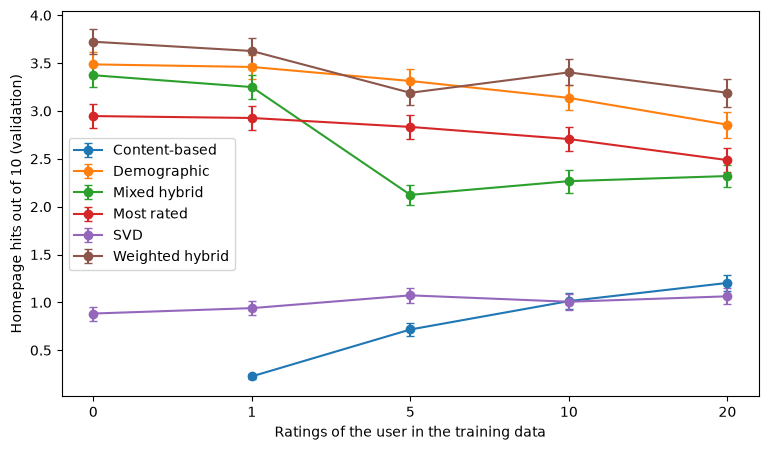

model,Content-based,Demographic,Mixed hybrid,Most rated,SVD,Weighted hybrid
ratings kept,,,,,,
0,NaN,0.125,0.127,0.122,0.073,0.133
1,0.027,0.126,0.125,0.121,0.074,0.134
5,0.064,0.129,0.106,0.122,0.079,0.125
10,0.080,0.131,0.119,0.125,0.082,0.136
20,0.086,0.134,0.119,0.126,0.085,0.144


In [132]:
hits_table = cold_start_df.pivot(index="ratings kept", columns="model", values="hits out of 10")
error_table = cold_start_df.pivot(index="ratings kept", columns="model", values="hits standard error")
x = range(len(hits_table))

plt.figure(figsize=(9, 5))
for name in hits_table.columns:
    plt.errorbar(x, hits_table[name], yerr=error_table[name], marker="o", capsize=3, label=name)
plt.xticks(x, hits_table.index)
plt.xlabel("Ratings of the user in the training data")
plt.ylabel("Homepage hits out of 10 (validation)")
plt.legend()
plt.show()

error_table.round(3)

**For a new user the weighted hybrid is the best choice, followed by demographic, and SVD is the worst.** With no ratings the weighted hybrid finds 3.723 relevant anime per 10 and demographic 3.487, against 2.947 for most rated and 0.883 for SVD. Demographic beats most rated by about three combined standard errors, so the group a user gives at sign-up is worth asking for (2.6). SVD knows nothing about a new user and ranks by the anime bias alone.

Content-based clearly improves with more history, from 0.227 hits at 1 rating to 1.203 at 20. The weighted hybrid dips at 5 ratings, from 3.627 at 1 rating to 3.190 at 5 and back to 3.403 at 10. Content-based needs a few ratings before it helps, and at 5 ratings it is still weak while it carries half the weight of the hybrid. Demographic ignores the history and stays steady. At 5 ratings it is slightly ahead (3.313), but within one standard error. The standard errors are about 0.07 to 0.14.

## 5.5 Switching hybrid

Users are put into five buckets by their number of ratings. These are 0, 1 to 4, 5 to 9, 10 to 19 and 20 or more. For the first four the cold-start experiment gives the hits at the lower edge of the bucket. For 20 or more the full-history comparison from 5.2 and 5.3 is used. Falk gives the same split at 20 ratings as an example [8, p. 336]. In each bucket the model follows the one-standard-error rule from 3.1 with coverage as the tie-break. If one model wins every bucket, switching adds complexity without a gain.

In [133]:
def choose_model(candidates_df):
    # One-standard-error rule from 3.1 with coverage as the tie-break, as in 5.2
    candidates_df = candidates_df.dropna(subset=["hits out of 10"])
    best_row = candidates_df.loc[candidates_df["hits out of 10"].idxmax()]
    close = candidates_df[candidates_df["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
    return close.loc[close["coverage %"].idxmax(), "model"]


# Buckets of 0, 1 to 4, 5 to 9 and 10 to 19 ratings: the cold-start experiment in 5.4
switch_rule = {n_kept: choose_model(cold_start_df[cold_start_df["ratings kept"] == n_kept]) for n_kept in [0, 1, 5, 10]}

# 20 or more ratings: the full-history comparison on the validation split from 5.2 and 5.3
full_history_df = pd.DataFrame([dict(hybrid_tuning[hybrid_tuning[name] == 1].iloc[0], model=name) for name in component_names]
                               + [dict(chosen, model="Weighted hybrid"), dict(mixed_validation, model="Mixed hybrid")])
switch_rule[20] = choose_model(full_history_df)

pd.Series(switch_rule, name="model").rename_axis("from this many ratings").to_frame()

,model
from this many ratings,
0,Weighted hybrid
1,Weighted hybrid
5,Weighted hybrid
10,Weighted hybrid
20,Weighted hybrid


In [134]:
class MySwitchingHybridAlgorithm(AlgoBase):
    def __init__(self, switch_rule):
        AlgoBase.__init__(self)
        self.switch_rule = switch_rule  # smallest number of ratings -> name of the model

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.models = make_components()
        self.models["Weighted hybrid"] = MyWeightedHybridAlgorithm(best_weights)
        self.models["Mixed hybrid"] = MyMixedHybridAlgorithm()
        for name in set(self.switch_rule.values()):  # only the models the rule uses
            self.models[name].fit(trainset)
        return self

    def model_for(self, u):
        n_ratings = len(self.trainset.ur[u]) if self.trainset.knows_user(u) else 0
        bucket = max(edge for edge in self.switch_rule if edge <= n_ratings)
        return self.models[self.switch_rule[bucket]]

    def estimate(self, u, i):
        # Every user gets the scores of one model only, so the scores of different models are never compared
        return self.model_for(u).estimate(u, i)


switching_RS = MySwitchingHybridAlgorithm(switch_rule)
results_part5_df.loc["Switching hybrid"] = pd.Series(evaluate_model(switching_RS))
results_part5_df.loc["Switching hybrid", ["RMSE", "MAE"]] = np.nan
results_part5_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,1.634,0.054,69.6,3.84,0.791,0.316
SVD,1.229,0.919,0.939,0.805,0.521,0.573,0.033,33.0,7.71,0.807,0.281
CB tuned,1.342,1.006,0.921,0.738,0.481,0.464,0.027,30.6,57.26,0.990,0.342
Weighted hybrid,NaN,NaN,0.933,0.783,0.511,1.870,0.057,74.5,11.63,0.885,0.311
Mixed hybrid,NaN,NaN,0.937,0.800,0.517,1.381,0.050,63.5,8.00,0.935,0.313
Switching hybrid,NaN,NaN,0.933,0.783,0.511,1.870,0.057,74.5,11.63,0.885,0.311


**The switch rule picks the weighted hybrid for every history size, so switching adds nothing here.** In every bucket the weighted hybrid has the most hits, or is within one standard error of the best and has the higher coverage. The switching hybrid therefore gives every user the weighted hybrid, and on the test set both find 1.870 relevant anime per 10. As stated above, switching would only add complexity without a gain, so the final system is the weighted hybrid. The switching class stays in the code, so that the rule can change if new data moves the switch points.

The table below shows the test hits per history bucket. In each bucket the switching hybrid has the hits of the model its rule picks.

In [135]:
def hits_per_user(top_n, testset):
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    return pd.Series({uid: len(set(items) & relevant[uid]) for uid, items in top_n.items()})


# Demographic and the weighted hybrid for comparison, plus every model the rule uses
all_models = make_components()
all_models["Weighted hybrid"] = MyWeightedHybridAlgorithm(best_weights)
all_models["Mixed hybrid"] = MyMixedHybridAlgorithm()
bucket_models = {name: all_models[name] for name in {"Demographic", "Weighted hybrid"} | set(switch_rule.values())}
user_hits_df = pd.DataFrame({name: hits_per_user(top_n_unseen(algo.fit(trainset), trainset, users, solve_ties=True), testset)
                             for name, algo in bucket_models.items()})
user_hits_df["ratings in training"] = [len(trainset.ur[trainset.to_inner_uid(uid)]) for uid in user_hits_df.index]
user_hits_df["bucket"] = [max(edge for edge in switch_rule if edge <= n) for n in user_hits_df["ratings in training"]]
user_hits_df["Switching hybrid"] = [user_hits_df.loc[uid, switch_rule[bucket]] for uid, bucket in user_hits_df["bucket"].items()]

by_bucket = user_hits_df.groupby("bucket")[["Demographic", "Weighted hybrid", "Switching hybrid"]].mean()
by_bucket["users"] = user_hits_df.groupby("bucket").size()
by_bucket.index.name = "bucket (ratings in training, from)"
by_bucket.round(3)

,Demographic,Weighted hybrid,Switching hybrid,users
"bucket (ratings in training, from)",,,,
5,0.368,0.474,0.474,19
10,0.422,0.470,0.470,83
20,1.773,2.029,2.029,898


**On the test set the weighted hybrid also beats demographic in every bucket.** From 5 ratings it finds 0.474 hits against 0.368, from 10 ratings 0.470 against 0.422 and from 20 ratings 2.029 against 1.773. Only 19 and 83 of the 1,000 test users are in the two smaller buckets, so these two differences are not reliable on their own. 8.3 tests the final system on new users without any rating.

## 5.6 Conclusion of Part 5

**The weighted hybrid is the best homepage model and the final system, for new and existing users alike.** It beats the best single model, demographic, by 0.236 hits (about 3.0 standard errors) and shows three times as much of the catalog (11.6% against 3.8%). A personal model alone loses to popularity (3.7), but combined with popularity it adds relevant anime that popularity misses. The mixed hybrid is not used, since it has fewer hits and less coverage. The switch rule picks the weighted hybrid for every history size, so switching adds nothing on this data. The offline test favors popular anime (3.7), but this is unlikely to make the hybrid look better than the popularity models, which gain from the bias at least as much. Part 8 tests the final system on other splits and on new users.

# Part 6. Context-aware

A context-aware recommender uses the circumstances of a recommendation, such as the time, the place or the device, besides the user and the item [4, slide 5]. The only context in this data is time. `last_updated` records when a user last changed an anime on their list. There is no device, no location at the moment of watching and no usable hour (Part C). Country is a user attribute, not a context. The question of this part is whether the time of a visit matters and whether it can be used to show better anime.

All models here use Surprise's default SVD, as the S19 notebook uses a plain SVD [5, p. 25]. The question is what the context adds to the same base model.

## 6.1 Context features from last_updated

In [136]:
# Seasons with the same bins as the S19 notebook
bins = [0, 2, 5, 8, 11, 12]
names = ["Winter", "Spring", "Summer", "Autumn", "Winter"]

ratings_df["year"] = ratings_df["last_updated"].dt.year
ratings_df["season"] = pd.cut(ratings_df["last_updated"].dt.month, bins, labels=names, ordered=False)
ratings_df["weekday"] = ratings_df["last_updated"].dt.day_name()
ratings_df["weekend"] = ratings_df["last_updated"].dt.day_of_week >= 5

# Time of every rating, to look it up later for the train and test rows
rating_time = ratings_df.set_index(["user_id", "anime_id"])["last_updated"]
print("One time per user and anime:", rating_time.index.is_unique)
print("Data ends on:", ratings_df["last_updated"].max())
ratings_df[["year", "season", "weekday", "weekend"]].head()

One time per user and anime: True
Data ends on: 2018-05-22 01:51:53


,year,season,weekday,weekend
0,2007,Autumn,Tuesday,False
1,2007,Autumn,Tuesday,False
2,2007,Autumn,Tuesday,False
3,2007,Autumn,Tuesday,False
4,2007,Autumn,Tuesday,False


Year, season and weekday are kept, plus a weekend flag. The season uses the same bins as the S19 notebook [5, p. 17]. `last_updated` is the last edit of an entry, not the moment the anime was watched. A user who changes an old score in 2017 moves that rating to 2017, so the time context is noisy.

## 6.2 Which context variables matter?

T-tests show whether the score differs between context values [4, slide 7]. Each context group is compared with the rest of the ratings. With almost a million ratings nearly any difference is significant, so the size of the difference in points decides.

In [137]:
from scipy import stats


def compare(name, mask):
    x, y = ratings_df.loc[mask, "score"], ratings_df.loc[~mask, "score"]
    t, p = stats.ttest_ind(x, y)
    return {"context": name, "mean in group": x.mean(), "mean rest": y.mean(), "difference": x.mean() - y.mean(), "t": t, "p-value": p}


tests = [compare("weekend", ratings_df["weekend"])]
for season in ["Winter", "Spring", "Summer", "Autumn"]:
    tests.append(compare(season, ratings_df["season"] == season))
tests.append(compare("2017 or later", ratings_df["year"] >= 2017))

pd.DataFrame(tests).set_index("context").round(4)

,mean in group,mean rest,difference,t,p-value
context,,,,,
weekend,7.5808,7.5573,0.0235,6.2584,0.0000
Winter,7.5267,7.5778,-0.0511,-12.8713,0.0000
Spring,7.5889,7.5560,0.0329,8.3387,0.0000
Summer,7.5858,7.5577,0.0281,6.9927,0.0000
Autumn,7.5568,7.5670,-0.0102,-2.4930,0.0127
2017 or later,7.3793,7.5966,-0.2173,-44.4184,0.0000


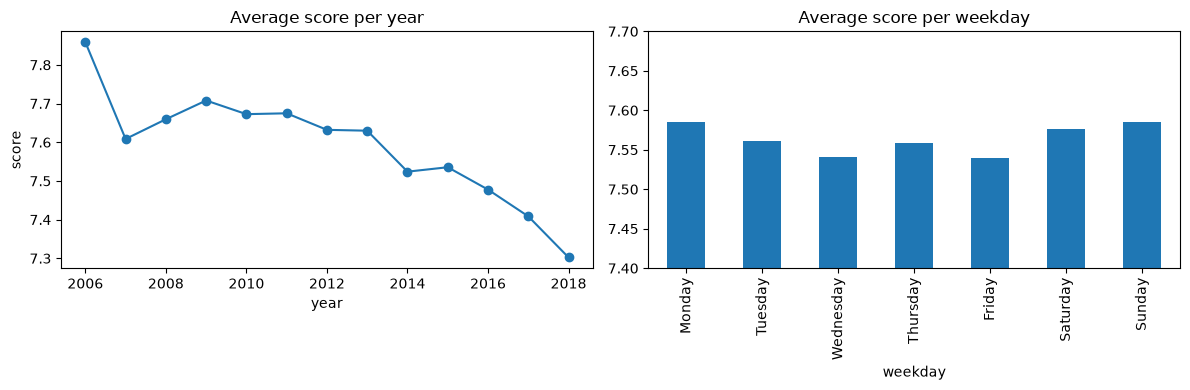

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings_df.groupby("year")["score"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Average score per year")
axes[0].set_ylabel("score")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ratings_df.groupby("weekday")["score"].mean().reindex(order).plot(ax=axes[1], kind="bar")
axes[1].set_ylim(7.4, 7.7)
axes[1].set_title("Average score per weekday")
plt.tight_layout()
plt.show()

**The score barely depends on the weekday or the season, but it does depend on the year.** All tests are significant, mainly because of the number of ratings. Weekend ratings are 0.02 points higher than weekday ratings, and the seasons differ from the rest by 0.01 to 0.05 points on a 10-point scale. The year is different. Ratings from 2017 or later average 7.38 against 7.60 before, a gap of 0.22 points and four times the largest season gap. This continues the downward trend found in Part C. A gap of a few hundredths of a point cannot change which anime come first on a homepage, so weekday and season are not used to predict the score.

The context can also change which anime people watch, even when the scores stay the same [4, slide 7]. The S19 notebook checks this with the most watched genres per context value [5, p. 22]. The first cell below does the same for the seasons. The second measures per year the share of ratings on anime that started airing at most one year earlier, and how many of the 50 most rated anime of a year were also in the top 50 of the year before.

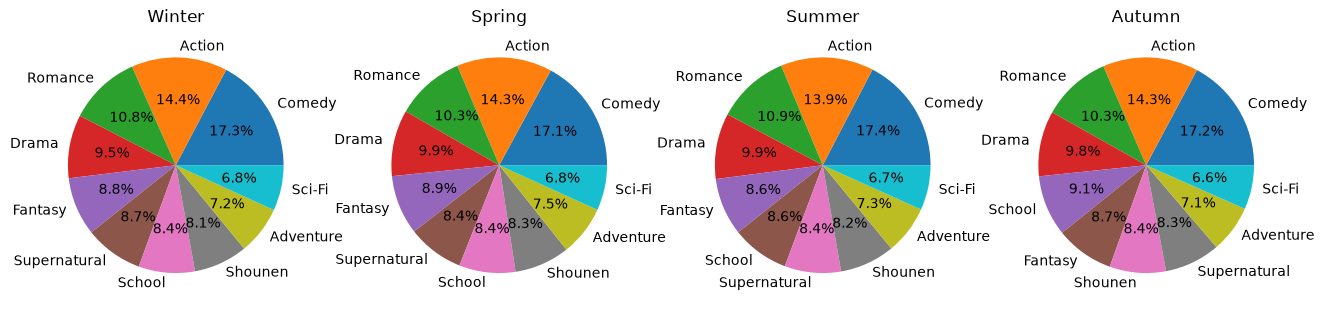

In [139]:
# The check of the S19 notebook: the 10 most watched genres in each season
anime_genres_df = anime_df[["anime_id", "genre"]].assign(genre=anime_df["genre"].str.split(", ")).explode("genre")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, season in zip(axes, ["Winter", "Spring", "Summer", "Autumn"]):
    season_genres_df = pd.merge(ratings_df[ratings_df["season"] == season], anime_genres_df, on="anime_id")
    season_genres_df.groupby("genre").size().sort_values(ascending=False).head(10).plot.pie(ax=ax, autopct="%1.1f%%")
    ax.set_title(season)
    ax.set_ylabel("")
plt.show()

In [140]:
aired_year = anime_df.set_index("anime_id")["aired_from_year"]
ratings_df["anime_age"] = ratings_df["year"] - ratings_df["anime_id"].map(aired_year)

new_share = ratings_df.groupby("year")["anime_age"].apply(lambda a: (a <= 1).mean() * 100)

top50 = {y: set(g["anime_id"].value_counts().head(50).index) for y, g in ratings_df.groupby("year")}
overlap_prev = {y: len(top50[y] & top50[y - 1]) for y in range(2009, 2019)}

pd.DataFrame({"% ratings on anime from the last year": new_share,
              "top 50 shared with previous year": pd.Series(overlap_prev)}).loc[2009:2018].round(1)

,% ratings on anime from the last year,top 50 shared with previous year
2009,27.9,35.0
2010,30.4,26.0
2011,38.1,21.0
2012,39.0,18.0
2013,42.2,18.0
2014,45.1,10.0
2015,46.4,7.0
2016,45.8,13.0
2017,45.3,9.0
2018,42.1,11.0


**Time changes what people watch much more than how they score it.** The 10 most watched genres have almost the same shares in every season, as in the S19 example [5, p. 18]. The year is different. From 2014 to 2018 between 42% and 46% of each year's ratings are on anime that started airing at most one year earlier. In those years only 7 to 13 of the 50 most rated anime of a year were also in the top 50 of the year before, against 35 in 2009. Users mostly watch what is new, and Aggarwal notes that the age of an item can decide whether it is still relevant [14, p. 288]. The useful context for the homepage is therefore what is popular now.

## 6.3 The context used for evaluation

The homepage is shown now. The data ends in May 2018, so "now" is the last 12 months of the data, and the test ratings from that period form the context test set. The models are still trained on `trainset` from 1.3. Only the evaluation is restricted to the context.

In [141]:
data_end = ratings_df["last_updated"].max()
context_start = data_end - pd.Timedelta(days=365)


def add_time(df):
    df = df.copy()
    df["last_updated"] = rating_time.reindex(pd.MultiIndex.from_frame(df[["user_id", "anime_id"]])).values
    return df


test_time_df = add_time(pd.DataFrame(testset, columns=["user_id", "anime_id", "score"]))
train_time_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                      columns=["user_id", "anime_id", "score"]))

in_context = test_time_df["last_updated"] >= context_start
context_testset = list(test_time_df.loc[in_context, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))

# Homepage users: the 1,000 users from Part 1 that liked at least one anime in the context period
liked_in_context = {u for u, i, r in context_testset if r >= relevant_score}
context_users = [u for u in users if u in liked_in_context]

print("Context period:", context_start.date(), "to", data_end.date())
print("Test ratings in the context:", len(context_testset), "of", len(testset))
print("Users with test ratings in the context:", test_time_df.loc[in_context, "user_id"].nunique())
print("Homepage users (of the 1,000) with a liked anime in the context:", len(context_users))

Context period: 2017-05-22 to 2018-05-22
Test ratings in the context: 20570 of 195413
Users with test ratings in the context: 2001
Homepage users (of the 1,000) with a liked anime in the context: 337


Only about 1 in 10 test ratings falls in the last year (20,570 of 195,413). The homepage metric uses the users among the 1,000 from Part 1 who liked at least one anime in that period (337 users). Users without a liked test anime in the period would get 0 hits from every model, which would only dilute the differences.

## 6.4 Pre-filtering

Pre-filtering removes the training ratings outside the context and trains a normal model on the rest [4, slides 14-16]. The S19 notebook trains one SVD per context value and compares its NDCG with one SVD on all ratings [5, pp. 25-27]. The cell below does this for the seasons. Both models are tested on the same test ratings of each season, so that the comparison is fair.

In [142]:
def ndcg_by_user(predictions):
    predictions_byuser_df = pd.DataFrame(predictions).groupby("uid")[["r_ui", "est"]].agg(list)
    return ndcg_multiple_users(predictions_byuser_df["r_ui"].tolist(), predictions_byuser_df["est"].tolist())


for df in (train_time_df, test_time_df):
    df["season"] = pd.cut(df["last_updated"].dt.month, bins, labels=names, ordered=False)

all_svd = SVD(random_state=my_seed)
all_svd.fit(trainset)

season_rows = {}
for season in ["Winter", "Spring", "Summer", "Autumn"]:
    season_train_df = train_time_df.loc[train_time_df["season"] == season, ["user_id", "anime_id", "score"]]
    season_svd = SVD(random_state=my_seed)
    season_svd.fit(Dataset.load_from_df(season_train_df, reader).build_full_trainset())
    season_testset = list(test_time_df.loc[test_time_df["season"] == season, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    season_rows[season] = {"SVD on all ratings": ndcg_by_user(all_svd.test(season_testset)),
                           "SVD on this season only": ndcg_by_user(season_svd.test(season_testset))}

pd.DataFrame(season_rows).T.round(4)

,SVD on all ratings,SVD on this season only
Winter,0.9492,0.9421
Spring,0.9486,0.9441
Summer,0.9502,0.9444
Autumn,0.9510,0.9467


**A separate SVD per season ranks worse than one SVD on all ratings.** In every season the SVD on all ratings has the higher NDCG@5 (0.949 to 0.951 against 0.942 to 0.947). Trained on a quarter of the data, each season model knows the users less well. This is the sparsity problem of pre-filtering [14, p. 289].

The season is not the context that matters here (6.2). The pre-filter is therefore also tried on time windows, with an SVD on the last year or the last 3 years [14, p. 289]. A user or anime missing from the window falls back to the SVD on all ratings.

In [143]:
class MyPreFilterSVD(AlgoBase):
    def __init__(self, start):
        AlgoBase.__init__(self)
        self.start = start

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.global_svd = SVD(random_state=my_seed)
        self.global_svd.fit(trainset)

        # Keep only the training ratings from the context window
        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        recent_df = train_df[train_df["last_updated"] >= self.start]
        self.recent_trainset = Dataset.load_from_df(recent_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
        self.recent_svd = SVD(random_state=my_seed)
        self.recent_svd.fit(self.recent_trainset)
        self.recent_users = set(recent_df["user_id"])
        self.recent_items = set(recent_df["anime_id"])
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            return self.global_svd.estimate(u, i)
        raw_u, raw_i = self.trainset.to_raw_uid(u), self.trainset.to_raw_iid(i)
        if raw_u in self.recent_users and raw_i in self.recent_items:
            return self.recent_svd.predict(raw_u, raw_i).est
        # Fall back to the model trained on all the data
        return self.global_svd.estimate(u, i)

## 6.5 Post-filtering

Post-filtering trains a normal model on all ratings and adjusts the ranking with the context afterwards [4, slide 18]. 6.2 showed that time changes which anime are watched, so the post-filter moves up the anime that many users rated in the last year.

score with context = SVD score + weight × context popularity

Context popularity is log(1 + ratings of the anime in the last year), scaled to 0 to 1. A weight of 0 gives the normal SVD. Aggarwal multiplies the predicted rating by a contextual weight instead [14, pp. 289-290]. An additive boost is used so that the weight directly sets how far the context can move an anime up.

In [144]:
class MyPostFilterSVD(AlgoBase):
    def __init__(self, start, weight):
        AlgoBase.__init__(self)
        self.start = start
        self.weight = weight

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.svd = SVD(random_state=my_seed)
        self.svd.fit(trainset)

        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        counts = train_df[train_df["last_updated"] >= self.start].groupby("anime_id").size()
        popularity = np.log1p(counts) / np.log1p(counts.max())
        self.context_popularity = {trainset.to_inner_iid(a): p for a, p in popularity.items()}
        return self

    def estimate(self, u, i):
        score = self.svd.estimate(u, i) + self.weight * self.context_popularity.get(i, 0)
        # The boost can push a score above 10, and Surprise clips predictions to the rating scale, which would
        # turn the top of the list into ties. Moving the range 1 to 10 + weight back onto 1 to 10 keeps the order
        return 1 + (score - 1) * 9 / (9 + self.weight)

### A baseline: most rated in the last year

The post-filter mixes the user's taste from the SVD and the recent popularity of each anime. This baseline ranks the anime by their number of ratings in the last year, like most rated from Part 2. If the post-filter does not beat it, the gain comes from recency and not from personalization.

In [145]:
class MyRecentMostRatedAlgorithm(AlgoBase):
    def __init__(self, start):
        AlgoBase.__init__(self)
        self.start = start

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        counts = train_df[train_df["last_updated"] >= self.start].groupby("anime_id").size()
        self.recent_count = {trainset.to_inner_iid(a): n for a, n in counts.items()}
        self.max_count = counts.max()
        return self

    def estimate(self, u, i):
        # Number of ratings in the context period, moved onto the 1 to 10 scale as in MyMostRatedAlgorithm
        return 1 + 9 * self.recent_count.get(i, 0) / self.max_count

### Choosing the weight

The weight is chosen on the validation split from 1.3 with the one-standard-error rule from 3.1. It is judged by the homepage hits on the validation ratings from the context period. The grid goes up to 30, so that the choice is not stuck at its edge.

In [146]:
# Same validation split as in Part 3
val_time_df = add_time(pd.DataFrame(tune_valset, columns=["user_id", "anime_id", "score"]))
context_valset = list(val_time_df.loc[val_time_df["last_updated"] >= context_start, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
val_liked = {u for u, i, r in context_valset if r >= relevant_score}
val_context_users = [u for u in eval_users(tune_trainset, n=1000) if u in val_liked]
print("Validation users with a liked anime in the context:", len(val_context_users))

tuning_rows = []
for weight in [0, 0.5, 1, 3, 10, 30]:
    algo = MyPostFilterSVD(context_start, weight)
    algo.fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_context_users, solve_ties=True)
    row = {"weight": weight}
    row.update(homepage_hits(top_n, context_valset))
    row["RMSE"] = accuracy_metrics(algo.test(context_valset))["RMSE"]
    tuning_rows.append(row)

weight_tuning_df = pd.DataFrame(tuning_rows).set_index("weight")
# One-standard-error rule from 3.1: ties within one standard error go to the lower validation RMSE
best_post_weight = choose_setting(weight_tuning_df.reset_index())["weight"]
print("Best weight:", best_post_weight)
weight_tuning_df.round(3)

Validation users with a liked anime in the context: 274
Best weight: 10.0


,hits out of 10,hits standard error,users with at least 1 hit %,RMSE
weight,,,,
0.0,0.124,0.023,10.584,1.251
0.5,0.157,0.025,13.504,1.247
1.0,0.208,0.029,17.883,1.253
3.0,0.350,0.034,30.657,1.338
10.0,0.478,0.044,37.226,1.694
30.0,0.460,0.044,35.401,2.131


**The more weight the context gets, the more homepage hits on validation.** The plain SVD (weight 0) finds 0.124 relevant anime per 10 among the validation ratings from the last year. A weight of 1 finds 0.208, 3 finds 0.350 and 10 finds 0.478. RMSE gets worse as the weight grows (from 1.251 to 1.694), since the boost changes the scores on purpose. The post-filter is a ranking model, so the homepage hits decide. At a weight of 10 the boost is as large as the whole rating scale, and recent popularity decides most of the ranking. The baseline below tests whether this is still personalization.

## 6.6 Results on the context test set

The metrics of 1.4 on the test ratings from the last year. Random (today's homepage), most rated and most rated in the last year are included for comparison.

In [147]:
part6_models = {
    "Random": MyRandomAlgorithm(),
    "Most rated": MyMostRatedAlgorithm(),
    "Most rated, last year": MyRecentMostRatedAlgorithm(context_start),
    "SVD (no context)": SVD(random_state=my_seed),
    "Pre-filter SVD, 1 year": MyPreFilterSVD(context_start),
    "Pre-filter SVD, 3 years": MyPreFilterSVD(data_end - pd.Timedelta(days=3 * 365)),
    f"Post-filter SVD, weight {best_post_weight}": MyPostFilterSVD(context_start, best_post_weight),
}

part6_results = defaultdict(dict)
part6_top_n = {}
for name, algo in part6_models.items():
    algo.fit(trainset)
    predictions = algo.test(context_testset)
    part6_results[name].update(accuracy_metrics(predictions))
    part6_results[name].update(test_ranking_metrics(predictions))
    top_n = top_n_unseen(algo, trainset, context_users, solve_ties=(name != "Random"))
    part6_top_n[name] = top_n
    part6_results[name].update(homepage_hits(top_n, context_testset))

results_part6_df = pd.DataFrame(part6_results).T
results_part6_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,hits out of 10,hits standard error,users with at least 1 hit %
Random,2.402,1.891,0.924,0.700,0.671,2001.0,0.003,0.003,0.297
Most rated,5.412,5.075,0.944,0.767,0.732,2001.0,0.240,0.035,16.617
"Most rated, last year",5.608,5.255,0.943,0.767,0.733,2001.0,0.730,0.055,48.368
SVD (no context),1.229,0.910,0.969,0.857,0.813,2001.0,0.234,0.031,18.398
"Pre-filter SVD, 1 year",1.266,0.947,0.965,0.846,0.804,2001.0,0.231,0.029,18.398
"Pre-filter SVD, 3 years",1.235,0.916,0.968,0.858,0.814,2001.0,0.231,0.031,18.398
"Post-filter SVD, weight 10.0",1.649,1.308,0.959,0.820,0.780,2001.0,0.795,0.056,51.335


**For users who visit now, the post-filter finds over three times as many relevant anime as the SVD without context, but most of that gain is recency.** It finds 0.795 relevant anime per 10, and 51.3% of the context users get at least one. The SVD without context finds 0.234 (18.4%) and random 0.003. Most rated in the last year, which ignores the user, finds 0.730 (48.4%). The post-filter beats it by only 0.065 hits, less than one combined standard error. All-time most rated finds 0.240, so what matters is popularity now.

**The window pre-filter does not help either.** The SVD on the last year gives 0.231 hits and a worse RMSE (1.266 against 1.229), and 3 years is almost the same as the normal SVD. The last year holds only about a tenth of the training ratings, the same sparsity problem as for the seasons. The ranking metrics on each user's test anime barely differ between the SVD models, since they only reorder anime the user already rated (2.4).

### Coverage, personalization and diversity

As in 1.4, these use `full_trainset` and the 1,000 users from Part 1. The median start year of the shown anime measures how recent the lists are.

In [148]:
part6_beyond = {}
for name in ["SVD (no context)", f"Post-filter SVD, weight {best_post_weight}", "Most rated, last year"]:
    algo = part6_models[name]
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
    part6_beyond[name] = beyond_accuracy_metrics(top_n, full_trainset)
    # How recent the shown anime are
    shown = [i for items in top_n.values() for i in items]
    part6_beyond[name]["median aired year of shown anime"] = aired_year.reindex(shown).median()

pd.DataFrame(part6_beyond).T.round(3)

,coverage %,personalization,intra-list similarity,median aired year of shown anime
SVD (no context),14.00,0.911,0.268,2012.0
"Post-filter SVD, weight 10.0",2.47,0.481,0.289,2017.0
"Most rated, last year",1.09,0.240,0.306,2017.0


**The recency gain costs most of the catalog and most of the personalization.** With the post-filter the median start year of the shown anime moves from 2012 to 2017. But coverage falls from 14.0% to 2.5% and personalization from 0.911 to 0.481, so many users get largely the same recent anime. Recent popularity alone goes further (1.1% coverage, personalization 0.240). This works against the goal from 2.6 of showing more of the catalog. The weight is the lever between the two, and the offline test prefers the largest weight, which is not necessarily right for the platform.

## 6.7 Cross-validation through time

The random split lets the models learn from the future (1.3), which matters for a part about time. Cross-validation through time trains every model on the past and tests it on the next period [6, p. 28]. In each fold "now" is the last 12 months of the training fold. The homepage metric uses 300 random users per fold.

In [149]:
cvtt_rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    fold_trainset = Dataset.load_from_df(train_fold[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    fold_testset = list(test_fold[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    fold_now = train_fold["last_updated"].max() - pd.Timedelta(days=365)

    # Homepage users: known in training and liked something in the test fold
    liked = set(test_fold.loc[test_fold["score"] >= relevant_score, "user_id"]) & set(train_fold["user_id"])
    rng = np.random.default_rng(my_seed)
    fold_users = list(rng.choice(sorted(liked), size=min(300, len(liked)), replace=False))

    for name, algo in {"SVD (no context)": SVD(random_state=my_seed),
                       "Pre-filter SVD, 1 year": MyPreFilterSVD(fold_now),
                       "Most rated, last year": MyRecentMostRatedAlgorithm(fold_now),
                       f"Post-filter SVD, weight {best_post_weight}": MyPostFilterSVD(fold_now, best_post_weight)}.items():
        algo.fit(fold_trainset)
        predictions = algo.test(fold_testset)
        # The scores of recent popularity are counts, not ratings, so it has no RMSE
        row = {"fold": fold, "model": name,
               "RMSE": np.nan if name == "Most rated, last year" else accuracy_metrics(predictions)["RMSE"]}
        row.update(homepage_hits(top_n_unseen(algo, fold_trainset, fold_users, solve_ties=True), fold_testset))
        cvtt_rows.append(row)

cvtt_df = pd.DataFrame(cvtt_rows)
cvtt_df.pivot(index="fold", columns="model", values="hits out of 10").round(3)

model,"Most rated, last year","Post-filter SVD, weight 10.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,,
1,1.093,1.217,0.867,0.817
2,1.100,1.360,0.730,0.760
3,0.997,1.290,0.693,0.687
4,0.870,1.077,0.567,0.563
5,1.053,1.660,0.917,0.963


In [150]:
cvtt_df.pivot(index="fold", columns="model", values="RMSE").round(3)

model,"Most rated, last year","Post-filter SVD, weight 10.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,,
1,NaN,2.534,1.541,1.541
2,NaN,2.526,1.497,1.494
3,NaN,2.554,1.526,1.518
4,NaN,2.551,1.484,1.475
5,NaN,2.512,1.498,1.494


**Cross-validation through time confirms the gain and shows that it is more than recency.** In all 5 folds the post-filter finds the most homepage hits, between 1.077 and 1.660 per 10. Most rated in the last year finds 0.870 to 1.100 and the SVD without context 0.563 to 0.963. On the random split the post-filter and recent popularity were within noise. Here the post-filter wins in every fold, by 0.12 to 0.61 hits, so its personal part does add something. The pre-filter is again about the same as the normal SVD. The hits are higher than on the random split because the test fold holds all future ratings of a user.

## 6.8 Example: one user's homepage

The top 10 of one context user with the normal SVD and with the post-filter. A ✓ means the user rated the anime 8 or more in the test set.

In [151]:
liked_test = defaultdict(set)
for u, i, r in context_testset:
    if r >= relevant_score:
        liked_test[u].add(i)

post_name = f"Post-filter SVD, weight {best_post_weight}"
# Pick the user where the post-filter gains the most hits
gain = {u: len(set(part6_top_n[post_name][u]) & liked_test[u]) - len(set(part6_top_n["SVD (no context)"][u]) & liked_test[u]) for u in context_users}
context_example_user = max(gain, key=gain.get)

def show(items):
    return [titles[i] + (" ✓" if i in liked_test[context_example_user] else "") for i in items]

pd.DataFrame({"SVD (no context)": show(part6_top_n["SVD (no context)"][context_example_user]),
              "Post-filter": show(part6_top_n[post_name][context_example_user])}, index=range(1, 11))

,SVD (no context),Post-filter
1,Shinsekai yori,Shingeki no Kyojin Season 2 ✓
2,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,Tsuki ga Kirei ✓
3,Steins;Gate,Steins;Gate
4,Steins;Gate 0,No Game No Life: Zero ✓
5,Ginga Eiyuu Densetsu: Arata Naru Tatakai no Ov...,Sora yori mo Tooi Basho ✓
6,Toradora! ✓,Dragon Ball Super
7,Uchuu Senkan Yamato 2199,Yuru Camp△
8,Kyousou Giga (TV),Overlord II ✓
9,Majo no Takkyuubin,Re:Zero kara Hajimeru Isekai Seikatsu ✓
10,Kill la Kill Specials,Houseki no Kuni (TV)


**The post-filter turns a list of older classics into a list of current anime.** Without context this user gets mostly older anime, such as Majo no Takkyuubin and Shinsekai yori, and one of the ten is a hit. With the post-filter the list is mostly anime from 2017 and 2018, such as Shingeki no Kyojin Season 2 and Tsuki ga Kirei, and six of the ten are hits. Steins;Gate stays in both lists, so the user's taste is still present. This user was chosen as the one where the post-filter gains the most, so it is a best case.

## 6.9 Conclusion of Part 6

**Time is the one context in this data that matters, and it matters through what users watch, not through how they score.** Weekday and season barely change the score, and a separate SVD per season ranks worse than one on all ratings. Recent popularity is what counts. The post-filter finds 0.795 relevant anime per 10 for users who visit now, against 0.234 for the same SVD without context and 0.003 for today's random homepage. Most of this gain is recency, but the post-filter beats recent popularity in every CVTT fold.

Contextual modelling, which puts the context into the model itself [4, slide 19], is not built. It needs a lot of data and overfits as context dimensions are added [14, p. 279], and the only context here is one noisy date. The limits are that `last_updated` is not the moment of watching and that the offline test rewards recency without limit, while coverage falls to 2.5%. The right weight must come from an online test, so Part 8 treats the boost as an A/B test arm.

# Part 7. Bandits

Every model so far is trained once and then only exploits what it learned. Anime that few users have rated rarely reach the homepage, so they never collect the feedback that could prove them good. A multi-armed bandit balances exploring uncertain anime and exploiting known ones, which also helps with new anime [24, slide 3]. This part uses Thompson sampling as in the S22 notebooks [24, slide 7] [25]. Each anime gets a Beta distribution of its probability of being liked. The bandit draws one value per anime and shows the 10 highest draws. A well-known anime has a narrow distribution and stable draws. An anime with little feedback has a wide distribution, so it sometimes draws high and gets explored.

## 7.1 A Beta distribution per anime

The reward is whether the user liked the anime, a score of 8 or more, as in every other part. The successes of an anime are its liked ratings in the training data and the failures are its other ratings [26, p. 1]. Both start with a prior of 1, because the Beta distribution needs values above 0 and every anime should start from the same belief [25, pp. 3, 6]. Adult anime are left out, as in 1.4. The implicit label from 1.2 would give more data, but it rewards finishing an anime rather than liking it.

In [152]:
train_ratings_df = pd.DataFrame([(trainset.to_raw_iid(i), r) for (_, i, r) in trainset.all_ratings()], columns=["anime_id", "score"])
train_ratings_df["liked"] = (train_ratings_df["score"] >= relevant_score).astype(int)

beta_df = train_ratings_df.pivot_table(index="anime_id", columns="liked", aggfunc="size").fillna(0).astype(int)
beta_df = beta_df[[1, 0]]  # successes first, then failures, as the Beta distribution expects
beta_df = beta_df[~beta_df.index.isin(adult_anime)]
beta_df += 1
beta_df["num_ratings"] = beta_df[1] + beta_df[0] - 2
beta_df.insert(0, "title", titles.reindex(beta_df.index).values)
beta_df.sort_values("num_ratings", ascending=False).head()

liked,title,1,0,num_ratings
anime_id,,,,
1535,Death Note,2268,440,2706
1575,Code Geass: Hangyaku no Lelouch,1809,317,2124
11757,Sword Art Online,1354,749,2101
20,Naruto,1114,967,2079
16498,Shingeki no Kyojin,1650,372,2020


**The famous anime have narrow distributions and differ clearly in how often they are liked.** Death Note was rated by 2,706 users in the training data and liked by 84% of them. Sword Art Online was liked by 64% of its 2,101 raters and Naruto by 54% of its 2,079 (the columns 1 and 0 include the prior of 1). With thousands of ratings their draws hardly change, so the bandit exploits them. An anime with a few ratings has a wide distribution, which is where the exploration comes from.

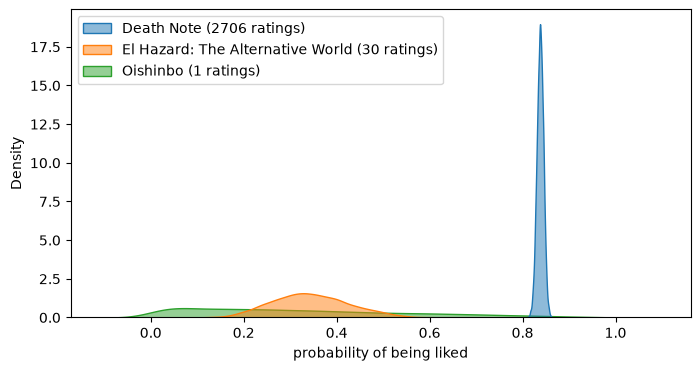

In [153]:
import seaborn as sns


# plot_beta from the S22 notebook, with titles in the legend instead of (alpha, beta)
def plot_beta(items):
    dict_data = {}
    for name, (alpha, beta) in items.items():
        dict_data[name] = np.random.beta(alpha, beta, size=10000)
    plt.subplots(figsize=(8, 4))
    sns.kdeplot(data=pd.DataFrame(dict_data), alpha=.5, fill=True)
    plt.xlabel("probability of being liked")
    plt.show()


# A famous anime, an anime with a few dozen ratings and one with a single rating
examples = [beta_df["num_ratings"].idxmax(),
            beta_df[beta_df["num_ratings"] == 30].index[0],
            beta_df[beta_df["num_ratings"] == 1].index[0]]
plot_beta({f"{beta_df.loc[a, 'title']} ({beta_df.loc[a, 'num_ratings']} ratings)": (beta_df.loc[a, 1], beta_df.loc[a, 0])
           for a in examples})

## 7.2 Homepage slots: famous anime against new anime

The prior decides how much the bandit explores [25, pp. 4-5]. Here the 20 anime with the most ratings compete with 50 anime with at most 3 ratings, as in the S22 experiment with new items against the top item [25, pp. 11-14]. The bandit draws from all 70 distributions 10,000 times and each time shows the 10 highest. S22 counts only the single highest draw, but a homepage has 10 slots. Extra failures in the prior make the bandit trust new anime less. With 2 extra failures a new anime starts as if it had been shown twice without being liked. S22 adds 20 because a purchase is rare [25, p. 13]. Here 56% of the ratings are liked, so a much smaller prior already has a strong effect.

In [154]:
def compute_probability(beta_df, n_sample=10_000, n=10):
    # Share of the draws in which each anime is among the n highest, i.e. shown on the homepage
    alphas = beta_df[1].to_numpy()
    betas = beta_df[0].to_numpy()
    shown = Counter()
    for _ in range(n_sample):
        rewards = np.random.beta(alphas, betas)
        for position in np.argpartition(-rewards, n - 1)[:n]:
            shown[beta_df.index[position]] += 1
    return pd.Series(shown).reindex(beta_df.index).fillna(0) / n_sample * 100


famous = beta_df.sort_values("num_ratings", ascending=False).head(20)
new = beta_df[beta_df["num_ratings"] <= 3].sample(50, random_state=my_seed)
competition_df = pd.concat([famous, new])

rows = {}
for extra_failures in [0, 1, 2, 5, 20]:
    prior_df = competition_df.copy()
    prior_df[0] += extra_failures
    probability = compute_probability(prior_df)
    # Probabilities are per anime, so their sum over a group is the expected number of the 10 slots, times 10
    rows[extra_failures] = {"slots for famous anime": probability[famous.index].sum() / 100,
                            "slots for new anime": probability[new.index].sum() / 100}

selection_df = pd.DataFrame(rows).T
selection_df.index.name = "extra failures in the prior"
selection_df.round(2)

,slots for famous anime,slots for new anime
extra failures in the prior,,
0,6.13,3.87
1,8.62,1.38
2,9.53,0.47
5,9.99,0.01
20,10.00,0.00


**The prior sets how much of the homepage goes to exploration.** Without extra failures, anime with at most 3 ratings take 3.87 of the 10 slots, although the famous anime have thousands of ratings. One extra failure lowers this to 1.38 slots, 2 to 0.47 and 5 to 0.01, and 20 shuts new anime out.

## 7.3 Bandit homepage with the Part 1 metrics

The bandit is written as a Surprise algorithm, so that it is evaluated like every other model. `estimate()` returns a new draw from the anime's Beta distribution, so each visit gives a different homepage.

The prior is a business choice, since each business sets it by its goals [25, p. 5]. Too much exploration hurts the user experience and too much exploitation misses long-term value [24, slide 3]. One extra failure is chosen. It leaves new anime about 1.4 of 10 slots against the most famous anime (7.2), so they get a chance but must earn likes to stay. The prior is not tuned offline. An offline test can only reward anime a user already rated, never a discovery, so it always favors the least exploration [19, p. 97].

In [155]:
class MyThompsonSamplingAlgorithm(AlgoBase):
    def __init__(self, extra_failures=0):
        AlgoBase.__init__(self)
        self.extra_failures = extra_failures

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.successes, self.failures = defaultdict(int), defaultdict(int)
        for _, i, r in trainset.all_ratings():
            if r >= relevant_score:
                self.successes[i] += 1
            else:
                self.failures[i] += 1
        return self

    def estimate(self, u, i):
        # Prior of 1 success and 1 + extra_failures failures, plus the feedback of the anime
        draw = np.random.beta(1 + self.successes[i], 1 + self.extra_failures + self.failures[i])
        # Surprise clips predictions to the 1 to 10 scale, so the draw is moved onto it. The order stays the same
        return 1 + 9 * draw

In [156]:
# One extra failure in the prior, a business choice (7.3)
chosen_failures = 1
bandit_models = {f"Thompson sampling, {chosen_failures} extra failures": MyThompsonSamplingAlgorithm(extra_failures=chosen_failures)}

# The draws are random, so the seed is set again to make the results reproducible
np.random.seed(my_seed)
results_bandit = {}
for name, algo in bandit_models.items():
    results_bandit[name] = evaluate_model(algo)
    results_bandit[name].pop("RMSE")
    results_bandit[name].pop("MAE")

results_part7_df = pd.concat([results_part5_df.loc[["Random", "Most rated"]], pd.DataFrame(results_bandit).T])
results_part7_df.drop(columns=["RMSE", "MAE"]).round(3)

,NDCG@10,MAP@10,MAR@10,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,0.861,0.560,0.389,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,0.898,0.676,0.448,1.449,0.050,65.5,1.72,0.615,0.329
"Thompson sampling, 1 extra failures",0.931,0.783,0.508,0.296,0.020,22.8,6.32,0.731,0.244


RMSE and MAE are left out for the bandit. Its scores are random draws of the probability of being liked, not predicted ratings, so a rating error means nothing for it. The ranking metrics only use the order of the scores, so they still apply.

**As a full homepage, the bandit finds far fewer relevant anime than the popularity models.** With 1 extra failure it finds 0.296 relevant anime per 10 on the test set and reaches 22.8% of users, against 1.449 and 65.5% for most rated and 0.042 for random. Part of its homepage goes to anime with little feedback, and an offline test cannot reward that [19, p. 97]. As the whole homepage it would cost too many hits, so Part 8 gives it one slot.

## 7.4 Learning over time

In production the Beta distributions are updated with every new rating [25, p. 15]. This is simulated with `last_updated`, as in the S22 simulation [25, pp. 16-17]. Every month from January 2017 the distributions are rebuilt from the ratings until then. The table shows the probability that Made in Abyss is among the 10 anime shown against the same 20 famous anime. Made in Abyss started airing in July 2017.

Average score of Made in Abyss: 8.84


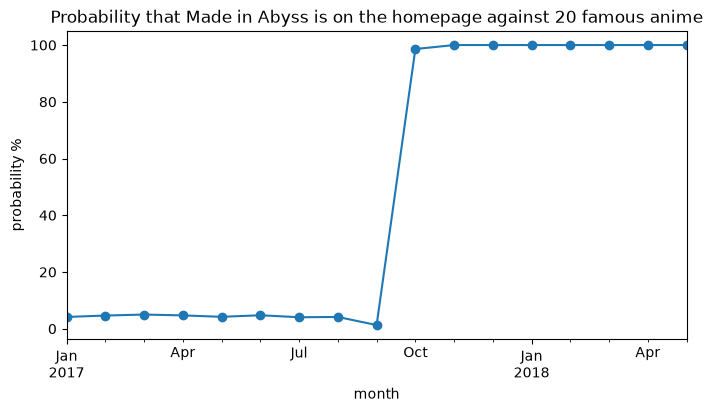

month,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01
probability %,4.2,4.6,5.0,4.7,4.2,4.8,4.0,4.2,1.3,98.6,100.0,100.0,100.0,100.0,100.0,100.0,100.0
ratings so far,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,11.0,133.0,326.0,386.0,428.0,481.0,511.0,549.0,571.0


In [157]:
made_in_abyss = 34599
extra_failures = chosen_failures  # the prior from 7.3
dates = pd.date_range("2017-01-01", "2018-05-01", freq="MS")

probability_over_time = []
for date in dates:
    ratings_until_date = ratings_df[(ratings_df["last_updated"] < date) & ~ratings_df["anime_id"].isin(adult_anime)]
    liked = (ratings_until_date["score"] >= relevant_score).astype(int)
    beta_until_date = ratings_until_date.assign(liked=liked).pivot_table(index="anime_id", columns="liked", aggfunc="size").fillna(0)
    beta_until_date = beta_until_date.reindex(list(famous.index) + [made_in_abyss], fill_value=0)[[1, 0]] + 1
    beta_until_date[0] += extra_failures
    probability = compute_probability(beta_until_date, n_sample=2_000)
    probability_over_time.append({"month": date, "probability %": probability[made_in_abyss],
                                  "ratings so far": int(beta_until_date.loc[made_in_abyss, [1, 0]].sum() - 2 - extra_failures)})

print("Average score of Made in Abyss:", round(ratings_df.loc[ratings_df["anime_id"] == made_in_abyss, "score"].mean(), 2))
over_time_df = pd.DataFrame(probability_over_time).set_index("month")
over_time_df["probability %"].plot(marker="o", figsize=(8, 4), title="Probability that Made in Abyss is on the homepage against 20 famous anime")
plt.ylabel("probability %")
plt.show()
over_time_df.round(1).T

**Once Made in Abyss collects feedback, the bandit puts it on the homepage within a few months.** Until August 2017 it has no or only a few ratings and is shown in about 4% of the draws, from the prior alone. In September, with 11 ratings, this falls to 1.3%. With 133 ratings in October it is shown in 98.6% of the draws, and from November it is always shown. Its average score is 8.84, against 7.56 for all ratings (2.2). A new anime that users like reaches the homepage as soon as the evidence is there, without anyone deciding it by hand. A prior with more exploration would show it earlier, at the cost of also showing more new anime that users do not like.

## 7.5 Conclusion of Part 7

**The bandit keeps learning from new feedback, but offline it cannot show its value, so it gets one slot of the homepage.** It is the only model that learns after training. Every other model must be retrained to notice a new anime, and popularity only shows it once it has more ratings than the anime at the top. The prior is a business choice of 1 extra failure, which gives new anime a chance without crowding out proven ones. The right amount of exploration can only be measured with real users, so Part 8 tests the bandit as one slot, which limits the cost of exploring.

# Part 8. Final system and business value

The final system is the weighted hybrid from 5.2, which the switch rule of 5.5 picks for every user, including new users. Its weights were chosen on the validation split. In the code it runs through the switching class from 5.5. 8.1 checks that the choice does not depend on the split. 8.2 tests the recency boost from Part 6 and a bandit slot from Part 7 as two arms for an A/B test. 8.3 tests the system on new users and 8.4 sums up its business value.

## 8.1 Robustness check of the final system

The random split from 1.3 lets models learn from ratings given after the test ratings, and it can leave a user with few test ratings by chance. The final system and the baselines are therefore tested in two other ways with the homepage hits. If the order of the models stays the same, the choice does not depend on the split.

1. **Per-user split.** Every user has 20% of their own ratings in the test set [6, p. 28].
2. **CVTT.** Each fold trains on the past and tests on the period after it [6, p. 28]. As in Part 6, each fold uses 300 random users who have training history and liked an anime in the test period.

In [158]:
def final_candidates():
    # New, unfitted models every time
    return {
        "Random": MyRandomAlgorithm(),
        "Most rated": MyMostRatedAlgorithm(),
        "Demographic": MyDemographicAlgorithm(user_group),
        "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
        "Final system": MySwitchingHybridAlgorithm(switch_rule),
    }


per_user_users = eval_users(trainset_per_user)
per_user_rows = {}
for name, algo in final_candidates().items():
    algo.fit(trainset_per_user)
    top_n = top_n_unseen(algo, trainset_per_user, per_user_users, solve_ties=(name != "Random"))
    per_user_rows[name] = homepage_hits(top_n, testset_per_user)

pd.DataFrame(per_user_rows).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
Random,0.041,0.006,4.0
Most rated,1.433,0.048,65.3
Demographic,1.625,0.053,70.0
SVD,0.583,0.034,32.7
Final system,1.883,0.057,74.0


**On the per-user split the final system is again the best model.** It finds 1.883 relevant anime per 10 and reaches 74.0% of users, against 1.625 and 70.0% for demographic, 1.433 for most rated, 0.583 for SVD and 0.041 for random. The gain over demographic is about 3.3 combined standard errors, and the order of the models is the same as in 5.5.

In [159]:
cvtt_final_rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    fold_trainset = Dataset.load_from_df(train_fold[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    fold_testset = list(test_fold[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))

    # Homepage users: known in training and liked something in the test fold
    liked = set(test_fold.loc[test_fold["score"] >= relevant_score, "user_id"]) & set(train_fold["user_id"])
    rng = np.random.default_rng(my_seed)
    fold_users = list(rng.choice(sorted(liked), size=min(300, len(liked)), replace=False))

    for name, algo in final_candidates().items():
        algo.fit(fold_trainset)
        top_n = top_n_unseen(algo, fold_trainset, fold_users, solve_ties=(name != "Random"))
        row = {"fold": fold, "model": name}
        row.update(homepage_hits(top_n, fold_testset))
        cvtt_final_rows.append(row)

cvtt_final_df = pd.DataFrame(cvtt_final_rows)
cvtt_final_df.pivot(index="fold", columns="model", values="hits out of 10").round(3)

model,Demographic,Final system,Most rated,Random,SVD
fold,,,,,
1,0.997,1.187,0.900,0.110,0.850
2,0.823,1.103,0.790,0.047,0.853
3,0.773,1.017,0.667,0.060,0.713
4,0.630,0.813,0.540,0.027,0.583
5,0.907,1.180,0.777,0.047,0.953


**Trained only on the past, the final system is still the best model in every period.** In all 5 folds it finds the most relevant anime, between 0.813 and 1.187 per 10. It beats demographic by 0.18 to 0.28 hits every time and random by far. The order of the other models changes between folds, for example SVD beats demographic in folds 2 and 5, but the final system is first in all of them. This is the most realistic test, since every model must predict a future it has not seen.

## 8.2 Two arms for an A/B test

Two additions could make the homepage better in ways the offline test cannot fully measure. They are tested here as separate arms on top of the final system.

**Recency boost.** The post-filter from 6.5 adds weight × recent popularity to the score of the final system, with the weight chosen in 6.5. It is tested on the users who visit now (6.3). The scores of the final system are computed once per user and the boost is added afterwards, so both rows rank the same scores. The boosted scores never go through Surprise's `predict()`, which would clip them to 10.

In [160]:
def recent_popularity(trainset, start):
    # Context popularity from 6.5 for every anime (raw id), scaled from 0 to 1
    train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                     columns=["user_id", "anime_id", "score"]))
    counts = train_df[train_df["last_updated"] >= start].groupby("anime_id").size()
    return np.log1p(counts) / np.log1p(counts.max())


def scores_for_users(algo, trainset, users):
    # Score of every unseen, showable anime for each user, computed once so that every weight reuses it.
    # predict() also works for users the trainset does not know
    showable = np.array([trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime])
    scores = {}
    for uid in users:
        items = showable[~np.isin(showable, list(seen_by(trainset, uid)))]
        scores[uid] = (items, np.array([algo.predict(uid, iid).est for iid in items]))
    return scores


def top_n_boosted(scores, popularity, weight, n=10):
    top_n = {}
    for uid, (items, base) in scores.items():
        boosted = base + weight * popularity.reindex(items).fillna(0).to_numpy()
        top_n[uid] = list(items[np.argsort(-boosted, kind="stable")[:n]])
    return top_n

In [161]:
import time

# The final system on the test set: scores for the 1,000 homepage users from Part 1, computed once
final_RS = MySwitchingHybridAlgorithm(switch_rule).fit(trainset)
start = time.perf_counter()
final_scores = scores_for_users(final_RS, trainset, users)
print("Seconds to score the catalog for one user:", round((time.perf_counter() - start) / len(users), 3))
test_popularity = recent_popularity(trainset, context_start)
recency_weight = best_post_weight  # the weight chosen in 6.5

# Users who visit now: the context users and context test ratings from 6.3
context_scores = {uid: final_scores[uid] for uid in context_users}
recency_test = {
    "Final system": homepage_hits(top_n_boosted(context_scores, test_popularity, 0), context_testset),
    f"Final system, recency boost {recency_weight}": homepage_hits(top_n_boosted(context_scores, test_popularity, recency_weight), context_testset),
}
pd.DataFrame(recency_test).T.round(3)

Seconds to score the catalog for one user: 0.062


,hits out of 10,hits standard error,users with at least 1 hit %
Final system,0.418,0.053,25.223
"Final system, recency boost 10.0",0.792,0.057,51.335


**For users who visit now, the recency boost almost doubles the relevant anime on the homepage.** On the context test set the final system finds 0.418 relevant anime per 10 without the boost and 0.792 with it. The share of users with at least one rises from 25.2% to 51.3%. Part 6 showed the cost, a homepage that shows far less of the catalog (6.6). Whether more relevant anime for users who visit now is worth less variety for everyone is the question this arm answers online.

**Bandit slot.** The final system fills the first 9 places and the 10th is the highest Thompson sampling draw among the other unseen anime, with the prior from 7.3. This shows two lists side by side, a mixed hybrid in Aggarwal's sense [14, pp. 220-221]. It also breaks the feedback loop in which only shown anime get feedback, as S21 recommends [15, slide 18]. The cost is measured in hits, and the gain in coverage and in the share of users shown an anime with fewer than 20 ratings. Coverage here uses the same 1,000 test users for both rows, so it is not comparable with the `full_trainset` coverage of 1.4.

In [162]:
bandit_RS = MyThompsonSamplingAlgorithm(extra_failures=chosen_failures).fit(trainset)
ratings_per_anime = {trainset.to_raw_iid(i): len(item_ratings) for i, item_ratings in trainset.ir.items()}

final_top_n = top_n_boosted(final_scores, test_popularity, 0)  # the final system without the boost
np.random.seed(my_seed)  # the draws are random
slot_top_n = {}
for uid, (items, _) in final_scores.items():
    first_nine = final_top_n[uid][:9]
    candidates = [iid for iid in items if iid not in first_nine]
    draws = np.array([bandit_RS.predict(uid, iid).est for iid in candidates])
    slot_top_n[uid] = first_nine + [candidates[int(np.argmax(draws))]]

slot_rows = {}
for name, top_n in {"Final system": final_top_n, "Final system with a bandit slot": slot_top_n}.items():
    slot_rows[name] = homepage_hits(top_n, testset)
    slot_rows[name]["coverage %"] = coverage(top_n, trainset)
    slot_rows[name]["users shown an anime with fewer than 20 ratings %"] = 100 * np.mean(
        [any(ratings_per_anime.get(iid, 0) < 20 for iid in items) for items in top_n.values()])
pd.DataFrame(slot_rows).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,users shown an anime with fewer than 20 ratings %
Final system,1.870,0.057,74.5,9.729,1.5
Final system with a bandit slot,1.742,0.054,72.1,11.711,63.1


**The bandit slot costs some hits and shows a little-known anime to most users.** With the slot the final system finds 1.742 relevant anime per 10 instead of 1.870, and 72.1% of users get at least one instead of 74.5%. The difference is within two combined standard errors. Coverage rises from 9.7% to 11.7%, and the share of users who are shown an anime with fewer than 20 ratings rises from 1.5% to 63.1%. The offline test cannot count what the slot discovers (7.3), so its value can only be measured in the A/B test.

## 8.3 New users

The brief asks for a system that works for every user, including users without any history. 5.4 tested this on validation. Here the 1,000 homepage users from Part 1 are tested the same way. All their training ratings are removed, so the models have never seen them, and every rating they have becomes the test. Demographic still knows the group they gave at sign-up.

In [163]:
user_set = set(users)
train_all_df = pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                            columns=["user_id", "anime_id", "score"])
new_user_trainset = Dataset.load_from_df(train_all_df[~train_all_df["user_id"].isin(user_set)], reader).build_full_trainset()
# The test: every rating of these users, the removed training ratings and their test ratings
new_user_testset = list(train_all_df[train_all_df["user_id"].isin(user_set)].itertuples(index=False, name=None))
new_user_testset += [(uid, iid, r) for (uid, iid, r) in testset if uid in user_set]

new_user_rows = {}
for name, algo in {"Random": MyRandomAlgorithm(), "Most rated": MyMostRatedAlgorithm(),
                   "Final system": MySwitchingHybridAlgorithm(switch_rule)}.items():
    algo.fit(new_user_trainset)
    top_n = top_n_boosted(scores_for_users(algo, new_user_trainset, users), test_popularity, 0)
    new_user_rows[name] = homepage_hits(top_n, new_user_testset)
new_users_df = pd.DataFrame(new_user_rows).T
new_users_df.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
Random,1.073,0.040,59.2
Most rated,3.768,0.077,93.1
Final system,4.467,0.083,94.4


**The final system also works best for users with no history at all.** With every rating of these 1,000 users hidden, it finds 4.467 relevant anime per 10 and 94.4% of them get at least one. Most rated gets 3.768 and 93.1%, and random 1.073. The gain over most rated is about 6 combined standard errors. For a new user the weighted hybrid relies on the demographic group and on how well liked each anime is overall. The hits are much higher than in 5.5 because the test now holds every rating of these users, so only models within this table can be compared.

## 8.4 Final comparison and business value

One table with every model on the test set with the Part 1 metrics, from Part 2 to Part 7. The last columns show the hits against today's random homepage and, for the models tested in 8.3, the hits for new users.

In [164]:
columns = ["hits out of 10", "hits standard error", "users with at least 1 hit %", "coverage %", "personalization", "intra-list similarity"]
final_table = pd.concat([results_part5_df[columns], results_part7_df.drop(index=["Random", "Most rated"])[columns]])
final_table = final_table.rename(index={"Switching hybrid": "Final system"})
final_table["hits against random"] = final_table["hits out of 10"] / final_table.loc["Random", "hits out of 10"]
final_table["hits out of 10, new users"] = new_users_df["hits out of 10"]
final_table.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity,hits against random,"hits out of 10, new users"
Random,0.042,0.007,4.1,83.13,0.998,0.192,1.000,1.073
Most rated,1.449,0.050,65.5,1.72,0.615,0.329,34.500,3.768
Demographic,1.634,0.054,69.6,3.84,0.791,0.316,38.905,NaN
SVD,0.573,0.033,33.0,7.71,0.807,0.281,13.643,NaN
CB tuned,0.464,0.027,30.6,57.26,0.990,0.342,11.048,NaN
Weighted hybrid,1.870,0.057,74.5,11.63,0.885,0.311,44.524,NaN
Mixed hybrid,1.381,0.050,63.5,8.00,0.935,0.313,32.881,NaN
Final system,1.870,0.057,74.5,11.63,0.885,0.311,44.524,4.467
"Thompson sampling, 1 extra failures",0.296,0.020,22.8,6.32,0.731,0.244,7.048,NaN


**The final system has the most homepage hits of every model while keeping a broad, personal catalog.** It finds 1.870 relevant anime per 10 and 74.5% of users find at least one. Only random and the content-based model show more of the catalog, and both find far fewer relevant anime. Among the models with many hits it shows the most of the catalog, 11.6% against 3.8% for demographic and 1.7% for most rated, with a high personalization (0.885). The final system and the weighted hybrid are identical here, because the switch rule picks the weighted hybrid for every user (5.5).

### Business value

**What the CEO gets.** Today 4.1% of users find an anime they go on to like on the homepage. With the final system 74.5% do. The homepage holds 1.9 liked anime instead of 0.04, about 45 times as many. Against a chart of the most watched anime it finds 29% more relevant anime (1.870 against 1.449), reaches 9 percentage points more users and shows almost seven times as much of the catalog. For a brand-new user it finds 4.2 times as many relevant anime as random and 19% more than the chart (8.3).

The two multipliers differ because the tests differ. In 8.3 every rating of a new user is hidden, so even a random list hits more often (1.073 against 0.042) and the multiplier against random is smaller. For new users the gain against the chart is the fairer comparison.

**Why this matters.**

- **Engagement.** A homepage with something the user likes is the first step to a viewing session. The offline test measures relevance, not views, so the link to sessions and retention must be confirmed in the A/B test.
- **Catalog value.** A popularity chart promotes 1.7% of the catalog and the final system 11.6%, so far more of the licensed anime reaches viewers.
- **New users.** New users get a relevant homepage from their first visit, based on the gender and age they choose to share.
- **No new data.** Everything runs on what the platform already stores.
- **Europe.** European and North American users like largely the same anime (Part C.5), so the same system serves a European expansion without a separate model.

**Next step.** An A/B test splits users at random between today's random homepage and the final system. The measures are the share of sessions that start an anime from the homepage, viewing time per user and the 30-day retention of new users, with the share of the catalog watched as a secondary measure. Two more arms test the recency boost and the bandit slot from 8.2, since the offline data cannot decide them.

## 8.5 Conclusion

**The final system is the weighted hybrid, which gives every user a relevant, personal homepage, and it beats today's random homepage and every single model on every test in this project.** The switch rule of 5.5 picks it for every history size, so one model serves new and existing users. It wins on the random split, the per-user split, all 5 CVTT folds and for new users. The recency boost and the bandit slot are ready as A/B test arms. Adult anime are never shown (1.4).

**Limitations.** MyAnimeList is a list-keeping site, so a rating stands in for a watch. The data is a sample of 5,000 users and ends in May 2018. `last_updated` is the last edit of an entry, not the moment of watching. An anime without any training rating cannot be scored [6, p. 7], so a brand-new anime only reaches the homepage once someone rates it (Part C). Every result is offline and favors popular anime (3.7).

**Ethics.**

- **Unfairness.** Demographic recommends by gender and age, so it can repeat stereotypes and favor the groups best represented in the data [15, slide 10]. Gender and age therefore stay optional, and demographic is only one of the components of the weighted hybrid.
- **Filter bubbles.** Popularity feeds on itself, since shown anime get more feedback [15, slide 17]. The final system shows almost seven times as much of the catalog as a chart, and the bandit slot is built to break this loop.
- **Privacy.** A user who shares no gender or age still gets the other components.

**Deployment, monitoring and scalability.** The homepage of each user can be computed once a night and stored, so a visit only reads a stored list. Scoring the whole catalog takes about 0.06 seconds per user in this notebook (8.2). Precomputing each anime's most similar anime would make this faster. The bandit is updated with every new rating, so it learns between nightly runs. The system should be monitored on the A/B test measures plus coverage, so that a drift toward a popularity chart is noticed early.

# Part 9. Chatbot

A chatbot can ask a user what they want and recommend from the answers, as in the S16 chatbot notebook [27]. The S16 notebook lets the LLM recommend from its own knowledge. For a private catalog that knowledge is missing [27, p. 4], so here the recommendations come from the catalog itself. The user's messages are embedded with the same Sentence-BERT model as the anime in 4.7 and compared with every anime by cosine similarity, which is the same principle as the content-based models [27, p. 3]. Part 9 comes last, so that it cannot change any random draw in the parts before it.

## OpenAI key

Part 9.2 uses the OpenAI API. To run it, paste the key between the quotes. Without a key Part 9.2 is skipped.

In [ ]:
from openai import OpenAI

openai_api_key = ""
# The key is only set when one is pasted, so a key already in the environment is not overwritten
if openai_api_key:
    os.environ["OPENAI_API_KEY"] = openai_api_key

In [165]:
# The model from 4.7 was removed to save memory, so it is loaded again
chat_model = SentenceTransformer("all-MiniLM-L6-v2")
showable = ~anime_clean["anime_id"].isin(adult_anime).to_numpy()


def recommend_from_conversation(messages, n=10):
    # The user's messages, embedded like the anime in 4.7 and compared with every anime
    user_text = " ".join(m["content"] for m in messages if m["role"] == "user")
    similarity = cosine_similarity(chat_model.encode([user_text]), bert_embeddings)[0]
    similarity[~showable] = -1
    top = np.argsort(-similarity)[:n]
    return anime_clean.iloc[top][["title", "genre"]].assign(similarity=similarity[top].round(3)).reset_index(drop=True)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7143.31it/s]


## 9.1 A hand-written conversation

The conversation uses the message format of the S16 notebook, with a `user` and an `assistant` role [27, p. 3].

In [166]:
messages = [
    {"role": "user", "content": "Hi, I want something to watch tonight."},
    {"role": "assistant", "content": "Sure. What kind of anime do you like?"},
    {"role": "user", "content": "I loved Death Note. A smart main character in a dark psychological battle of minds."},
    {"role": "assistant", "content": "Do you prefer a mystery or more action?"},
    {"role": "user", "content": "Mystery and suspense, with a detective or a mind game, and not too much fighting."},
]
recommend_from_conversation(messages)

,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.523
1,Death Note,"Mystery, Police, Psychological, Supernatural, ...",0.488
2,Kiddy Grade: Truth Dawn,"Action, Mecha, Sci-Fi, Super Power",0.430
3,"Yakushiji Ryouko no Kaiki Jikenbo: Hamachou, V...","Police, Supernatural, Mystery",0.425
4,Phantom of the Kill: Zero kara no Hangyaku,"Action, Adventure, Fantasy",0.423
5,Higashi no Eden,"Action, Sci-Fi, Mystery, Comedy, Drama, Romanc...",0.423
6,Ito Junji: Collection,"Comedy, Demons, Drama, Horror, Mystery, Psycho...",0.422
7,Deadman Wonderland: Akai Knife Tsukai,"Action, Sci-Fi, Horror",0.401
8,Fate/stay night TV Reproduction,"Action, Supernatural, Magic, Romance, Fantasy,...",0.397
9,Mind Game,"Adventure, Comedy, Dementia, Psychological, Ro...",0.396


**The list fits the request in theme, but its top two are the anime the user named.** Death Note: Rewrite and Death Note itself come first. The chatbot only reads the words, so it does not know which anime the user has already seen. Most of the others fit a dark mystery or a mind game, such as Yakushiji Ryouko no Kaiki Jikenbo, Higashi no Eden, Ito Junji: Collection and Mind Game. A few, such as Kiddy Grade: Truth Dawn and Phantom of the Kill, are action titles, although the user asked for little fighting. The words "not too much fighting" likely pull the embedding toward fighting rather than away from it, because the sentence is embedded as a whole.

## 9.2 A conversation written by an LLM

Here GPT-4o writes the conversation, with `get_completion_from_messages` from the S16 notebook [27, p. 2]. One instance plays the chatbot with a system prompt like the one in S16 [27, p. 9]. A second instance plays a customer with a different taste. The chatbot only asks questions, because the recommendations come from the catalog. The API key is set in the setup. Without a key the LLM cells are skipped, and the notebook still runs to the end.

In [167]:
def get_completion_from_messages(client, messages, temperature=0):
    response = client.chat.completions.create(
        messages=messages,
        model="gpt-4o",
        temperature=temperature,
    )
    return response.choices[0].message.content


chatbot_prompt = """You are a conversational assistant of an anime streaming platform. Your goal is to learn
as much as possible about the user's tastes before the platform recommends anime.
Ask simple, open-ended questions, one at a time, such as what kind of anime they like, a favorite anime and
what they liked about it, or a genre they prefer. Do not recommend any titles yourself.
Your tone should be friendly and efficient, avoiding redundant questions."""

customer_prompt = """You are a customer of an anime streaming platform. You like relaxing slice-of-life and comedy
anime about school and friendship, and you do not like violence. Answer the assistant in one or two sentences."""

llm_messages = []  # the conversation from the chatbot's point of view
if os.environ.get("OPENAI_API_KEY"):
    client = OpenAI()
    customer_reply = "Hi, I am looking for something new to watch."
    for _ in range(3):
        llm_messages.append({"role": "user", "content": customer_reply})
        chatbot_reply = get_completion_from_messages(client, [{"role": "system", "content": chatbot_prompt}] + llm_messages)
        llm_messages.append({"role": "assistant", "content": chatbot_reply})
        # The customer sees the same conversation with the roles swapped
        customer_view = [{"role": "assistant" if m["role"] == "user" else "user", "content": m["content"]} for m in llm_messages]
        customer_reply = get_completion_from_messages(client, [{"role": "system", "content": customer_prompt}] + customer_view)
    llm_messages.append({"role": "user", "content": customer_reply})
    for m in llm_messages:
        print(m["role"] + ":", m["content"], "\n")
else:
    print("No OPENAI_API_KEY is set, so the LLM conversation is skipped")

user: Hi, I am looking for something new to watch. 

assistant: Great! To help find something you'll enjoy, could you tell me about an anime you've really liked in the past and what you enjoyed about it? 

user: I really enjoyed "Laid-Back Camp" because of its relaxing atmosphere and the heartwarming friendships between the characters. 

assistant: "Laid-Back Camp" is such a cozy choice! It sounds like you enjoy anime with a calming vibe and strong character relationships. Are there any other genres or themes you’re interested in exploring? 

user: I’m open to exploring more comedy and slice-of-life themes, especially if they focus on school life and friendships. 

assistant: Comedy and slice-of-life with a focus on school life and friendships can be really enjoyable! Do you have any favorite characters or character dynamics that you particularly like in these types of anime? 

user: I really like characters who have a fun and supportive dynamic, like a close-knit group of friends who 

In [168]:
if llm_messages:
    display(recommend_from_conversation(llm_messages))

,title,genre,similarity
0,Tomodachi 8-nin,"Comedy, Kids",0.520
1,Dead Leaves,"Adventure, Psychological, Comedy, Sci-Fi",0.482
2,To Heart 2,"Comedy, Drama, Harem, Romance, School, Slice o...",0.470
3,Fortune Arterial: Akai Yakusoku - Tadoritsuita...,"Harem, Comedy, Romance, Vampire, Fantasy",0.469
4,Boku wa Tomodachi ga Sukunai Next,"Harem, Slice of Life, Comedy, Romance, School",0.465
5,A-Channel: +A-Channel,"Comedy, School, Slice of Life, Seinen",0.462
6,Pita Ten,"Comedy, Fantasy, Kids, Romance, School, Shounen",0.460
7,Pokemon: Pika Pika Hoshizora Camp,"Adventure, Comedy, Fantasy, Kids",0.459
8,I Love Picnic,"Kids, Comedy",0.456
9,Saru Getchu: On Air 2nd,"Adventure, Comedy, Fantasy, Kids, Romance, Sho...",0.455


**The list fits friendship and comedy, but it drifts toward children's anime and misses the named anime.** A-Channel and Boku wa Tomodachi ga Sukunai Next are comedies about school friends. Tomodachi 8-nin, I Love Picnic and Pokemon: Pika Pika Hoshizora Camp are short children's anime about friends and outings, probably matched on words such as "friends" and "camp" rather than on the relaxing tone the customer described. Dead Leaves does not fit, and To Heart 2 and Fortune Arterial are romance stories that the customer did not ask for. Yuru Camp△, the anime the customer named, is not in the list. The customer used the English title Laid-Back Camp, while the catalog uses the Japanese title, which is probably why the name does not match. GPT-4o does not write the same conversation in every run, even at temperature 0, so this list can change between runs.

## 9.3 Conclusion of Part 9

**The chatbot turns a few sentences into a list from the catalog without any rating history, so it also serves new users.** It works best when the user names an anime or a clear theme. It reads only the words of the user, not their ratings, so it does not know which anime the user has seen (9.1). All user messages are joined into one text, so "not too much fighting" cannot remove fighting anime. It could be combined with the final system, for example as the first homepage of a new user who prefers to describe their taste instead of sharing gender and age.

# References

[1] Račinský, M. (2018). MyAnimeList Dataset. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/45582

[2] Valdivieso, H. Anime Recommendation Database 2020. Kaggle. https://www.kaggle.com/datasets/hernan4444/anime-recommendation-database-2020. Also on GitHub. https://github.com/Hernan4444/MyAnimeList-Database

[3] S16 notebook. Building a content-based recommender.

[4] S18 slides. Theory of context-aware recommenders.

[5] S19 notebook. Building a context-aware recommender.

[6] S10 notebook. Data splitting and evaluation methods.

[7] A6 Build your own content-based recommender (assignment brief).

[8] Falk, K. (2019). Practical Recommender Systems. Manning.

[9] S05 notebook. Key data for building recommendation systems.

[10] A4 Build your own non-personalized recommender (assignment brief).

[11] S09 notebook. Building non-personalized recommenders.

[12] Impact of long-tail into performance metrics notebook.

[13] S06 slides. Approaches to building recommenders: collaborative, content-based and hybrid.

[14] Aggarwal, C. C. (2016). Recommender Systems: The Textbook. Springer.

[15] S21 slides. Addressing the cold-start and bias problems.

[16] S04 slides. Benefits and challenges of recommenders.

[17] Class notes and lecture transcripts, Sessions 1 to 19 (notion_RE_s1-18).

[18] S08 notebook. Practical exercises on performance metrics.

[19] S20 notebook. Offline vs online evaluation, hyperparameter tuning and A/B testing strategy.

[20] Hastie, T., Tibshirani, R. and Friedman, J. (2009). The Elements of Statistical Learning. 2nd ed. Springer.

[21] Surprise documentation and source code, version 1.1.5: `KNNBaseline`, `KNNWithMeans`, `NMF` and the `pearson_baseline` similarity. https://surprise.readthedocs.io

[22] S12 slides. Theory of collaborative filtering recommenders.

[23] S13 notebook. Building a collaborative filtering recommender.

[24] S22 slides. The explore-exploit trade-off and multi-armed bandits.

[25] S22 notebook. Bandits with real-world data.

[26] S22 notebook. The explore-exploit trade-off and multi-armed bandits.

[27] S16 chatbot notebook. Integrating content-based recommenders into chatbots.